# UpShift: Semantic Matching

We keep our original work and extend it with meaning-based job matching.

1. **Data cleaning:** prepare CVs, job postings and skill names.
2. **Exploration:** use charts to understand the data and its limits.
3. **Modelling:** train and compare CV classifiers, then check text and skill matching.
4. **Semantic matching:** compare meaning-based ranking with our earlier methods.
5. **The app model:** use the live skill rules, train feedback classification, save the backend files and check the same predictions.

**Two different tasks:** logistic regression predicts a CV's career category. Semantic matching ranks job descriptions against a profile. NLP is the broader field covering both. The semantic encoder is pretrained; we train the category classifiers ourselves.

Open the numbered headings to follow each stage. Saved outputs show the results; rerunning requires the three source CSVs and the packages in `requirements.txt`.

[Original base notebook](LogisticRegression_Base.ipynb) — preserved as our earlier deliverable. This final notebook contains the corrections and complete app model.

# 1. Data cleaning

We clean CVs, job postings and ESCO skill names, then save copies in the output folder. Run the cells from top to bottom.

## Setup

Download `Resume.csv`, `postings.csv` and `skills_en.csv` into one folder and enter its path below. In Colab, mount your Drive first if the files are there. Generated results go into a separate output folder; the source files are unchanged.

Use Python 3.12 and the packages listed in the repository’s `requirements.txt`. The three CSVs are in the [team dataset folder](https://drive.google.com/drive/folders/1OS_u2gUFYCGqZtl-Q2izLvgZZSFi9ZS9); access is needed only to download them for a rerun.

In [2]:
from pathlib import Path
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer

FOLDER = Path(input('Folder containing the three CSV files: ').strip().strip('"')).expanduser().resolve()
RESUME_PATH, JOBS_PATH, SKILLS_PATH = [FOLDER / name for name in ['Resume.csv', 'postings.csv', 'skills_en.csv']]
for path in [RESUME_PATH, JOBS_PATH, SKILLS_PATH]:
    if not path.is_file(): raise FileNotFoundError(f'Missing file: {path.name}')
OUT_DIR = str(Path.cwd() / 'UpShift_Final_Output' / 'clean')
OUT_DIR_SKILLS = OUT_DIR
os.makedirs(OUT_DIR, exist_ok=True)
sns.set_theme(style='whitegrid', palette='muted')

## 1.1 Resume dataset: load the data

Load the CV table and check its columns and size. The printed results show the actual counts.

In [3]:
# load the raw file and check its size
df = pd.read_csv(RESUME_PATH)
print(df.shape)

(2484, 4)


### Check the data

Check the raw columns, missing values and repeated CVs before cleaning.

In [4]:

display(df.tail(20))
df.info()
print((df.isna().mean()*100).round(2))
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate resume text:", df['Resume_str'].duplicated().sum())
print("Duplicate IDs:", df['ID'].duplicated().sum())

# True for resumes that are missing or blank
empty = df['Resume_str'].isna() | (df['Resume_str'].str.strip() == '')
print("Empty resumes:", empty.sum())

,ID,Resume_str,Resume_html,Category
2464,77626587,FLIGHT MANAGER Summary I am ...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION
2465,98389424,GUNNERY SERGEANT Core Qua...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION
2466,38663892,MANAGEMENT AND PROGRAM ANALYSIS ...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION
2467,17152392,SUPPLY CHAIN MANAGER Summar...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION
2468,49646155,ENTREPRENEUR GENERAL MANAGER Su...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION
2469,33627938,PERSONNEL SECURITY SPECIALIST S...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION
2470,12904972,"MANAGER, CONTINUOUS IMPROVEMENT ...","<div class=""fontsize fontface vmargins hmargin...",AVIATION
2471,12239749,SPECIALIST OF INFANTRY Professi...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION
2472,16279537,SUPERVISORY LOGISTICS MANAGEMENT SPEC...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION
2473,17008356,ACCOUNT EXECUTIVE Professiona...,"<div class=""skn-cbg1 fontsize fontface vmargin...",AVIATION


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ID           2484 non-null   int64 
 1   Resume_str   2484 non-null   object
 2   Resume_html  2484 non-null   object
 3   Category     2484 non-null   object
dtypes: int64(1), object(3)
memory usage: 77.8+ KB
ID             0.0
Resume_str     0.0
Resume_html    0.0
Category       0.0
dtype: float64


Duplicate rows: 0
Duplicate resume text: 2
Duplicate IDs: 0
Empty resumes: 1


### Count the categories

Count CVs in each career category. Uneven groups make per-category scores important.

In [5]:
# how many resumes in each category
counts = df['Category'].value_counts()
print("Categories:", df['Category'].nunique())
print(counts)
print("Largest/smallest ratio:", round(counts.max()/counts.min(), 2))

Categories: 24
Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   118
FITNESS                   117
AVIATION                  117
SALES                     116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64
Largest/smallest ratio: 5.45


### Cleaning function
One function for all text: lowercase, remove links and emails, keep letters, numbers, + and #, and collapse extra spaces.

In [6]:

import re

def clean_text(text):
    if not isinstance(text, str):
        return ''
    text = text.lower()  # same case everywhere
    text = re.sub(r'http\S+|www\.\S+', ' ', text) # remove links
    text = re.sub(r'\S+@\S+', ' ', text) # remove emails
    text = re.sub(r'[^a-z0-9+#.\s-]', ' ', text) # remove symbols , keep + and #
    text = re.sub(r'\s+', ' ', text).strip() # collapse extra spaces
    return text

### Duplicates, irrelevant data, missing data and standardising

Remove missing and repeated CV text, drop the duplicate HTML column, remove dataset placeholders and standardise the text. Exclude conflicting labels and repeated cleaned text before splitting the data.

In [7]:
# reload so rerun starts fresh
df = pd.read_csv(RESUME_PATH)
n0 = len(df)

# placeholders used in the dataset, e.g. "Company Name", "City , State"
def strip_boilerplate(text):
       return re.sub(r'\bcompany name\b|\bcity\s*,?\s*state\b', ' ', text, flags=re.I)

# drop the HTML column and the empty resume
empty = df['Resume_str'].isna() | (df['Resume_str'].str.strip() == '')
df = df.drop(columns=['Resume_html'], errors='ignore')
df = df[~empty].reset_index(drop=True)

# drop repeated resumes
df = df.drop_duplicates(subset='Resume_str').reset_index(drop=True)

# clean the text
df['Resume_clean'] = df['Resume_str'].apply(lambda t: clean_text(strip_boilerplate(t)))
df = df[df['Resume_clean'].str.len() > 0].reset_index(drop=True)
print("Rows before:", n0, "after:", len(df))

# Remove repeated cleaned text; exclude conflicting labels rather than guessing.
conflict = df.groupby('Resume_clean')['Category'].transform('nunique') > 1
print('Conflicting-label rows excluded:', int(conflict.sum()))
df = df[~conflict].drop_duplicates('Resume_clean').reset_index(drop=True)
print('Unique, consistently labelled CVs:', len(df))


Rows before: 2484 after: 2481
Conflicting-label rows excluded: 0
Unique, consistently labelled CVs: 2481


### Incorrect data and outliers

Very short or long CVs deserve inspection. Length alone does not prove a CV is incorrect.

In [8]:
# incorrect data: there should be 24 category names, and no tiny resumes
print("Categories:", df['Category'].nunique())
df['word_count'] = df['Resume_clean'].str.split().str.len()
print("Resumes under 50 words:", (df['word_count'] < 50).sum())
print(df['word_count'].describe().round(0))

# outliers: resumes much longer than the rest (IQR rule)
q1, q3 = df['word_count'].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print("Upper limit:", int(upper), "words")
print("Resumes above it:", (df['word_count'] > upper).sum(), "of", len(df))

Categories: 24


Resumes under 50 words: 0
count    2481.0
mean      788.0
std       369.0
min        93.0
25%       629.0
50%       734.0
75%       906.0
max      5172.0
Name: word_count, dtype: float64
Upper limit: 1321 words
Resumes above it: 146 of 2481


### Structural errors (the job title at the start)

An opening job title can give away the CV category. We separate up to two short capital-letter title lines, while keeping section headings. Later we compare the original text, title-free text and titles alone. This is a heuristic and may miss some titles.

In [9]:
# if a line starts with one of these words, it is a heading and not a title
SECTION_WORDS = ('summary','skills','skill','experience','education','objective',
                 'profile','highlights','qualifications','career','professional')

# a title is a short line that is almost all capital letters
def is_title_chunk(chunk):
    letters = [c for c in chunk if c.isalpha()]
    if not letters or len(chunk) > 80:
        return False
    first_word = (re.findall(r'[a-z]+', chunk.lower()) or [''])[0]
    return sum(c.isupper() for c in letters)/len(letters) > 0.8 and first_word not in SECTION_WORDS

# remove up to 2 title lines from the start
def split_title(raw, max_chunks=2):
    rest = raw.strip()
    removed = []
    for _ in range(max_chunks):
        parts = re.split(r'(?:\r?\n|\s{2,})', rest, maxsplit=1)
        if len(parts) == 2 and is_title_chunk(parts[0]):
            removed.append(parts[0])
            rest = parts[1]
        else:
            break
    return (' | '.join(removed) if removed else None), rest

res = df['Resume_str'].apply(split_title)
df['Resume_title'] = res.apply(lambda x: x[0] or '')
df['has_title'] = df['Resume_title'] != ''
df['Resume_notitle'] = res.apply(lambda x: clean_text(strip_boilerplate(x[1])))

print("Resumes starting with a title:", df['has_title'].sum(), "of", len(df))
print("Empty notitle:", (df['Resume_notitle'].str.len() == 0).sum())



Resumes starting with a title: 2439 of 2481
Empty notitle: 0


### Save the cleaned data
We save ID, Category, Resume_clean, Resume_title and Resume_notitle as resume_clean.csv in Drive. The file stays in Drive and not on GitHub because of its size.

In [10]:
out_file = os.path.join(OUT_DIR, 'resume_clean.csv')
df[['ID','Category','Resume_clean','Resume_title','Resume_notitle']].to_csv(out_file, index=False)
print("Saved:", out_file)

Saved: C:\Users\HAFSA\OneDrive - Strathmore University\Documents\ChatGPT\uplift\output\restored_notebook_validation\UpShift_Final_Output\clean\resume_clean.csv


### Share the cleaning function
We save clean_text() as src/clean_text.py so the same function can be used for other datasets.


In [11]:
import inspect
SRC_DIR = os.path.join(OUT_DIR, 'src')
os.makedirs(SRC_DIR, exist_ok=True)

with open(os.path.join(SRC_DIR, 'clean_text.py'), 'w') as f:
    f.write('import re\n\n' + inspect.getsource(clean_text))

print(open(os.path.join(SRC_DIR, 'clean_text.py')).read())

import re

def clean_text(text):
    if not isinstance(text, str):
        return ''
    text = text.lower()  # same case everywhere
    text = re.sub(r'http\S+|www\.\S+', ' ', text) # remove links
    text = re.sub(r'\S+@\S+', ' ', text) # remove emails
    text = re.sub(r'[^a-z0-9+#.\s-]', ' ', text) # remove symbols , keep + and #
    text = re.sub(r'\s+', ' ', text).strip() # collapse extra spaces
    return text



## 1.2 Job postings dataset: load the data

Load the job-posting table. We keep a raw copy so cleaning can restart from the original data.

In [12]:
jobs_raw = pd.read_csv(JOBS_PATH)
print(jobs_raw.shape)
display(jobs_raw.head(10))
jobs_raw.info()

(123849, 31)


,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,Job descriptionA leading real estate firm in N...,20.0,HOURLY,"Princeton, NJ",2774458.0,20.0,NaN,...,Requirements: \n\nWe are seeking a College or ...,1.713398e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,38480.0,8540.0,34021.0
1,1829192,NaN,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ...",50.0,HOURLY,"Fort Collins, CO",NaN,1.0,NaN,...,NaN,1.712858e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,83200.0,80521.0,8069.0
2,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting application...,65000.0,YEARLY,"Cincinnati, OH",64896719.0,8.0,NaN,...,We are currently accepting resumes for FOH - A...,1.713278e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,55000.0,45202.0,39061.0
3,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,...,This position requires a baseline understandin...,1.712896e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040.0,36059.0
4,35982263,NaN,Service Technician,Looking for HVAC service tech with experience ...,80000.0,YEARLY,"Burlington, IA",NaN,3.0,NaN,...,NaN,1.713452e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,70000.0,52601.0,19057.0
5,91700727,Downtown Raleigh Alliance,Economic Development and Planning Intern,Job summary:The Economic Development & Plannin...,20.0,HOURLY,"Raleigh, NC",1481176.0,9.0,NaN,...,NaN,1.713456e+12,NaN,0,INTERNSHIP,USD,BASE_SALARY,35360.0,27601.0,37183.0
6,103254301,Raw Cereal,Producer,Company DescriptionRaw Cereal is a creative de...,300000.0,YEARLY,United States,81942316.0,7.0,NaN,...,NaN,1.712861e+12,NaN,0,CONTRACT,USD,BASE_SALARY,180000.0,NaN,NaN
7,112576855,NaN,Building Engineer,Summary: Due to the pending retirement of our ...,120000.0,YEARLY,"San Francisco, CA",NaN,2.0,NaN,...,NaN,1.712443e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,105000.0,94101.0,6075.0
8,1218575,Children's Nebraska,Respiratory Therapist,"At Children’s, the region’s only full-service ...",NaN,NaN,"Omaha, NE",721189.0,3.0,NaN,...,• Requires the ability to communicate effectiv...,1.712348e+12,NaN,0,FULL_TIME,NaN,NaN,NaN,68102.0,31055.0
9,2264355,Bay West Church,Worship Leader,It is an exciting time to be a part of our chu...,NaN,MONTHLY,"Palm Bay, FL",28631247.0,5.0,350.0,...,"Knowledge, Skills and Abilities: 1. Proficient...",1.712456e+12,NaN,0,PART_TIME,USD,BASE_SALARY,4200.0,32905.0,12009.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123849 entries, 0 to 123848
Data columns (total 31 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   job_id                      123849 non-null  int64  
 1   company_name                122130 non-null  object 
 2   title                       123849 non-null  object 
 3   description                 123842 non-null  object 
 4   max_salary                  29793 non-null   float64
 5   pay_period                  36073 non-null   object 
 6   location                    123849 non-null  object 
 7   company_id                  122132 non-null  float64
 8   views                       122160 non-null  float64
 9   med_salary                  6280 non-null    float64
 10  min_salary                  29793 non-null   float64
 11  formatted_work_type         123849 non-null  object 
 12  applies                     23320 non-null   float64
 13  original_liste

### Check the data

Check missing fields and data types. Most skill evidence may need to come from the description when a separate skills field is empty.

In [13]:
display(jobs_raw.describe().round(2))
display(jobs_raw.describe(include=object).T[['count', 'unique', 'freq']])

# % missing in each column
print((jobs_raw.isna().mean()*100).round(1).sort_values(ascending=False))

,job_id,max_salary,company_id,views,med_salary,min_salary,applies,original_listed_time,remote_allowed,expiry,closed_time,listed_time,sponsored,normalized_salary,zip_code,fips
count,1.238490e+05,2.979300e+04,1.221320e+05,122160.00,6280.00,29793.00,23320.00,1.238490e+05,15246.0,1.238490e+05,1.073000e+03,1.238490e+05,123849.0,3.607300e+04,102977.00,96434.00
mean,3.896402e+09,9.193942e+04,1.220401e+07,14.62,22015.62,64910.85,10.59,1.713152e+12,1.0,1.716213e+12,1.712928e+12,1.713204e+12,0.0,2.053270e+05,50400.49,28713.88
std,8.404355e+07,7.011101e+05,2.554143e+07,85.90,52255.87,495973.79,29.05,4.848209e+08,0.0,2.321394e+09,3.622893e+08,3.989122e+08,0.0,5.097627e+06,30252.23,16015.93
min,9.217160e+05,1.000000e+00,1.009000e+03,1.00,0.00,1.00,1.00,1.701811e+12,1.0,1.712903e+12,1.712346e+12,1.711317e+12,0.0,0.000000e+00,1001.00,1003.00
25%,3.894587e+09,4.828000e+01,1.435200e+04,3.00,18.94,37.00,1.00,1.712863e+12,1.0,1.715481e+12,1.712670e+12,1.712886e+12,0.0,5.200000e+04,24112.00,13121.00
50%,3.901998e+09,8.000000e+04,2.269650e+05,4.00,25.50,60000.00,3.00,1.713395e+12,1.0,1.716042e+12,1.712670e+12,1.713408e+12,0.0,8.150000e+04,48059.00,29183.00
75%,3.904707e+09,1.400000e+05,8.047188e+06,8.00,2510.50,100000.00,8.00,1.713478e+12,1.0,1.716088e+12,1.713283e+12,1.713484e+12,0.0,1.250000e+05,78201.00,42077.00
max,3.906267e+09,1.200000e+08,1.034730e+08,9975.00,750000.00,85000000.00,967.00,1.713573e+12,1.0,1.729125e+12,1.713562e+12,1.713573e+12,0.0,5.356000e+08,99901.00,56045.00


,count,unique,freq
company_name,122130,24428,1108
title,123849,72521,673
description,123842,107827,474
pay_period,36073,5,20628
location,123849,8526,8125
formatted_work_type,123849,7,98814
job_posting_url,123849,123849,1
application_url,87184,84800,205
application_type,123849,4,84607
formatted_experience_level,94440,6,41489


closed_time                   99.1
skills_desc                   98.0
med_salary                    94.9
remote_allowed                87.7
applies                       81.2
min_salary                    75.9
max_salary                    75.9
currency                      70.9
compensation_type             70.9
pay_period                    70.9
normalized_salary             70.9
posting_domain                32.3
application_url               29.6
formatted_experience_level    23.7
fips                          22.1
zip_code                      16.9
company_name                   1.4
views                          1.4
company_id                     1.4
title                          0.0
job_id                         0.0
description                    0.0
location                       0.0
original_listed_time           0.0
formatted_work_type            0.0
application_type               0.0
expiry                         0.0
listed_time                    0.0
job_posting_url     

### Stage 1: Duplicates

Remove repeated IDs and repeated company/title/description/location combinations. Keeping location in the comparison preserves postings for different places.

In [14]:
# fresh copy: rerunning this cell restarts the cleaning
jobs = jobs_raw.copy()
log = [('raw file', len(jobs))]   # rows left after each step

print("Repeated job_id:", jobs['job_id'].duplicated().sum())

# compare without spaces at the start/end, so near-copies are caught
key = jobs[['company_name', 'title', 'description', 'location']].apply(lambda s: s.str.strip())
same_post = key.duplicated() & jobs['description'].notna()
print("Same post, new job_id:", same_post.sum())

jobs = jobs.drop_duplicates(subset='job_id')
jobs = jobs[~same_post.reindex(jobs.index, fill_value=False)].reset_index(drop=True)
log.append(('after removing duplicates', len(jobs)))

Repeated job_id: 0


Same post, new job_id: 4687


### Stage 2: Irrelevant data

Keep useful context such as location, work type, links and expiry dates. Drop only the listed fields that are not needed for these experiments.

In [15]:
# Retain location, work type, application links and dates for later auditing.
irrelevant = ['zip_code', 'fips', 'sponsored', 'company_id']
jobs = jobs.drop(columns=irrelevant, errors='ignore')
print(jobs.columns.tolist())

['job_id', 'company_name', 'title', 'description', 'max_salary', 'pay_period', 'location', 'views', 'med_salary', 'min_salary', 'formatted_work_type', 'applies', 'original_listed_time', 'remote_allowed', 'job_posting_url', 'application_url', 'application_type', 'expiry', 'closed_time', 'formatted_experience_level', 'skills_desc', 'listed_time', 'posting_domain', 'work_type', 'currency', 'compensation_type', 'normalized_salary']


### Stage 3: Incorrect data

Flag impossible salary ranges and negative counts. Salary extremes deserve inspection, but are not automatically mistakes. Currency is retained; the salary charts compare USD records only.

In [16]:
wrong_range = jobs['min_salary'] > jobs['max_salary']
non_usd = jobs['currency'].notna() & jobs['currency'].ne('USD')
jobs['salary_review_flag'] = (wrong_range | non_usd |
    (jobs['normalized_salary'].notna() & ~jobs['normalized_salary'].between(10_000, 1_000_000)))
jobs['original_normalized_salary'] = jobs['normalized_salary']
print('Salary records flagged for review:', int(jobs['salary_review_flag'].sum()))
# This analysis column is USD-only; the original values and currencies are retained.
jobs.loc[wrong_range | non_usd | jobs['normalized_salary'].le(0), 'normalized_salary'] = np.nan
for col in ['views', 'applies']:
    jobs.loc[jobs[col] < 0, col] = np.nan
log.append(('after flagging incorrect data', len(jobs)))

Salary records flagged for review: 455


### Stage 4: Structural errors
We remove spaces at the start and end of text, give work_type one format, split location into city and state, and turn listed_time (milliseconds) into a date.

In [17]:
# spaces at the start/end of text
text_cols = jobs.select_dtypes(include=['object', 'string']).columns
for c in text_cols:
    jobs[c] = jobs[c].str.strip()

# one format for work type, shorter name for experience level
jobs['work_type'] = jobs['work_type'].str.upper().str.replace(r'[\s\-]+', '_', regex=True)
jobs = jobs.rename(columns={'formatted_experience_level': 'experience_level'})

# location -> city and state
US_STATES = set('AL AK AZ AR CA CO CT DE DC FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT '
                'NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY'.split())
state = jobs['location'].str.extract(r',\s*([A-Za-z]{2})\s*$')[0].str.upper()
jobs['state'] = state.where(state.isin(US_STATES))
jobs['city'] = jobs['location'].str.split(',').str[0].where(jobs['location'].str.contains(',', na=False))

# listed_time (milliseconds) -> date
jobs['listed_date'] = pd.to_datetime(jobs['listed_time'], unit='ms').dt.normalize()
jobs = jobs.drop(columns='listed_time')

print(jobs['work_type'].value_counts())

work_type
FULL_TIME     94889
CONTRACT      11795
PART_TIME      9416
TEMPORARY      1158
INTERNSHIP      925
VOLUNTEER       520
OTHER           459
Name: count, dtype: int64


### Stage 5: Missing data

Remove postings without a title or description. Use explicit placeholders for missing company and experience fields. Unknown remote-working status stays unknown; missing numerical values stay missing.

In [18]:
# empty text counts as missing
text_cols = jobs.select_dtypes(include=['object', 'string']).columns
jobs[text_cols] = jobs[text_cols].replace('', np.nan)

jobs = jobs.dropna(subset=['title', 'description']).reset_index(drop=True)

jobs['skills_desc'] = jobs['skills_desc'].fillna('')
jobs['company_name'] = jobs['company_name'].fillna('Unknown')
jobs['experience_level'] = jobs['experience_level'].fillna('Not stated')
jobs['remote_allowed'] = pd.to_numeric(jobs['remote_allowed'], errors='coerce').astype('Int64')
jobs['has_salary'] = jobs['normalized_salary'].notna()

log.append(('after handling missing data', len(jobs)))
print(jobs.isna().sum()[jobs.isna().sum() > 0])

max_salary                     89959
pay_period                     83853
views                           1605
med_salary                    113049
min_salary                     89959
applies                        96297
remote_allowed                104622
application_url                35108
closed_time                   118107
posting_domain                 38808
currency                       83853
compensation_type              83853
normalized_salary              83881
original_normalized_salary     83853
state                          17996
city                           12794
dtype: int64


### Stage 6: Unusually large values

The histograms show how many postings fall in each range. Axis spacing is compressed so very large values remain visible; tick labels show the original numbers. Missing values are excluded. Flags below identify values to inspect, not automatic errors. No postings are removed here.

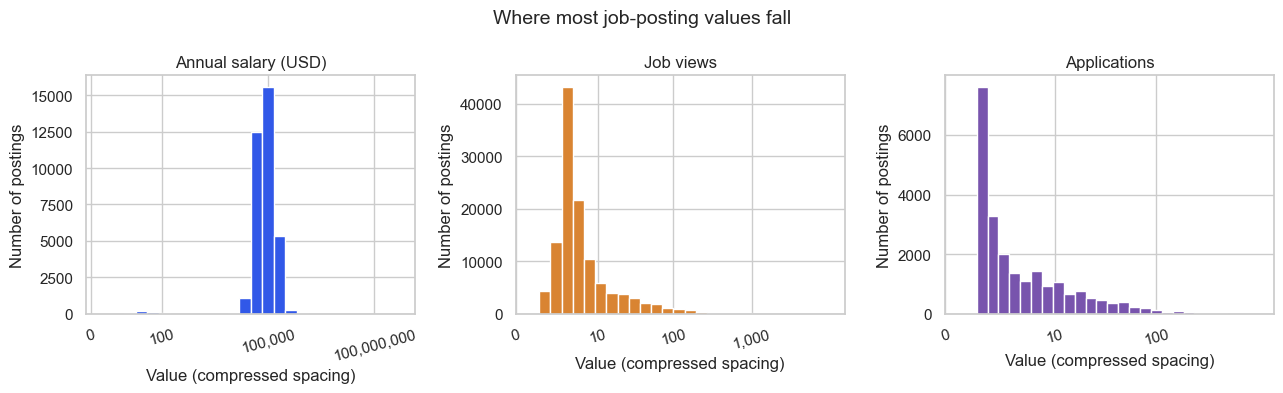

normalized_salary: 933 outliers
views: 16636 outliers
applies: 2849 outliers


In [10]:
num_cols = ['normalized_salary', 'views', 'applies']
titles = ['Annual salary (USD)', 'Job views', 'Applications']
colors = ['#3158E8', '#D98432', '#7854AD']
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, title, color in zip(axes, num_cols, titles, colors):
    values = jobs[col].dropna()
    values = values[values >= 0]
    # Compress the spacing, but label the axis with the original numbers.
    ax.hist(np.log1p(values), bins=26, color=color, edgecolor='white')
    ticks = [v for v in [0, 10, 100, 1000, 10000, 100000, 1000000,
                        10000000, 100000000, 1000000000] if v <= values.max()]
    ticks = np.asarray(ticks)[np.linspace(0, len(ticks)-1, min(4, len(ticks)), dtype=int)]
    ax.set_xticks(np.log1p(ticks), [f'{v:,.0f}' for v in ticks], rotation=15)
    ax.set_title(title)
    ax.set_xlabel('Value (compressed spacing)')
    ax.set_ylabel('Number of postings')
fig.suptitle('Where most job-posting values fall', fontsize=14)
plt.tight_layout(); plt.show()

for col in num_cols:
    q1, q3 = jobs[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((jobs[col] < q1 - 1.5*iqr) | (jobs[col] > q3 + 1.5*iqr)).sum()
    print(f"{col}: {n} outliers")

# log1p = log(1 + x)
jobs['log_salary'] = np.log1p(jobs['normalized_salary'])
jobs['log_views'] = np.log1p(jobs['views'])
jobs['log_applies'] = np.log1p(jobs['applies'])

### Stage 7: Standardise and normalise

Clean and join the title, description and skill text. Exclude descriptions shorter than 20 words as a research filter and report the count. The numerical scaling demonstrations are exploratory and do not train the text matcher.

In [20]:
jobs['title_clean'] = jobs['title'].apply(clean_text)
jobs['description_clean'] = jobs['description'].apply(clean_text)
jobs['skills_clean'] = jobs['skills_desc'].apply(clean_text)
jobs['job_text'] = (jobs['title_clean'] + ' ' + jobs['description_clean'] + ' ' + jobs['skills_clean']).str.strip()

jobs['word_count'] = jobs['description_clean'].str.split().str.len()
short = jobs['word_count'] < 20
print("Descriptions under 20 words:", short.sum())
jobs = jobs[~short].reset_index(drop=True)

# an internship is marked in work_type or in experience_level
jobs['is_internship'] = (jobs['work_type'] == 'INTERNSHIP') | (jobs['experience_level'] == 'Internship')
print("Internships:", jobs['is_internship'].sum())
log.append(('after removing short descriptions', len(jobs)))

print("BEFORE:", jobs.loc[0, 'description'][:200])
print("AFTER: ", jobs.loc[0, 'description_clean'][:200])

nums = jobs[['log_salary', 'log_views']].dropna()
std = pd.DataFrame(StandardScaler().fit_transform(nums), columns=nums.columns).describe().loc[['mean', 'std']]
mm = pd.DataFrame(MinMaxScaler().fit_transform(nums), columns=nums.columns).describe().loc[['min', 'max']]
print("Standard Scaler:"); display(std.round(2))
print("MinMax Scaler:");   display(mm.round(2))

Descriptions under 20 words: 212


Internships: 1842
BEFORE: Job descriptionA leading real estate firm in New Jersey is seeking an administrative Marketing Coordinator with some experience in graphic design. You will be working closely with our fun, kind, ambit
AFTER:  job descriptiona leading real estate firm in new jersey is seeking an administrative marketing coordinator with some experience in graphic design. you will be working closely with our fun kind ambitio
Standard Scaler:


,log_salary,log_views
mean,-0.0,0.0
std,1.0,1.0


MinMax Scaler:


,log_salary,log_views
min,0.0,0.0
max,1.0,1.0


### Save the cleaned data
We save the columns we need as job_postings_clean.csv, with a table of how many rows each stage removed.

In [21]:
keep = ['job_id', 'title', 'company_name', 'city', 'state', 'work_type', 'experience_level',
        'remote_allowed', 'listed_date', 'views', 'applies', 'normalized_salary', 'has_salary',
        'log_salary', 'log_views', 'log_applies', 'is_internship', 'word_count',
        'title_clean', 'job_text']

keep += [name for name in ['location', 'description_clean', 'skills_clean', 'application_url', 'job_posting_url', 'expiry', 'closed_time', 'currency', 'original_normalized_salary', 'salary_review_flag'] if name in jobs.columns]

out_file = os.path.join(OUT_DIR, 'job_postings_clean.csv')
jobs[keep].to_csv(out_file, index=False)
print("Saved:", out_file, jobs[keep].shape)

steps = pd.DataFrame(log, columns=['step', 'rows_left'])
steps['removed'] = (steps['rows_left'].shift() - steps['rows_left']).fillna(0).astype(int)
display(steps)

Saved: C:\Users\HAFSA\OneDrive - Strathmore University\Documents\ChatGPT\uplift\output\restored_notebook_validation\UpShift_Final_Output\clean\job_postings_clean.csv (118943, 30)


,step,rows_left,removed
0,raw file,123849,0
1,after removing duplicates,119162,4687
2,after flagging incorrect data,119162,0
3,after handling missing data,119155,7
4,after removing short descriptions,118943,212


### Load the cleaned data
We load job_postings_clean.csv, the file saved above. It has 110,939 postings and 20 columns.

In [22]:
#load the cleaned job postings
df_jobs = pd.read_csv(os.path.join(OUT_DIR, 'job_postings_clean.csv'), parse_dates=['listed_date'])
print(df_jobs.shape)

(118943, 30)


## 1.3 Skills dataset (ESCO): load the data
We load the ESCO skills list. Later we use it to find skills in resumes and job postings. We keep the raw table in skills_raw and clean a copy.

In [23]:
skills_raw = pd.read_csv(SKILLS_PATH, dtype=str)
print(skills_raw.shape)

(13960, 13)


### Check the data
We look at the first and last rows, the types and the missing values of the raw table.

In [24]:
display(skills_raw.head(10))
display(skills_raw.tail())
skills_raw.info()

,conceptType,conceptUri,skillType,reuseLevel,preferredLabel,altLabels,hiddenLabels,status,modifiedDate,scopeNote,definition,inScheme,description
0,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/0005c151-5b5a...,skill/competence,sector-specific,manage musical staff,manage music staff\ncoordinate duties of music...,NaN,released,2023-11-30T15:53:37.136Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,Assign and manage staff tasks in areas such as...
1,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/00064735-8fad...,skill/competence,occupation-specific,supervise correctional procedures,manage prison procedures\nmonitor correctional...,NaN,released,2023-11-30T15:04:00.689Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,Supervise the operations of a correctional fac...
2,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/000709ed-2be5...,skill/competence,sector-specific,apply anti-oppressive practices,make use of anti-oppressive practices\nuse ant...,NaN,released,2023-11-28T10:45:53.54Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,"Identify oppression in societies, economies, c..."
3,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/0007bdc2-dd15...,skill/competence,sector-specific,control compliance of railway vehicles regulat...,checking compliance with rolling stock regulat...,NaN,released,2023-11-30T16:29:18.273Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,"Inspect rolling stock, components and systems ..."
4,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/00090cc1-1f27...,skill/competence,cross-sector,identify available services,determine available services\nclassify availab...,NaN,released,2023-11-28T10:38:49.206Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,Identify the different services available for ...
5,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/000bb1e4-89f0...,skill/competence,cross-sector,perform toxicological studies,carry out toxicological studies\napply toxicol...,NaN,released,2023-11-30T15:10:42.752Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,Perform tests to detect poisons or drug misuse...
6,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/000c94d2-2a2e...,skill/competence,occupation-specific,ensure coquille uniformity,ensuring coquille is uniform\nmake sure coquil...,NaN,released,2023-11-30T16:49:26.078Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,Oversee uniformity of coquilles; use casting e...
7,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/000f1d3d-220f...,knowledge,sector-specific,Haskell,Haskell techniques,NaN,released,2023-11-30T16:13:21.77Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,The techniques and principles of software deve...
8,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/001115fb-569f...,skill/competence,transversal,show initiative,initiate action\nbe a driving force\ngive impe...,active participation\nactivity\ninitiative\ngr...,released,2021-09-02T16:37:00.315Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,Be proactive and take the first step in an act...
9,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/001d46db-035e...,skill/competence,sector-specific,train staff to reduce food waste,teach students food waste reduction practices\...,NaN,released,2021-01-20T14:31:01.524Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,Establish new trainings and staff development ...


,conceptType,conceptUri,skillType,reuseLevel,preferredLabel,altLabels,hiddenLabels,status,modifiedDate,scopeNote,definition,inScheme,description
13955,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/ffef5eb3-a15e...,skill/competence,sector-specific,remediate healthcare user's occupational perfo...,restore healthcare user's occupational perform...,NaN,released,2024-02-09T17:29:15.235Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,"Remediate or restore the cognitive, sensorimot..."
13956,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/fff0b074-5a76...,skill/competence,sector-specific,install transport equipment lighting,build in transport equipment lighting\nfix tra...,NaN,released,2024-02-09T17:29:14.494Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,Install lighting elements in transport equipme...
13957,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/fff0e2cd-d0bd...,knowledge,sector-specific,natural language processing,NLP,NaN,released,2024-02-09T17:29:15.235Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,The technologies which enable ICT devices to u...
13958,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/fff5bc45-b506...,skill/competence,cross-sector,coordinate construction activities,coordination of construction activity\nreview ...,NaN,released,2024-02-09T17:29:13.7Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,Coordinate the activities of several construct...
13959,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/fff74a70-4f82...,skill/competence,cross-sector,position guardrails and toeboards,attaching guardrails and toeboards\nattachment...,NaN,released,2024-02-09T17:29:10.678Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,Attach guardrails and toeboards to the scaffol...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13960 entries, 0 to 13959
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   conceptType     13960 non-null  object
 1   conceptUri      13960 non-null  object
 2   skillType       13955 non-null  object
 3   reuseLevel      13955 non-null  object
 4   preferredLabel  13960 non-null  object
 5   altLabels       13942 non-null  object
 6   hiddenLabels    153 non-null    object
 7   status          13960 non-null  object
 8   modifiedDate    13960 non-null  object
 9   scopeNote       236 non-null    object
 10  definition      2 non-null      object
 11  inScheme        13960 non-null  object
 12  description     13960 non-null  object
dtypes: object(13)
memory usage: 1.4+ MB


In [25]:
display(skills_raw.describe(include=object).T[['count', 'unique', 'freq']])

# % missing in each column
print((skills_raw.isna().mean()*100).round(1).sort_values(ascending=False))

,count,unique,freq
conceptType,13960,1,13960
conceptUri,13960,13939,2
skillType,13955,2,10734
reuseLevel,13955,4,6667
preferredLabel,13960,13939,2
altLabels,13942,13918,2
hiddenLabels,153,153,1
status,13960,1,13960
modifiedDate,13960,2669,925
scopeNote,236,224,5


definition        100.0
hiddenLabels       98.9
scopeNote          98.3
altLabels           0.1
conceptType         0.0
preferredLabel      0.0
reuseLevel          0.0
skillType           0.0
conceptUri          0.0
modifiedDate        0.0
status              0.0
inScheme            0.0
description         0.0
dtype: float64


### Stage 1: Duplicates
We start from a fresh copy of the raw table. A skill is the same skill if it has the same conceptUri, so we remove repeated URIs. 21 skills were repeated, which leaves 13,939 skills. To redo the cleaning from scratch, rerun this cell and the cells after it.

In [26]:
# fresh copy: rerunning this cell restarts the cleaning
skills = skills_raw.copy()
skills_log = [('raw file', len(skills))]

print('Duplicate rows:', skills.duplicated().sum())
print('Repeated conceptUri (same skill twice):', skills['conceptUri'].duplicated().sum())
print('Repeated preferredLabel:', skills['preferredLabel'].duplicated().sum())

skills = skills.drop_duplicates(subset='conceptUri').reset_index(drop=True)
skills_log.append(('after removing duplicates', len(skills)))

Duplicate rows:

 0
Repeated conceptUri (same skill twice): 21
Repeated preferredLabel: 21


### Stage 2: Irrelevant data
We keep only released skills and drop columns we will not use (type, scheme, date, status, notes, definition). All 13,939 skills are released, so no rows are removed here, only columns.

In [27]:
print(skills['conceptType'].value_counts())
print(skills['status'].value_counts())

skills = skills[skills['status'] == 'released']

irrelevant = ['conceptType', 'inScheme', 'modifiedDate', 'status', 'scopeNote', 'definition']
skills = skills.drop(columns=irrelevant, errors='ignore').reset_index(drop=True)
skills_log.append(('after removing irrelevant data', len(skills)))
print(skills.columns.tolist())

conceptType
KnowledgeSkillCompetence    13939
Name: count, dtype: int64
status
released    13939
Name: count, dtype: int64
['conceptUri', 'skillType', 'reuseLevel', 'preferredLabel', 'altLabels', 'hiddenLabels', 'description']


### Stage 3: Incorrect data
We remove skills with a blank label, a label with no letters, a wrong URI, or a skill type or reuse level that is not in the ESCO list.

In [28]:
ALLOWED_TYPES = {'skill/competence', 'knowledge'}
ALLOWED_REUSE = {'sector-specific', 'cross-sector', 'occupation-specific', 'transversal'}

blank_label = skills['preferredLabel'].isna() | (skills['preferredLabel'].str.strip() == '')
no_letters  = ~skills['preferredLabel'].fillna('').str.contains('[A-Za-z]')
bad_uri     = ~skills['conceptUri'].str.startswith('http://data.europa.eu/esco/skill/', na=False)
bad_type    = skills['skillType'].notna() & ~skills['skillType'].isin(ALLOWED_TYPES)
bad_reuse   = skills['reuseLevel'].notna() & ~skills['reuseLevel'].isin(ALLOWED_REUSE)

print('Blank labels:', blank_label.sum())
print('Labels with no letters:', no_letters.sum())
print('Wrong URI:', bad_uri.sum())
print('Unknown skill type:', bad_type.sum())
print('Unknown reuse level:', bad_reuse.sum())

bad = blank_label | no_letters | bad_uri | bad_type | bad_reuse
skills = skills[~bad].reset_index(drop=True)
skills_log.append(('after removing incorrect data', len(skills)))

Blank labels:

 0
Labels with no letters: 0
Wrong URI: 0
Unknown skill type: 0
Unknown reuse level: 0


### Stage 4: Structural errors
We remove stray spaces, give the category columns one format, and rename the columns.

In [29]:
text_cols = skills.select_dtypes(include=['object', 'string']).columns
for c in text_cols:
    skills[c] = skills[c].str.strip()

# stray spaces around the line breaks inside the synonym lists
for c in ['altLabels', 'hiddenLabels']:
    skills[c] = skills[c].str.replace(r'[ \t]*\n[ \t]*', '\n', regex=True)

# one format for the category columns
for c in ['skillType', 'reuseLevel']:
    skills[c] = skills[c].str.lower().str.replace(r'[^a-z0-9]+', '_', regex=True)

skills = skills.rename(columns={'conceptUri': 'skill_uri', 'preferredLabel': 'skill',
                                'altLabels': 'synonyms', 'hiddenLabels': 'hidden_labels',
                                'skillType': 'skill_type', 'reuseLevel': 'reuse_level'})
print(skills['skill_type'].value_counts(dropna=False))
print(skills['reuse_level'].value_counts(dropna=False))

skill_type
skill_competence    10715
knowledge            3219
NaN                     5
Name: count, dtype: int64
reuse_level
sector_specific        6655
cross_sector           3783
occupation_specific    3044
transversal             452
NaN                       5
Name: count, dtype: int64


### Stage 5: Missing data
We remove skills with no name or no description (none were missing). 5 skills have no skill type and no reuse level, and they become "not_stated". 13,786 skills have no hidden labels and 18 have no synonyms, and these become empty text.

In [30]:
text_cols = skills.select_dtypes(include=['object', 'string']).columns
skills[text_cols] = skills[text_cols].replace('', np.nan)

missing = skills.isna().sum()
print(missing[missing > 0])

# which skills have no type or level?
display(skills[skills['skill_type'].isna() | skills['reuse_level'].isna()][['skill', 'skill_type', 'reuse_level']])

skill_type           5
reuse_level          5
synonyms            18
hidden_labels    13786
dtype: int64


,skill,skill_type,reuse_level
3621,ICT safety,NaN,NaN
4790,digital communication and collaboration,NaN,NaN
5420,digital data processing,NaN,NaN
6949,problem-solving with digital tools,NaN,NaN
13326,digital content creation,NaN,NaN


In [31]:
skills = skills.dropna(subset=['skill', 'description'])
skills['skill_type']    = skills['skill_type'].fillna('not_stated')
skills['reuse_level']   = skills['reuse_level'].fillna('not_stated')
skills['synonyms']      = skills['synonyms'].fillna('')
skills['hidden_labels'] = skills['hidden_labels'].fillna('')
skills = skills.reset_index(drop=True)
skills_log.append(('after handling missing data', len(skills)))
print(skills.isna().sum().sum(), 'missing values left')

0 missing values left


### Stage 6: Outliers

Inspect unusually long skill names and large synonym counts. We retain valid long names rather than treating length as an error.

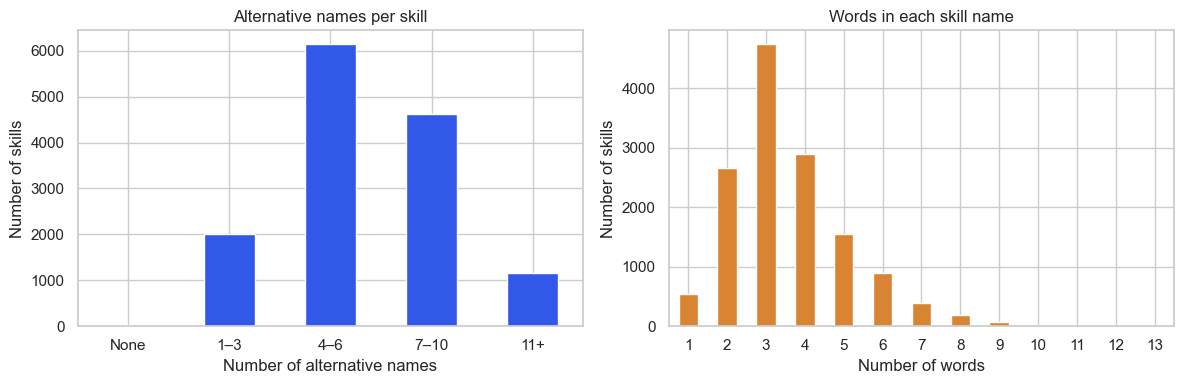

n_synonyms: 139 outliers
one word: 548 | six words or more: 1563
label_words: 2111 outliers
one word: 548 | six words or more: 1563


,skill,n_synonyms
9140,graphics editor software,78
1825,computer programming,55
12258,sign language,52
9347,database management systems,46
13823,use personal organization software,45


,skill,label_words
13318,work to develop physical ability to perform at...,13
3443,implement relevant tactical skills to perform ...,12
4657,participate as observer in different types of ...,12
5828,undertake procedures to meet requirements for ...,12
6861,implement relevant technical skills to perform...,12


In [12]:
skills['n_synonyms']  = skills['synonyms'].map(lambda s: len([x for x in s.split('\n') if x.strip()]))
skills['label_words'] = skills['skill'].str.split().str.len()

# Group alternative-name counts so the comparison is easy to read.
synonym_groups = pd.cut(skills['n_synonyms'], bins=[-1, 0, 3, 6, 10, np.inf],
                         labels=['None', '1–3', '4–6', '7–10', '11+'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
synonym_groups.value_counts(sort=False).plot.bar(ax=axes[0], color='#3158E8', rot=0)
skills['label_words'].value_counts().sort_index().plot.bar(ax=axes[1], color='#D98432', rot=0)
axes[0].set_title('Alternative names per skill'); axes[0].set_xlabel('Number of alternative names')
axes[1].set_title('Words in each skill name'); axes[1].set_xlabel('Number of words')
for ax in axes: ax.set_ylabel('Number of skills')
plt.tight_layout(); plt.show()

for col in ['n_synonyms', 'label_words']:
    q1, q3 = skills[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((skills[col] < q1 - 1.5*iqr) | (skills[col] > q3 + 1.5*iqr)).sum()
    print(f"{col}: {n} outliers")
    print('one word:', (skills['label_words'] == 1).sum(), '| six words or more:', (skills['label_words'] >= 6).sum())

display(skills.nlargest(5, 'n_synonyms')[['skill', 'n_synonyms']])
display(skills.nlargest(5, 'label_words')[['skill', 'label_words']])
skills_log.append(('after checking outliers (none removed)', len(skills)))

### Stage 7: Standardise and normalise
We apply clean_text() to the skill names and add a log column for the synonym count. The scalers are shown only to check the numbers.

In [33]:
skills['skill_clean'] = skills['skill'].apply(clean_text)
skills['log_synonyms'] = np.log1p(skills['n_synonyms'])      # log1p = log(1 + x)

i = skills.index[skills['skill'].str.contains(r'[A-Z(]')][0]
print('BEFORE:', skills.loc[i, 'skill'])
print('AFTER: ', skills.loc[i, 'skill_clean'])
print('Names that became empty:', (skills['skill_clean'] == '').sum())

nums = skills[['log_synonyms', 'label_words']]
std = pd.DataFrame(StandardScaler().fit_transform(nums), columns=nums.columns).describe().loc[['mean', 'std']]
mm  = pd.DataFrame(MinMaxScaler().fit_transform(nums), columns=nums.columns).describe().loc[['min', 'max']]
print('Standard Scaler:'); display(std.round(2))
print('MinMax Scaler:');   display(mm.round(2))
skills_log.append(('after standardising', len(skills)))

BEFORE: Haskell
AFTER:  haskell
Names that became empty: 0
Standard Scaler:


,log_synonyms,label_words
mean,-0.0,-0.0
std,1.0,1.0


MinMax Scaler:


,log_synonyms,label_words
min,0.0,0.0
max,1.0,1.0


### Save the cleaned data
We save the cleaned skills as esco_skills_clean.csv.

In [34]:
keep = ['skill_uri', 'skill', 'skill_clean', 'synonyms', 'hidden_labels', 'skill_type', 'reuse_level',
        'description', 'n_synonyms', 'label_words', 'log_synonyms']

out_file = os.path.join(OUT_DIR_SKILLS, 'esco_skills_clean.csv')
skills[keep].to_csv(out_file, index=False)
print('Saved:', out_file, skills[keep].shape)

steps = pd.DataFrame(skills_log, columns=['step', 'rows_left'])
steps['removed'] = (steps['rows_left'].shift() - steps['rows_left']).fillna(0).astype(int)
display(steps)

Saved: C:\Users\HAFSA\OneDrive - Strathmore University\Documents\ChatGPT\uplift\output\restored_notebook_validation\UpShift_Final_Output\clean\esco_skills_clean.csv (13939, 11)


,step,rows_left,removed
0,raw file,13960,0
1,after removing duplicates,13939,21
2,after removing irrelevant data,13939,0
3,after removing incorrect data,13939,0
4,after handling missing data,13939,0
5,after checking outliers (none removed),13939,0
6,after standardising,13939,0


### Skill lookup

Combine official skill names, synonyms and hidden labels. Keep useful technical names such as C++, C# and .NET. Exclude spellings linked to several different skills instead of guessing which one they mean.

The chart checks six example spellings in this original ESCO-only lookup. “Not found” means this lookup did not recognise that spelling. The live app adds explicit technical names in Section 5.

In [35]:
lookup_rows = []
for r in skills.itertuples(index=False):
    meta = dict(canonical=r.skill, uri=r.skill_uri, skill_type=r.skill_type)
    lookup_rows.append(dict(label=r.skill, label_kind='preferred', **meta))
    for field, kind in ((r.synonyms, 'alt'), (r.hidden_labels, 'hidden')):
        for lab in field.split('\n'):
            if lab.strip():
                lookup_rows.append(dict(label=lab.strip(), label_kind=kind, **meta))

lookup = pd.DataFrame(lookup_rows)
lookup['label_norm'] = lookup['label'].apply(clean_text)
lookup = lookup[lookup['label_norm'] != '']
# remove spellings of 1 or 2 letters (they match inside ordinary text), but keep c#
lookup = lookup[(lookup['label_norm'].str.len() > 2) | lookup['label_norm'].isin(['c#', 'c++', '.net'])]
print('spellings:', len(lookup))

spellings: 101463


spellings pointing at more than one skill: 715


unique spellings kept: 99389


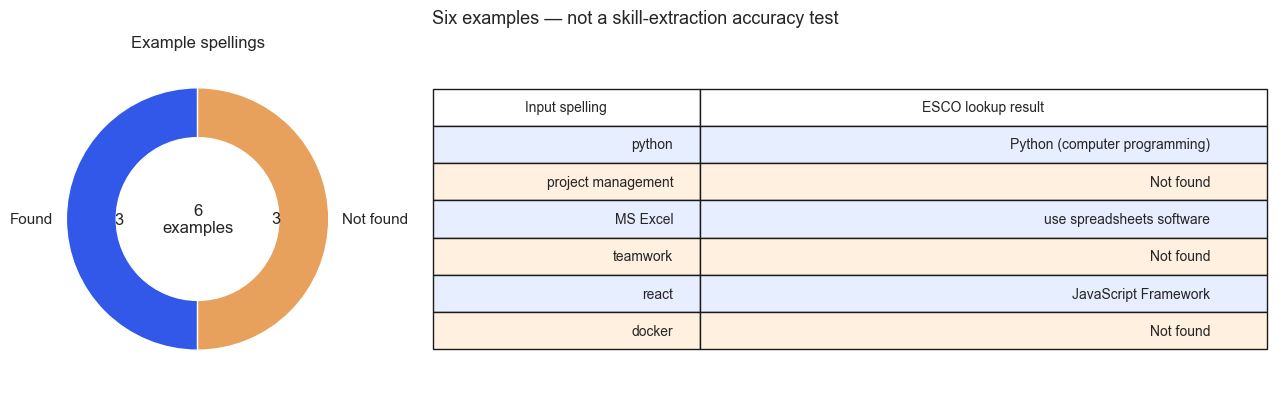

In [14]:
# The same cleaned spelling can point at more than one skill (a "clash").
# Exclude spellings pointing to different skills; prefer official names among equivalent entries.
clashes = lookup.groupby('label_norm')['uri'].nunique()
print('spellings pointing at more than one skill:', (clashes > 1).sum())

# Exclude genuinely ambiguous spellings instead of choosing an arbitrary skill.
lookup = lookup[lookup['label_norm'].isin(clashes[clashes == 1].index)].copy()

kind_rank = {'preferred': 0, 'alt': 1, 'hidden': 2}
lookup = (lookup.assign(_o=lookup['label_kind'].map(kind_rank))
                .sort_values(['label_norm', '_o', 'canonical'])
                .drop_duplicates('label_norm')
                .drop(columns='_o')
                .reset_index(drop=True))
print('unique spellings kept:', len(lookup))

lookup_dict = dict(zip(lookup['label_norm'], lookup['canonical']))   # cleaned phrase -> official skill name
lookup.to_csv(os.path.join(OUT_DIR_SKILLS, 'esco_lookup.csv'), index=False)

# Check six spellings in the original ESCO-only lookup.
examples = ['python', 'project management', 'MS Excel', 'teamwork', 'react', 'docker']
lookup_results = [(term, lookup_dict.get(clean_text(term))) for term in examples]
found_count = sum(result is not None for _, result in lookup_results)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios':[1, 2.5]})
axes[0].pie([found_count, len(examples)-found_count], labels=['Found', 'Not found'],
            colors=['#3158E8', '#E8A15D'], startangle=90,
            wedgeprops={'width':.38, 'edgecolor':'white'},
            autopct=lambda percent: f'{percent*len(examples)/100:.0f}')
axes[0].text(0, 0, '6\nexamples', ha='center', va='center')
axes[0].set_title('Example spellings')
axes[1].axis('off')
table = axes[1].table(cellText=[[term, result or 'Not found'] for term, result in lookup_results],
    colLabels=['Input spelling', 'ESCO lookup result'], colWidths=[.32, .68], loc='center',
    cellColours=[['#E7EEFF' if result else '#FFF0E0']*2 for _, result in lookup_results])
table.auto_set_font_size(False); table.set_fontsize(10); table.scale(1, 2.1)
fig.suptitle('Six examples — not a skill-extraction accuracy test', fontsize=13)
plt.tight_layout(); plt.show()


### Load the cleaned data
We load esco_skills_clean.csv, the file saved above.

In [37]:
# load the cleaned skills
df_skills = pd.read_csv(os.path.join(OUT_DIR_SKILLS, 'esco_skills_clean.csv')).fillna({'synonyms': '', 'hidden_labels': ''})
print(df_skills.shape)

(13939, 11)


# 2. Exploratory data analysis

Before building a model, we look at each dataset on its own, then at all of them together. Each part ends with a short list of what we noticed.

## 2.1 Resumes
We look at the cleaned resumes to answer four questions: are the categories balanced, how long are the resumes, which words tell the categories apart, and do these resumes look like student resumes?

### Load the cleaned data

We load resume_clean.csv, the file saved in the cleaning section.

In [38]:
#load the cleaned resumes
df_resumes = pd.read_csv(os.path.join(OUT_DIR, 'resume_clean.csv'))
print(df_resumes.shape)

(2481, 5)


### Resumes per category

Plot the number of CVs in each category. The actual cleaned counts are shown below.

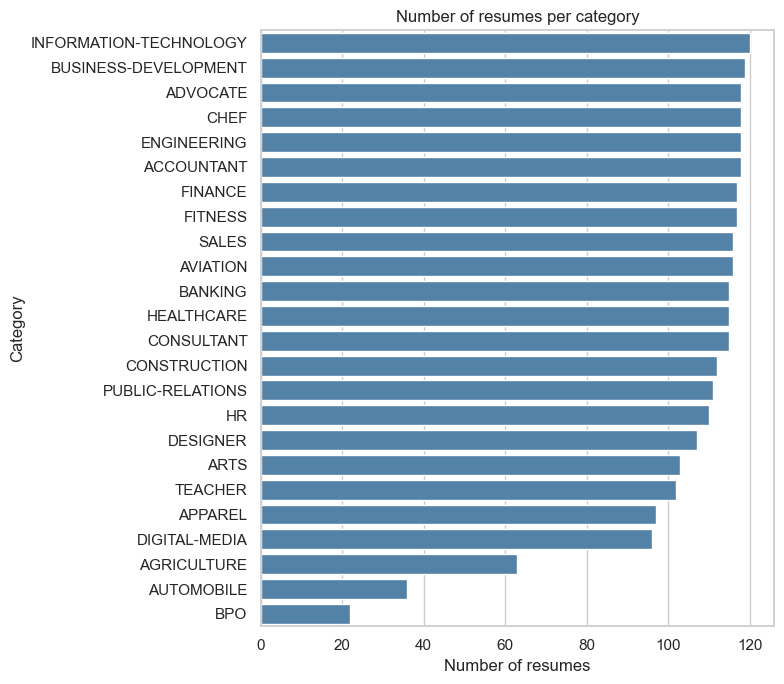

In [39]:
counts = df_resumes['Category'].value_counts()

plt.figure(figsize=(8,7))
sns.barplot(x=counts.values, y=counts.index, color='steelblue')
plt.xlabel('Number of resumes')
plt.ylabel('Category')
plt.title('Number of resumes per category')
plt.tight_layout()
plt.show()


### How long are the resumes?

Count words in each CV and inspect the distribution. Very short or long documents may need a closer look.

count    2481.000000
mean      787.993148
std       369.338888
min        93.000000
25%       629.000000
50%       734.000000
75%       906.000000
max      5172.000000
Name: word_count, dtype: float64


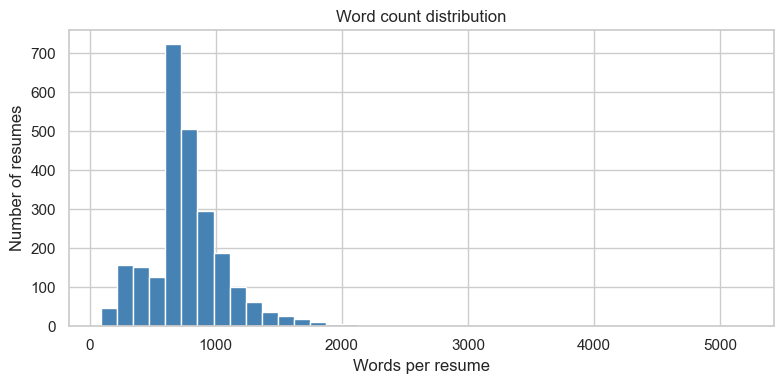

          Category  word_count
1929  CONSTRUCTION          93
1048         SALES         107
130       DESIGNER         108
153       DESIGNER         110
1101         SALES         122


In [40]:
#number of words in each resume
df_resumes['word_count'] = df_resumes['Resume_clean'].str.split().str.len()
print(df_resumes['word_count'].describe())

plt.figure(figsize=(8,4))
plt.hist(df_resumes['word_count'], bins=40, color='steelblue')
plt.xlabel('Words per resume')
plt.ylabel('Number of resumes')
plt.title('Word count distribution')
plt.tight_layout()
plt.show()

#5 shortest resumes
print(df_resumes.nsmallest(5, 'word_count')[['Category', 'word_count']])

### Common words in the CVs

Larger words appear more often in the cleaned CVs. Common English words and terms appearing in almost every CV are excluded. This shows vocabulary, not document length or which skills a student should learn. The previous histogram still shows CV lengths.

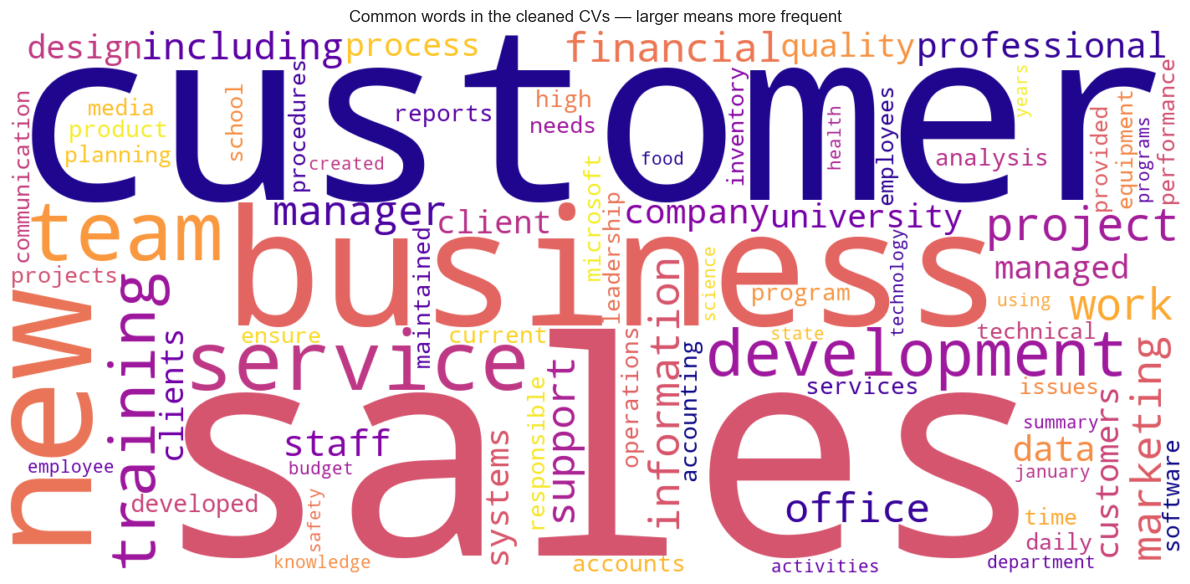

In [16]:
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer

cloud_counter = CountVectorizer(stop_words='english', min_df=5, max_df=.8, max_features=2000,
                               token_pattern=r'(?u)\b[a-z][a-z]+\b')
cloud_matrix = cloud_counter.fit_transform(df_resumes['Resume_clean'])
cloud_frequencies = dict(zip(cloud_counter.get_feature_names_out(),
                            np.asarray(cloud_matrix.sum(axis=0)).ravel()))
cloud = WordCloud(width=1400, height=650, background_color='white', max_words=80,
                  colormap='plasma', random_state=42).generate_from_frequencies(cloud_frequencies)
plt.figure(figsize=(13, 6))
plt.imshow(cloud, interpolation='bilinear'); plt.axis('off')
plt.title('Common words in the cleaned CVs — larger means more frequent')
plt.tight_layout(); plt.show()


### Strongest words in each category

The bars show five words with the highest average TF-IDF weights in each category. TF-IDF gives more weight to words that help distinguish documents; longer bars mean higher average weight. This is exploration of all CVs. Model training later learns word weights from its training portion only.

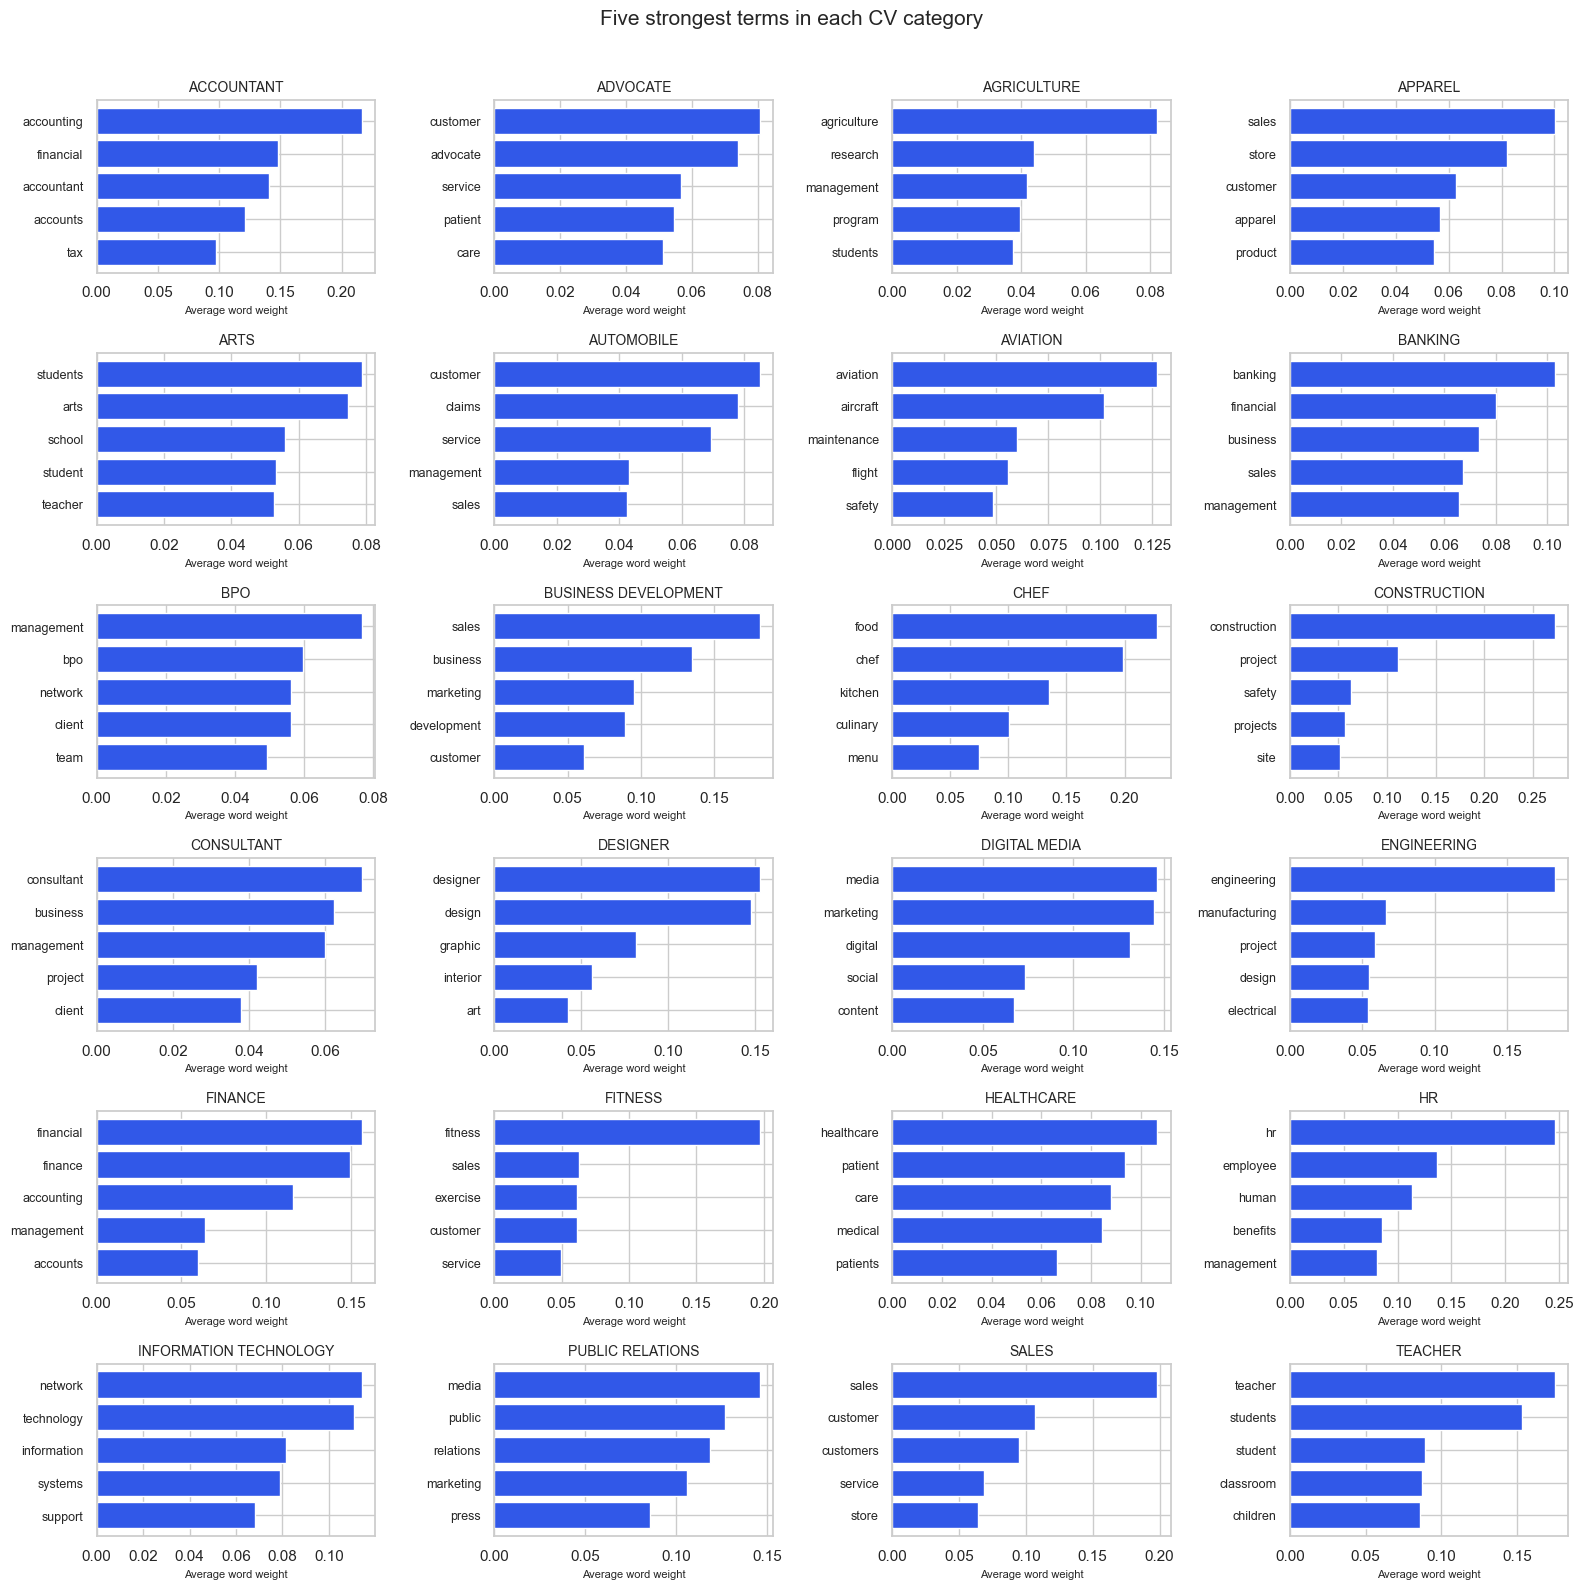

In [17]:

# ignore common English words and words found in fewer than 5 resumes
vec = TfidfVectorizer(stop_words='english', min_df=5, max_features=5000)
X = vec.fit_transform(df_resumes['Resume_clean'])
words = vec.get_feature_names_out()

top_words = {}
for cat in sorted(df_resumes['Category'].unique()):
    rows = (df_resumes['Category'] == cat).values
    avg = np.asarray(X[rows].mean(axis=0)).ravel()   # average score of each word
    top_words[cat] = list(words[avg.argsort()[::-1][:10]])

# Show five terms per category; retain all ten above for the later comparisons.
categories_to_plot = sorted(top_words)
fig, axes = plt.subplots(int(np.ceil(len(categories_to_plot)/4)), 4,
                         figsize=(16, 2.7*int(np.ceil(len(categories_to_plot)/4))))
for ax, cat in zip(axes.flat, categories_to_plot):
    rows = (df_resumes['Category'] == cat).values
    avg = np.asarray(X[rows].mean(axis=0)).ravel()
    best = avg.argsort()[-5:][::-1]
    ax.barh(range(5), avg[best], color='#3158E8')
    ax.set_yticks(range(5), words[best], fontsize=9); ax.invert_yaxis()
    ax.set_title(cat.replace('-', ' '), fontsize=10)
    ax.set_xlabel('Average word weight', fontsize=8)
for ax in axes.flat[len(categories_to_plot):]: ax.set_visible(False)
fig.suptitle('Five strongest terms in each CV category', fontsize=15)
plt.tight_layout(rect=[0, 0, 1, .97]); plt.show()


### Words shared by many categories

Count terms that appear among the top words of many categories. Broadly shared words may be less useful for distinguishing fields.

[('management', 15), ('customer', 12), ('sales', 12), ('service', 5), ('business', 5), ('health', 4), ('project', 4), ('client', 4), ('marketing', 4), ('financial', 3)]


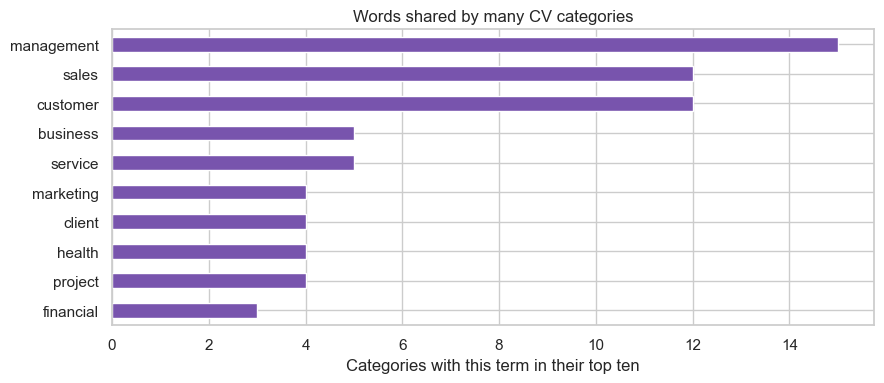

In [6]:
from collections import Counter

# in how many categories is each word in the top 10?
shared = Counter(w for lst in top_words.values() for w in lst)
print(shared.most_common(10))

pd.Series(dict(shared.most_common(10))).sort_values().plot.barh(figsize=(9,4), color='#7854AD')
plt.xlabel('Categories with this term in their top ten'); plt.title('Words shared by many CV categories')
plt.tight_layout(); plt.show()

### Does the title give away the category?
For each resume we check if a word from the category name is in the job title at the top.

0.65
Category
AGRICULTURE               0.03
AUTOMOBILE                0.06
APPAREL                   0.07
BPO                       0.09
ARTS                      0.19
AVIATION                  0.22
FITNESS                   0.22
BANKING                   0.27
HEALTHCARE                0.34
PUBLIC-RELATIONS          0.38
ADVOCATE                  0.69
CONSTRUCTION              0.70
DIGITAL-MEDIA             0.71
INFORMATION-TECHNOLOGY    0.74
CHEF                      0.81
TEACHER                   0.97
CONSULTANT                0.98
DESIGNER                  0.99
HR                        0.99
SALES                     0.99
ACCOUNTANT                0.99
BUSINESS-DEVELOPMENT      1.00
ENGINEERING               1.00
FINANCE                   1.00
Name: title_has_category, dtype: float64


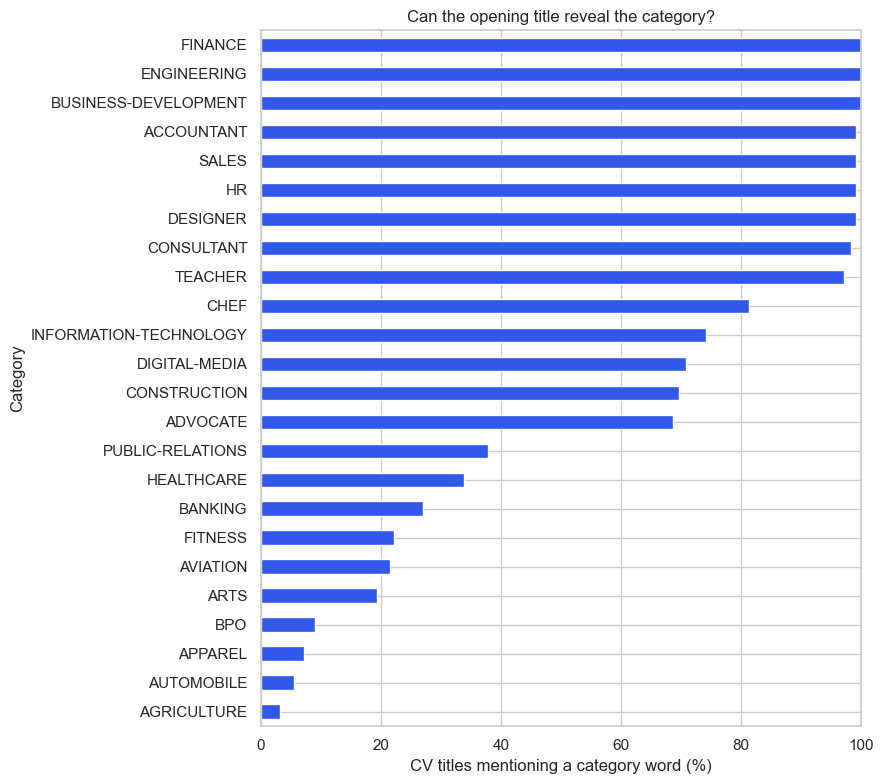

In [7]:
# does a word from the category name appear in the title?
titles = df_resumes['Resume_title'].fillna('').str.lower()
df_resumes['title_has_category'] = [any(w in t for w in c.lower().split('-'))
                                    for t, c in zip(titles, df_resumes['Category'])]
print(df_resumes['title_has_category'].mean().round(2))
print(df_resumes.groupby('Category')['title_has_category'].mean().sort_values().round(2))

(df_resumes.groupby('Category')['title_has_category'].mean().sort_values()*100).plot.barh(figsize=(9,8), color='#3158E8')
plt.xlabel('CV titles mentioning a category word (%)'); plt.xlim(0,100)
plt.title('Can the opening title reveal the category?'); plt.tight_layout(); plt.show()

### Which categories use similar words?
We average the word scores of each category and measure how close each pair is. Pairs with a high score are the ones the model may mix up.

ADVOCATE              HEALTHCARE                0.84
ACCOUNTANT            FINANCE                   0.84
APPAREL               SALES                     0.84
ARTS                  TEACHER                   0.80
CONSULTANT            INFORMATION-TECHNOLOGY    0.78
DIGITAL-MEDIA         PUBLIC-RELATIONS          0.77
ADVOCATE              AUTOMOBILE                0.77
BUSINESS-DEVELOPMENT  CONSULTANT                0.77
dtype: float64


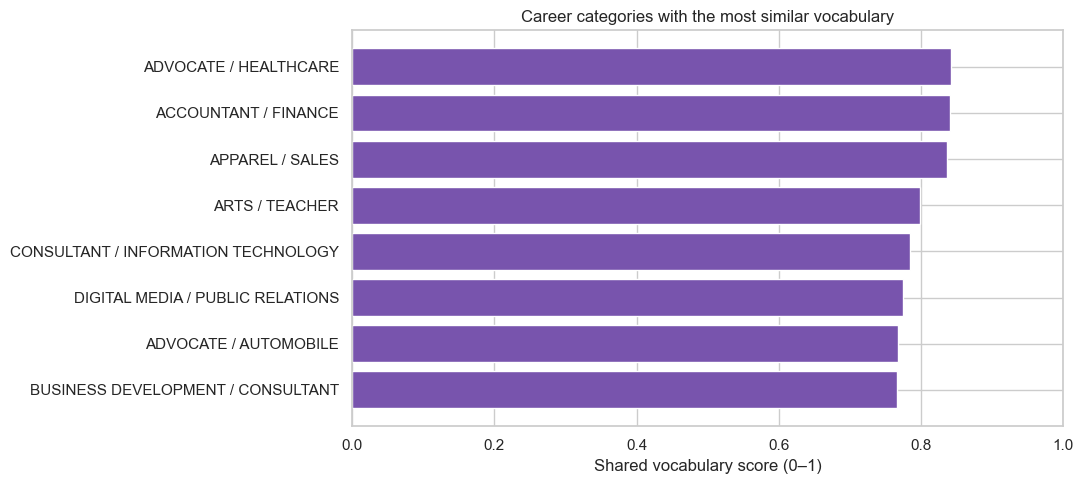

In [8]:
from sklearn.metrics.pairwise import cosine_similarity

cats = sorted(df_resumes['Category'].unique())
centroids = np.vstack([np.asarray(X[(df_resumes['Category'] == c).values].mean(axis=0)).ravel() for c in cats])
sim = pd.DataFrame(cosine_similarity(centroids), index=cats, columns=cats)
pairs = sim.where(np.triu(np.ones(sim.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
print(pairs.head(8).round(2))

pair_scores = pairs.head(8).iloc[::-1]
pair_labels = [a.replace('-', ' ')+' / '+b.replace('-', ' ') for a,b in pair_scores.index]
plt.figure(figsize=(11,5)); plt.barh(pair_labels, pair_scores.values, color='#7854AD')
plt.xlim(0,1); plt.xlabel('Shared vocabulary score (0–1)')
plt.title('Career categories with the most similar vocabulary'); plt.tight_layout(); plt.show()

### Are these resumes like student resumes?
Our app is for students looking for internships. We check the job titles at the top and the years of experience the resumes claim.

Senior-sounding titles: 795 of 2439
Junior-sounding titles: 190


count    864.0
mean      12.0
std        8.0
min        2.0
25%        5.0
50%       10.0
75%       16.0
max       50.0
Name: 0, dtype: float64


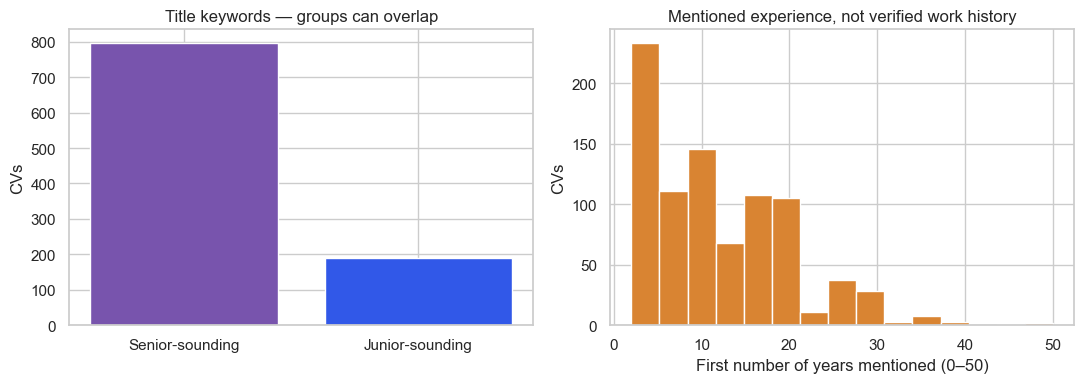

In [9]:
senior = titles.str.contains(r'manager|director|senior|executive|head|chief|lead|supervisor')
junior = titles.str.contains(r'intern|trainee|junior|assistant|entry|student|graduate')
print('Senior-sounding titles:', senior.sum(), 'of', (titles != '').sum())
print('Junior-sounding titles:', junior.sum())

# years of experience claimed (first "N years" in the text)
years = df_resumes['Resume_clean'].str.extract(r'(\d+)\+?\s*years')[0].astype(float)
print(years[years <= 50].describe().round(1))

fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].bar(['Senior-sounding','Junior-sounding'], [int(senior.sum()),int(junior.sum())], color=['#7854AD','#3158E8'])
axes[0].set_ylabel('CVs'); axes[0].set_title('Title keywords — groups can overlap')
axes[1].hist(years[years<=50].dropna(), bins=15, color='#D98432', edgecolor='white')
axes[1].set_xlabel('First number of years mentioned (0–50)'); axes[1].set_ylabel('CVs')
axes[1].set_title('Mentioned experience, not verified work history')
plt.tight_layout(); plt.show()

In [47]:
x = df_resumes[(df_resumes['Category']=='CHEF') & df_resumes['Resume_clean'].str.contains('nursing student')]
print(x[['ID']].head()); print(x['Resume_clean'].str[:200].head(2).tolist())

            ID
1356  15180322
['chef career focus i am a nursing student who has recently obtained my cna license in this state. i worked as a gna in the uk and it has been a passion ever since. i am confident that i would make a wo']


### What we noticed (resumes)

Compare category sizes, CV lengths and title overlap. Uneven groups and near copies can make model scores misleading.

## 2.2 Job postings
We look at the cleaned job postings to answer four questions: what kinds of jobs there are, how many are for beginners, how long the descriptions are, and whether they use the same words as the resumes.

### What kinds of jobs are there?
We count the postings by work type and by experience level.

work_type
FULL_TIME     94729
CONTRACT      11759
PART_TIME      9402
TEMPORARY      1155
INTERNSHIP      922
VOLUNTEER       518
OTHER           458
Name: count, dtype: int64 

experience_level
Mid-Senior level    39793
Entry level         34715
Not stated          28822
Associate            9459
Director             3598
Internship           1373
Executive            1183
Name: count, dtype: int64


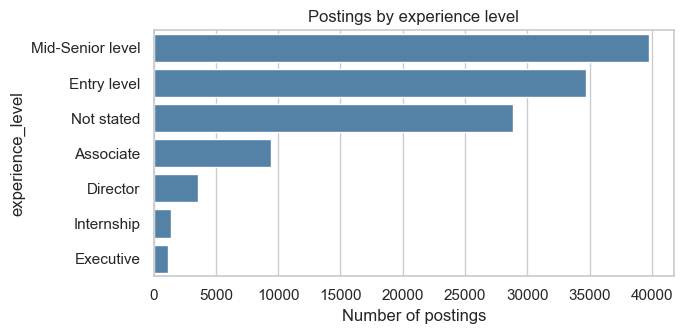

In [48]:
print(df_jobs['work_type'].value_counts(), '\n')
print(df_jobs['experience_level'].value_counts())

plt.figure(figsize=(7, 3.5))
sns.countplot(data=df_jobs, y='experience_level', order=df_jobs['experience_level'].value_counts().index, color='steelblue')
plt.xlabel('Number of postings'); plt.title('Postings by experience level')
plt.tight_layout(); plt.show()

### Jobs for beginners
Our students want internships and entry-level jobs, so we count them and look at their most common titles.

Internships: 1842
Internships or entry level: 36487 of 118943
title_clean
assistant store manager                     232
retail sales associate                      186
receptionist                                170
sales associate                             149
salesperson                                 131
maintenance technician                      102
administrative assistant                    100
patient care technician                      97
licensed therapist for online counseling     94
sales specialist                             86
Name: count, dtype: int64


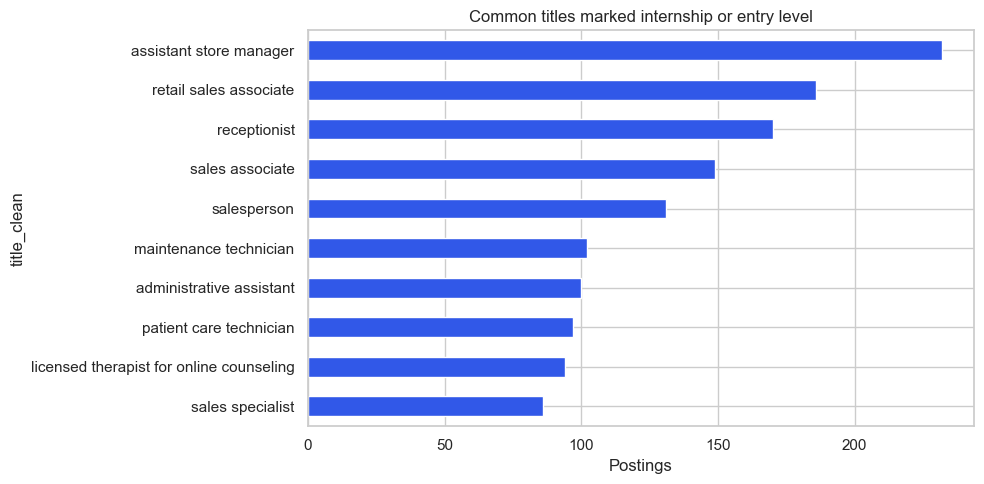

In [10]:
early = df_jobs['is_internship'] | (df_jobs['experience_level'] == 'Entry level')
print('Internships:', df_jobs['is_internship'].sum())
print('Internships or entry level:', early.sum(), 'of', len(df_jobs))
print(df_jobs.loc[early, 'title_clean'].value_counts().head(10))

df_jobs.loc[early,'title_clean'].value_counts().head(10).iloc[::-1].plot.barh(figsize=(10,5),color='#3158E8')
plt.xlabel('Postings'); plt.title('Common titles marked internship or entry level')
plt.tight_layout(); plt.show()

### How long are the descriptions?

Plot job-description lengths and compare them with CV lengths. Length differences can influence text representation and how much information is retained.

count    118943.0
mean        532.0
std         307.0
min          20.0
25%         302.0
50%         486.0
75%         707.0
max        3448.0
Name: word_count, dtype: float64
Resumes, middle length: 734.0


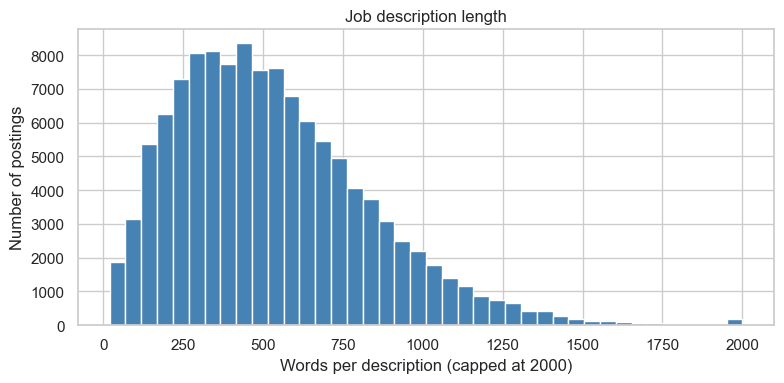

In [50]:
print(df_jobs['word_count'].describe().round(0))
print('Resumes, middle length:', df_resumes['word_count'].median())

plt.figure(figsize=(8, 4))
plt.hist(df_jobs['word_count'].clip(upper=2000), bins=40, color='steelblue')
plt.xlabel('Words per description (capped at 2000)'); plt.ylabel('Number of postings')
plt.title('Job description length')
plt.tight_layout(); plt.show()

### Do jobs and resumes use the same words?
We find the top words in the beginner postings, and check what share of the posting vocabulary also appears in the resume vocabulary.

The chart compares the retained vocabularies, not every word or the skills possessed by an individual student.

Top words in beginner postings: ['work', 'experience', 'care', 'team', 'customer', 'sales', 'job', 'ability', 'company', 'service', 'required', 'skills', 'time', 'patient', 'customers']
Share of posting words also in resumes: 72.1 %


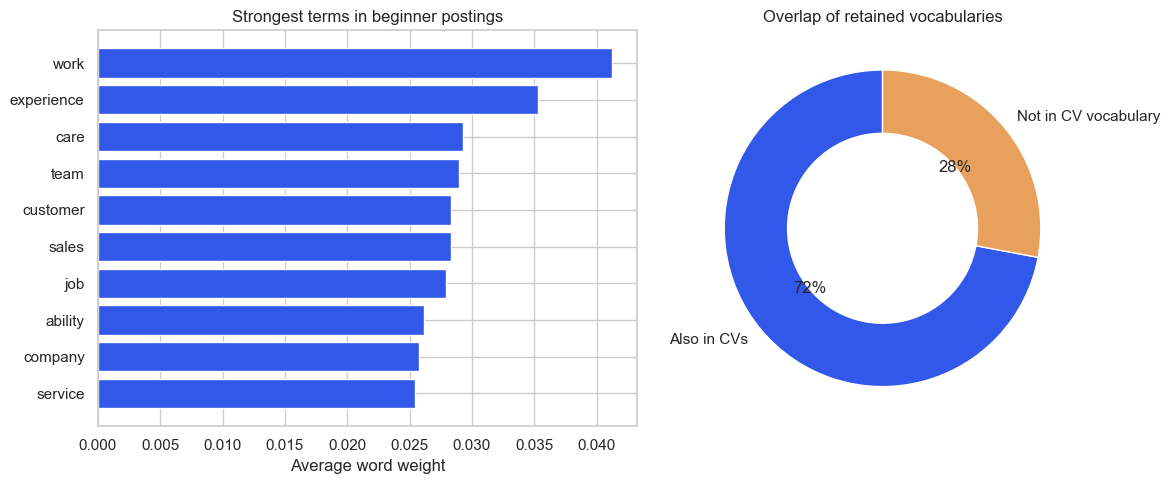

In [11]:
vec_j = TfidfVectorizer(stop_words='english', min_df=5, max_features=5000)
Xj = vec_j.fit_transform(df_jobs.loc[early, 'job_text'])
words_j = vec_j.get_feature_names_out()
avg_j = np.asarray(Xj.mean(axis=0)).ravel()
print('Top words in beginner postings:', list(words_j[avg_j.argsort()[::-1][:15]]))

resume_words = set(vec.get_feature_names_out())
print('Share of posting words also in resumes:', round(np.mean([w in resume_words for w in words_j]) * 100, 1), '%')

fig, axes = plt.subplots(1,2,figsize=(12,5),gridspec_kw={'width_ratios':[1.3,1]})
best_job_terms = avg_j.argsort()[-10:]
axes[0].barh(words_j[best_job_terms], avg_j[best_job_terms],color='#3158E8')
axes[0].set_xlabel('Average word weight'); axes[0].set_title('Strongest terms in beginner postings')
overlap_count = sum(word in resume_words for word in words_j)
axes[1].pie([overlap_count,len(words_j)-overlap_count],labels=['Also in CVs','Not in CV vocabulary'],
            autopct='%1.0f%%',startangle=90,colors=['#3158E8','#E8A15D'],wedgeprops={'width':.4,'edgecolor':'white'})
axes[1].set_title('Overlap of retained vocabularies')
plt.tight_layout(); plt.show()

### Where are the jobs?
The postings come from LinkedIn. We check how many have a US state, because our students are in Kenya.

A missing US-state suffix does not mean the posting is Kenyan or that a Kenyan applicant is eligible.

Postings with a US state: 0.85
state
CA    11191
TX     9847
NY     5841
FL     5699
NC     4753
Name: count, dtype: int64


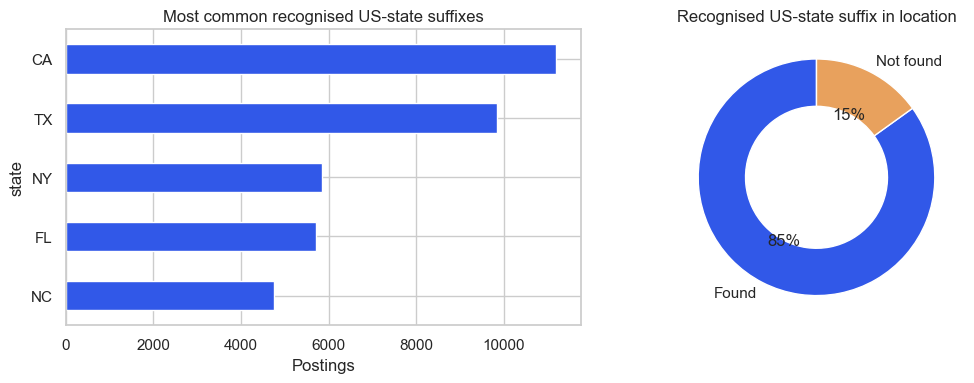

In [12]:
print('Postings with a US state:', df_jobs['state'].notna().mean().round(2))
print(df_jobs['state'].value_counts().head(5))

fig, axes = plt.subplots(1,2,figsize=(11,4))
df_jobs['state'].value_counts().head(5).iloc[::-1].plot.barh(ax=axes[0],color='#3158E8')
axes[0].set_xlabel('Postings'); axes[0].set_title('Most common recognised US-state suffixes')
has_state = int(df_jobs['state'].notna().sum())
axes[1].pie([has_state,len(df_jobs)-has_state],labels=['Found','Not found'],autopct='%1.0f%%',
            colors=['#3158E8','#E8A15D'],startangle=90,wedgeprops={'width':.4,'edgecolor':'white'})
axes[1].set_title('Recognised US-state suffix in location')
plt.tight_layout(); plt.show()

### What we noticed (job postings)

Check entry-level coverage, missing fields and geography. International research data cannot establish eligibility for Kenyan applicants.

## 2.3 Skills list
We look at the ESCO skills list to answer three questions: how are the skills described, how many ways is each skill written, and can the list find skills in our resumes and job postings?

### Skills per type and per reuse level

Count ESCO skill types and how broadly they apply across occupations.

skill_type
skill_competence    10715
knowledge            3219
not_stated              5
Name: count, dtype: int64 

reuse_level
sector_specific        6655
cross_sector           3783
occupation_specific    3044
transversal             452
not_stated                5
Name: count, dtype: int64


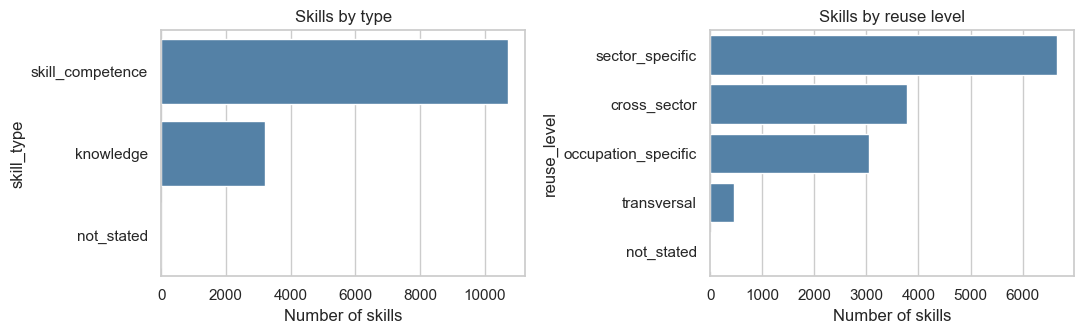

In [53]:
type_counts  = df_skills['skill_type'].value_counts()
reuse_counts = df_skills['reuse_level'].value_counts()
print(type_counts, '\n'); print(reuse_counts)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.barplot(x=type_counts.values, y=type_counts.index, color='steelblue', ax=axes[0])
axes[0].set_xlabel('Number of skills'); axes[0].set_title('Skills by type')
sns.barplot(x=reuse_counts.values, y=reuse_counts.index, color='steelblue', ax=axes[1])
axes[1].set_xlabel('Number of skills'); axes[1].set_title('Skills by reuse level')
plt.tight_layout()
plt.show()

### How many synonyms does a skill have?

Inspect the number of alternative names for each skill. Missing aliases can cause the lookup to miss wording used by students or employers.

count    13939.000000
mean         6.202310
std          3.093598
min          0.000000
25%          4.000000
50%          6.000000
75%          8.000000
max         78.000000
Name: n_synonyms, dtype: float64
Skills with no synonym: 18


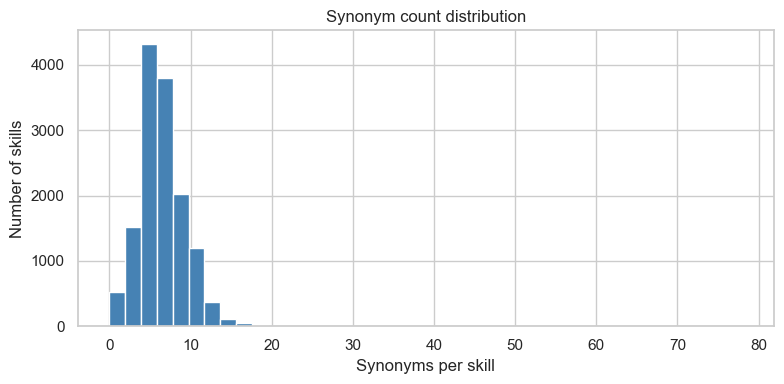

In [54]:
print(df_skills['n_synonyms'].describe())
print('Skills with no synonym:', (df_skills['n_synonyms'] == 0).sum())

plt.figure(figsize=(8, 4))
plt.hist(df_skills['n_synonyms'], bins=40, color='steelblue')
plt.xlabel('Synonyms per skill'); plt.ylabel('Number of skills'); plt.title('Synonym count distribution')
plt.tight_layout()
plt.show()

### How long are skill names?

Inspect skill-name lengths. The revised word-tree lookup supports complete phrases, including names longer than four words.

count    13939.000000
mean         3.578162
std          1.528173
min          1.000000
25%          3.000000
50%          3.000000
75%          4.000000
max         13.000000
Name: label_words, dtype: float64

Share of skills by number of words in the name:
label_words
1    0.039
2    0.190
3    0.339
4    0.208
5    0.111
6    0.064
7    0.027
8    0.014
Name: proportion, dtype: float64

Skill names of 4 words or fewer: 0.777


Lookup spellings of 4 words or fewer: 0.682


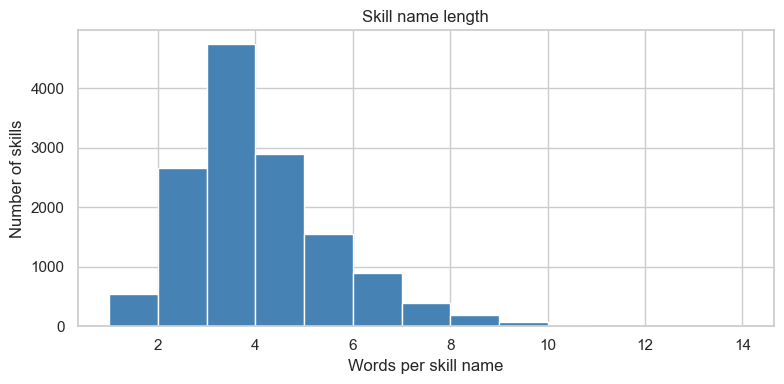

In [55]:
print(df_skills['label_words'].describe())
print('\nShare of skills by number of words in the name:')
print(df_skills['label_words'].value_counts(normalize=True).sort_index().head(8).round(3))

# share of names and of lookup spellings that are 4 words or fewer
print('\nSkill names of 4 words or fewer:', (df_skills['label_words'] <= 4).mean().round(3))
print('Lookup spellings of 4 words or fewer:', (lookup['label_norm'].str.split().str.len() <= 4).mean().round(3))

plt.figure(figsize=(8, 4))
plt.hist(df_skills['label_words'], bins=range(1, 15), color='steelblue')
plt.xlabel('Words per skill name'); plt.ylabel('Number of skills'); plt.title('Skill name length')
plt.tight_layout()
plt.show()

### Strongest terms by breadth of use

For each group with at least 50 skills, show its five highest-weight terms. Longer bars mean higher average TF-IDF weight in that group. This describes the skill list, not a prediction of job demand.

Occupation-specific means one kind of job; sector-specific means one industry; cross-sector means several industries; transversal means useful across many jobs.

sector_specific : equipment, operate, manage, maintain, perform, use, products, design, systems, food
cross_sector : manage, equipment, use, perform, techniques, operate, maintain, types, develop, apply
occupation_specific : operate, manage, perform, machine, use, equipment, prepare, tend, monitor, maintain
transversal : understand, write, written, spoken, verbally, interact, think, greek, demonstrate, telugu

words in several top-10 lists: [('equipment', 3), ('operate', 3), ('manage', 3), ('maintain', 3), ('perform', 3), ('use', 3)]


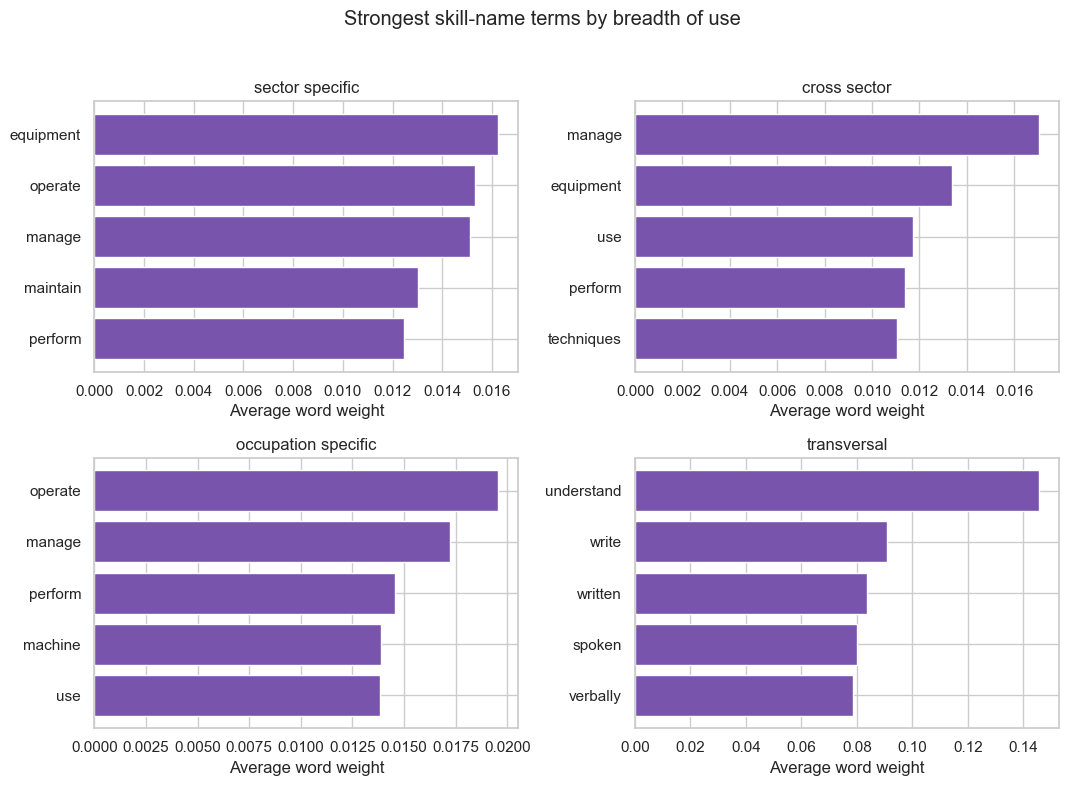

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from collections import Counter

vec_s = TfidfVectorizer(stop_words='english', min_df=5)
Xs = vec_s.fit_transform(df_skills['skill_clean'].fillna(''))
words_s = vec_s.get_feature_names_out()

top_words_s = {}
for lvl, n in df_skills['reuse_level'].value_counts().items():
    if n < 50:
        continue
    rows = (df_skills['reuse_level'] == lvl).values
    avg = np.asarray(Xs[rows].mean(axis=0)).ravel()
    top_words_s[lvl] = list(words_s[avg.argsort()[::-1][:10]])
    print(lvl, ':', ', '.join(top_words_s[lvl]))

shared_s = Counter(w for lst in top_words_s.values() for w in lst)
print('\nwords in several top-10 lists:', [x for x in shared_s.most_common(10) if x[1] > 1])

fig, axes = plt.subplots(2,2,figsize=(11,8))
for ax, level in zip(axes.flat,top_words_s):
    rows = (df_skills['reuse_level']==level).values
    average = np.asarray(Xs[rows].mean(axis=0)).ravel()
    best = average.argsort()[-5:]
    ax.barh(words_s[best],average[best],color='#7854AD')
    ax.set_title(level.replace('-',' ').replace('_',' ')); ax.set_xlabel('Average word weight')
for ax in axes.flat[len(top_words_s):]: ax.set_visible(False)
fig.suptitle('Strongest skill-name terms by breadth of use')
plt.tight_layout(rect=[0,0,1,.96]); plt.show()

### Bring-together check: does ESCO find skills in our texts?

Look for skill-name mentions in the CVs and a fixed job sample. The word tree matches complete phrases; the chart measures coverage, not verified extraction accuracy.

,CVs,Job sample
count,2481.0,1000.0
mean,15.8,9.8
std,6.7,5.4
min,1.0,0.0
25%,11.0,6.0
50%,15.0,9.0
75%,20.0,13.0
max,47.0,37.0


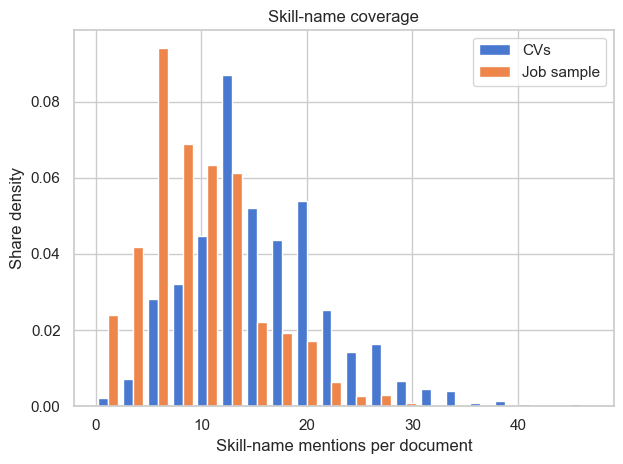

In [57]:
from collections import Counter
from functools import lru_cache

# A word tree matches complete skill phrases, including names longer than four words.
skill_tree = {}
for phrase, skill in lookup_dict.items():
    node = skill_tree
    for word in phrase.split():
        node = node.setdefault(word, {})
    node['_skill'] = skill

@lru_cache(maxsize=12000)
def find_skills(text):
    words, hits = text.split(), set()
    for start in range(len(words)):
        node = skill_tree
        for word in words[start:]:
            if word not in node: break
            node = node[word]
            if '_skill' in node: hits.add(node['_skill'])
    return frozenset(hits)

df_resumes['skills_found'] = df_resumes['Resume_clean'].apply(find_skills)
df_resumes['n_skills'] = df_resumes['skills_found'].apply(len)
job_sample = df_jobs.sample(1000, random_state=1).copy()
job_sample['n_skills'] = job_sample['job_text'].apply(lambda text: len(find_skills(text)))
display(pd.DataFrame({'CVs': df_resumes['n_skills'].describe(),
                      'Job sample': job_sample['n_skills'].describe()}).round(1))
plt.hist([df_resumes['n_skills'], job_sample['n_skills']], bins=20,
         label=['CVs', 'Job sample'], density=True)
plt.xlabel('Skill-name mentions per document'); plt.ylabel('Share density')
plt.title('Skill-name coverage'); plt.legend(); plt.tight_layout(); plt.show()
# Exact phrase matching can still miss paraphrases or misread negation and context.

### Which skills are found, and where?
We look at the most common skills found, and at the risk of false matches from very short spellings. Then we compare the average number of skills found in each resume category.

These are automatic matches from the original lookup, not verified student skills. Inspect unusual terms before interpreting the counts.

Most common skills in resumes: [('communication', 1436), ('lead others', 1402), ('plan', 1390), ('apply knowledge of science, technology and engineering', 1159), ('customer service', 1067), ('attend to detail', 937), ('report facts', 914), ('think creatively', 890), ('comply with regulations', 791), ('manage time', 756)]
Very short spellings in the lookup: ['c#']


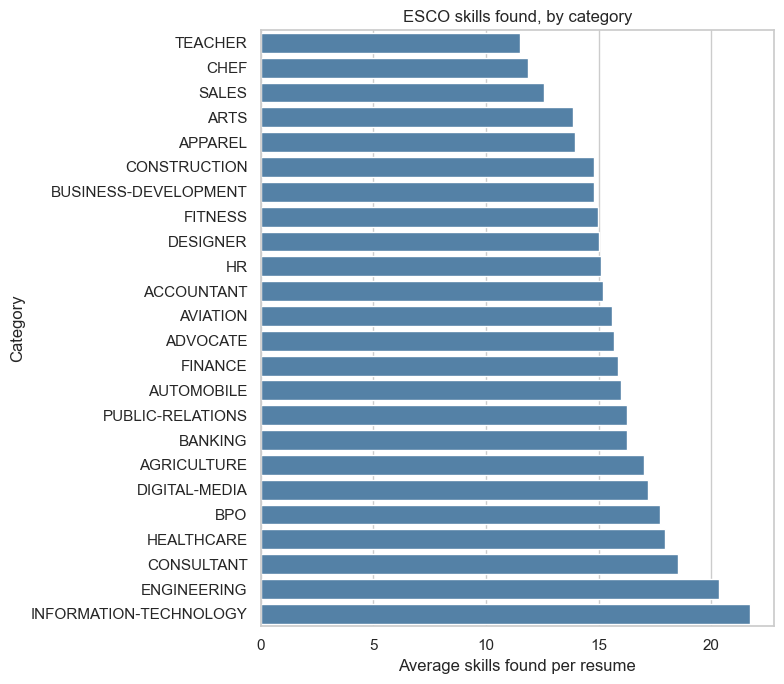

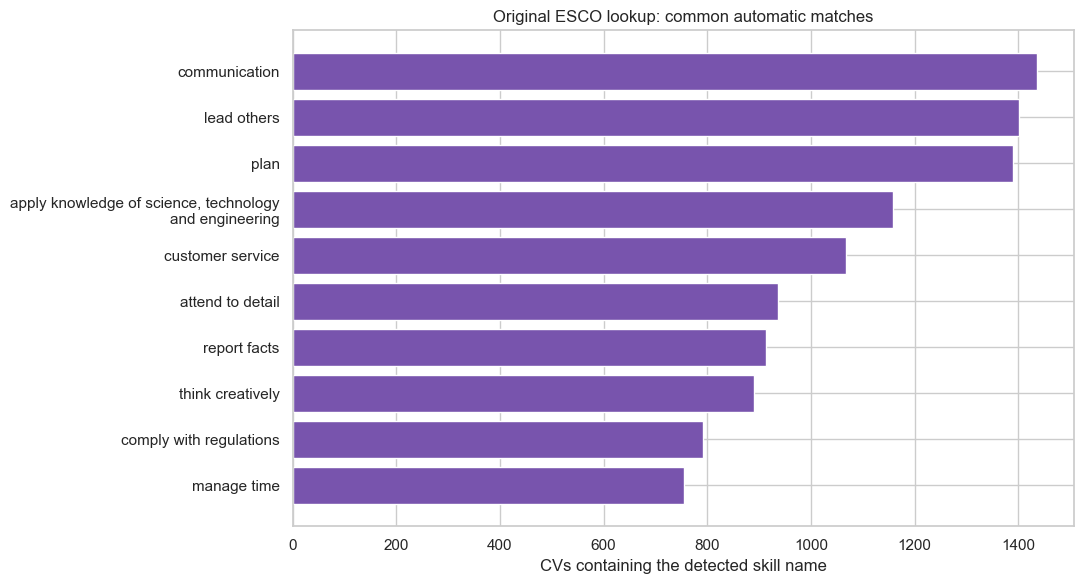

In [9]:
# most common skills found in resumes
seen = Counter(s for sk in df_resumes['skills_found'] for s in sk)
print('Most common skills in resumes:', seen.most_common(10))

# very short spellings can match inside any text
print('Very short spellings in the lookup:', lookup.loc[lookup['label_norm'].str.len() <= 2, 'label_norm'].tolist()[:20])

# skills found per resume, by category
by_cat = df_resumes.groupby('Category')['n_skills'].mean().sort_values()
plt.figure(figsize=(8, 7))
sns.barplot(x=by_cat.values, y=by_cat.index, color='steelblue')
plt.xlabel('Average skills found per resume'); plt.title('ESCO skills found, by category')
plt.tight_layout(); plt.show()

import textwrap
frequent_skills = seen.most_common(10)[::-1]
plt.figure(figsize=(11,6))
plt.barh([textwrap.fill(skill,38) for skill,count in frequent_skills],
         [count for skill,count in frequent_skills],color='#7854AD')
plt.xlabel('CVs containing the detected skill name'); plt.title('Original ESCO lookup: common automatic matches')
plt.tight_layout(); plt.show()

In [59]:
# which spellings give these odd skills?
for skill in ['move objects', 'show commitment', 'pregnancy', 'adjust to physical demands']:
    print(skill, '<-', lookup.loc[lookup['canonical'] == skill, 'label_norm'].tolist()[:8])

print('Postings containing the word "pregnancy":', df_jobs['job_text'].str.contains('pregnancy').mean().round(3))

move objects <- ['climb', 'climbing', 'lift things', 'load and unload good and materials', 'move and lift objects', 'move objects', 'muscle strength', 'perform physical activities']
show commitment <- ['can-do attitude', 'can-do-mentality', 'commitment', 'dedication', 'demonstrate motivation', 'enjoy one s profession', 'enjoy working', 'have commitment']
pregnancy <- ['conception and development of fetus inside womb', 'conception and pregnancy', 'development of fetus', 'development of fetus inside womb', 'gestation', 'gravidity', 'pregnancy', 'pregnancy characteristics']
adjust to physical demands <- ['adjust to physical demands', 'cold tolerance', 'demonstrate physical resilience', 'exercise capacity', 'insensitivity to temperature', 'insensitivity to weathering', 'kneel', 'stand']


Postings containing the word "pregnancy": 0.101


### What we noticed (ESCO skills)

Review the skill examples as well as the counts. More detected phrases do not necessarily mean better extraction.

## 2.4 All datasets together

Compare the datasets before combining them. Different document lengths and vocabularies can affect matching; similar length is not a requirement for a relevant result.

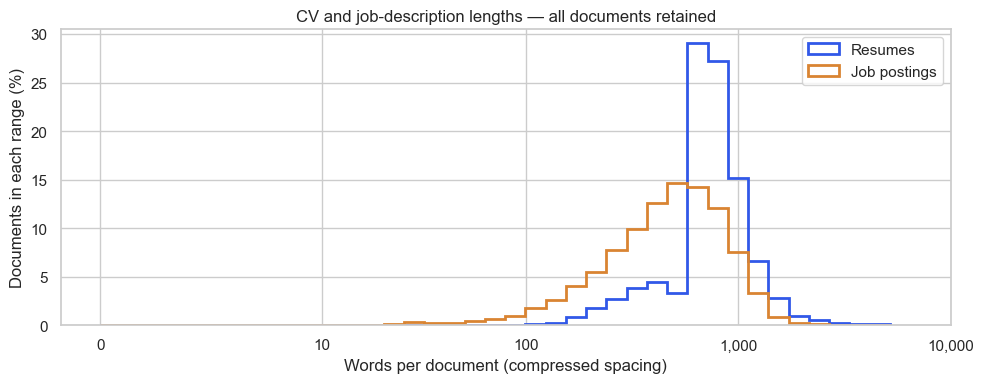

In [16]:
lengths = pd.concat([
    pd.DataFrame({'type':'Resumes','words':df_resumes['word_count']}),
    pd.DataFrame({'type':'Job postings','words':df_jobs['word_count']})])
bins = np.linspace(0,np.log1p(lengths['words'].max()),40)
fig, ax = plt.subplots(figsize=(10,4))
for name,color in [('Resumes','#3158E8'),('Job postings','#D98432')]:
    values = lengths.loc[lengths['type']==name,'words'].dropna()
    ax.hist(np.log1p(values),bins=bins,weights=np.full(len(values),100/len(values)),
            histtype='step',linewidth=2,label=name,color=color)
ticks = [0,10,100,1000,10000]
ax.set_xticks(np.log1p(ticks),[f'{value:,}' for value in ticks])
ax.set_xlabel('Words per document (compressed spacing)'); ax.set_ylabel('Documents in each range (%)')
ax.set_title('CV and job-description lengths — all documents retained'); ax.legend()
plt.tight_layout(); plt.show()


### Which skills do beginner jobs ask for more than resumes show?

Compare skill-name mention rates in beginner postings and CVs. These differences suggest topics to investigate; they do not prove individual students lack those skills.

This original lookup includes false matches: a term such as “pregnancy” may come from an equal-opportunity statement. The chart is an error-inspection result, not advice to learn those terms. Section 5 uses stricter aliases and context checks for the live app.

                            jobs_%  resumes_%  difference
adjust to physical demands    17.0        1.5        15.5
show commitment               21.3        6.6        14.7
pregnancy                     11.7        0.2        11.5
move objects                  13.8        3.8        10.0
assume responsibility         10.0        0.4         9.6
think innovatively            12.0        3.8         8.2
perform cleaning duties       16.6        9.9         6.7
attend to detail              43.4       37.8         5.6
acoustics                      6.7        1.1         5.6
work independently             8.2        2.9         5.3


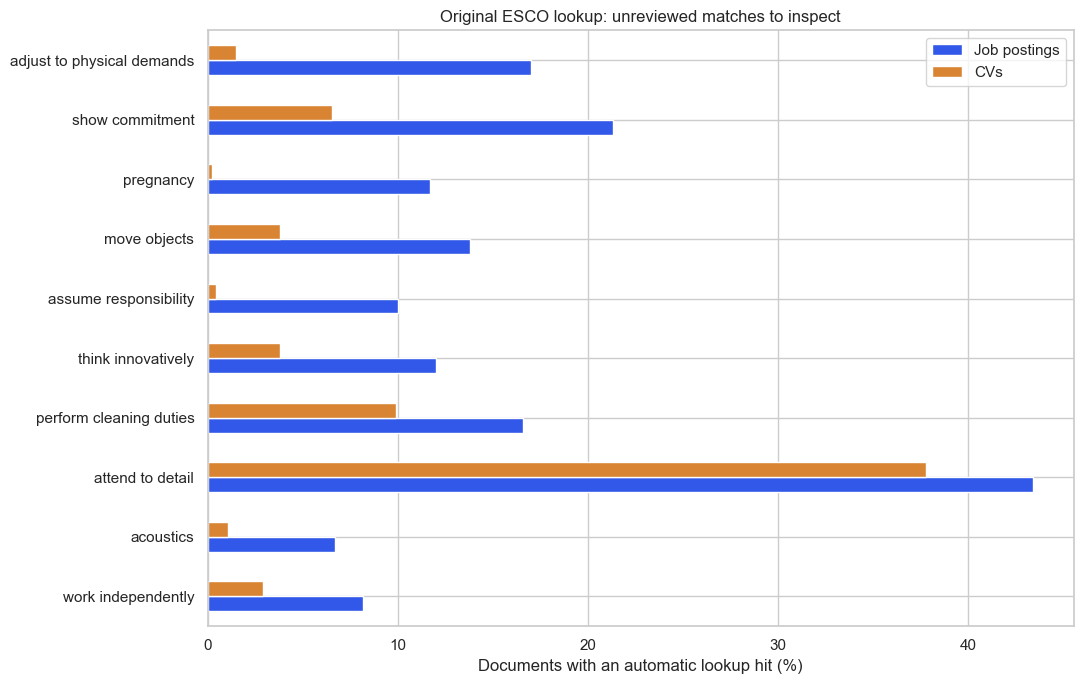

In [10]:
# 1,000 internship and entry-level postings
jobs_early = df_jobs[df_jobs['is_internship'] | (df_jobs['experience_level'] == 'Entry level')].sample(1000, random_state=1)
jobs_early_skills = jobs_early['job_text'].apply(find_skills)

# share of postings and of resumes that mention each skill
job_share = Counter(s for sk in jobs_early_skills for s in sk)
res_share = Counter(s for sk in df_resumes['skills_found'] for s in sk)
gap = pd.DataFrame({'jobs_%': pd.Series(job_share) / len(jobs_early) * 100,
                    'resumes_%': pd.Series(res_share) / len(df_resumes) * 100}).fillna(0)
gap['difference'] = gap['jobs_%'] - gap['resumes_%']
print(gap.sort_values('difference', ascending=False).head(10).round(1))

import textwrap
gap_plot = gap.sort_values('difference',ascending=False).head(10).iloc[::-1][['jobs_%','resumes_%']].copy()
gap_plot.index = [textwrap.fill(skill,35) for skill in gap_plot.index]
gap_plot.columns = ['Job postings','CVs']
gap_plot.plot.barh(figsize=(11,7),color=['#3158E8','#D98432'])
plt.xlabel('Documents with an automatic lookup hit (%)'); plt.title('Original ESCO lookup: unreviewed matches to inspect')
plt.tight_layout(); plt.show()

### What we noticed (all datasets)

Compare the three sources before modelling. Their language, coverage and purpose differ.

# 3. Modelling

First we train models to recognise CV categories. We then compare ways to retrieve related text and identify mentioned skills. These are separate checks: a correct career category does not prove a job is suitable.

## 3.1 Resume classifier

We train the models on the cleaned resumes to answer four questions: how well can a model guess the category, does it only work because of the job title, which categories does it mix up, and can we trust the score?

### Split the data

We keep 80% of the resumes to train the models and 20% for the final test, with the same share of each category in both. We chose 80/20 because 50/50 would leave too few resumes to learn from in small categories like BPO (22 resumes). The seed 42 makes the split the same every time, and every model uses the same split. We do not use the test resumes to choose anything, only to report the final scores.

In [62]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.metrics.pairwise import cosine_similarity

# load the cleaned resumes saved in section 1
df_model = pd.read_csv(os.path.join(OUT_DIR, 'resume_clean.csv'))
text_columns = ['Resume_clean', 'Resume_notitle', 'Resume_title']
df_model[text_columns] = df_model[text_columns].fillna('')
categories = sorted(df_model['Category'].unique())

# 80% train, 20% test, same share of each category in both (fixed seed 42)
train_idx, test_idx = train_test_split(
    df_model.index, test_size=0.2, stratify=df_model['Category'], random_state=42)
y_train = df_model.loc[train_idx, 'Category']
y_test = df_model.loc[test_idx, 'Category']

print('Train:', len(train_idx), 'resumes | Test:', len(test_idx), 'resumes')
display(pd.DataFrame({'train': y_train.value_counts(), 'test': y_test.value_counts()}).sort_values('train').head(5))

Train: 1984 resumes | Test: 497 resumes


,train,test
Category,,
BPO,18,4
AUTOMOBILE,29,7
AGRICULTURE,50,13
DIGITAL-MEDIA,77,19
APPAREL,78,19


### Set up the models

Convert words into weighted numbers using TF-IDF, learned from training data only. Logistic regression learns category scores; linear SVM learns boundaries between categories; Naive Bayes learns word patterns associated with each category. Compare them with a baseline that always guesses the most common category. These are CV classifiers, separate from semantic job ranking.

In [63]:
# TF-IDF and the model in one pipeline, so TF-IDF is learned from the training part only
def make_pipeline(model):
    tfidf = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=5,
                            max_df=0.8, sublinear_tf=True, max_features=20000)
    return Pipeline([('tfidf', tfidf), ('model', clone(model))])

# 5 rounds of cross-validation, each with the same share of every category
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

BASELINE = 'Baseline (most common category)'
models = {
    'Logistic regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Linear SVM': LinearSVC(class_weight='balanced'),
    'Naive Bayes': ComplementNB(),
    BASELINE: DummyClassifier(strategy='most_frequent'),
}

### Choose the setting C

C controls how strongly logistic regression is kept from fitting the training examples too closely. We compare three settings using training CVs without their titles, then freeze the chosen setting for all title comparisons. The final test CVs are not used to choose it.

In [64]:
# try three values of C, scored by macro-F1 on the training resumes only
grid = GridSearchCV(make_pipeline(models['Logistic regression']),
                    param_grid={'model__C': [1, 10, 100]},
                    scoring='f1_macro', cv=cv, n_jobs=1)
grid.fit(df_model.loc[train_idx, 'Resume_notitle'], y_train)
display(pd.DataFrame(grid.cv_results_)[['param_model__C', 'mean_test_score', 'std_test_score']].round(3))

best_c = grid.best_params_['model__C']
print('Best C:', best_c)
models['Logistic regression'] = LogisticRegression(max_iter=2000, class_weight='balanced', C=best_c)

,param_model__C,mean_test_score,std_test_score
0,1,0.558,0.021
1,10,0.583,0.023
2,100,0.589,0.025


Best C: 100


### Compare the models

Use five training-data splits for comparison, then fit each model on the full training portion and measure the held-out test results. Accuracy is the share of correct categories. Macro-F1 balances missed and incorrect predictions, giving each category equal weight. Compare text with titles, without titles and titles alone.

,Model,Text,CV accuracy,CV macro-F1,Test accuracy,Test macro-F1
0,Logistic regression,With title,0.672,0.619,0.692,0.647
1,Logistic regression,Without title,0.641,0.589,0.662,0.618
2,Logistic regression,Title only,0.684,0.646,0.668,0.627
3,Linear SVM,With title,0.689,0.639,0.698,0.651
4,Linear SVM,Without title,0.652,0.601,0.670,0.630
5,Linear SVM,Title only,0.697,0.653,0.686,0.643
6,Naive Bayes,With title,0.580,0.499,0.577,0.502
7,Naive Bayes,Without title,0.559,0.480,0.567,0.493
8,Naive Bayes,Title only,0.690,0.605,0.690,0.609
9,Baseline (most common category),With title,0.047,0.004,0.048,0.004


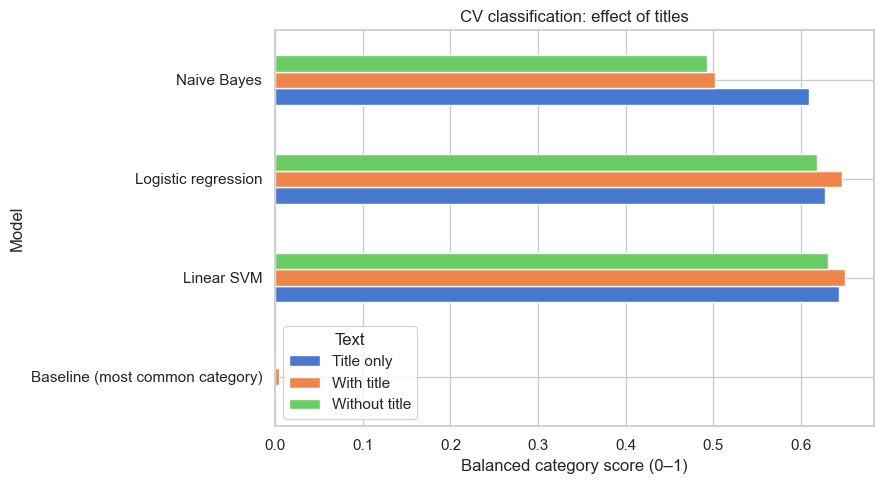

In [65]:
texts = {'With title': 'Resume_clean',
         'Without title': 'Resume_notitle',
         'Title only': 'Resume_title'}

# cross-validate on the training resumes, then score the test resumes once
def evaluate(model_name, model, text_name, column):
    x_train = df_model.loc[train_idx, column]
    x_test = df_model.loc[test_idx, column]

    cv_scores = cross_validate(make_pipeline(model), x_train, y_train, cv=cv,
                               scoring=['accuracy', 'f1_macro'], n_jobs=1)
    pipeline = make_pipeline(model).fit(x_train, y_train)
    predicted = pipeline.predict(x_test)

    row = {'Model': model_name, 'Text': text_name,
           'CV accuracy': cv_scores['test_accuracy'].mean(),
           'CV accuracy spread': cv_scores['test_accuracy'].std(),
           'CV macro-F1': cv_scores['test_f1_macro'].mean(),
           'CV macro-F1 spread': cv_scores['test_f1_macro'].std(),
           'Test accuracy': accuracy_score(y_test, predicted),
           'Test macro-F1': f1_score(y_test, predicted, average='macro')}
    return row, pipeline

rows, fitted = [], {}
for model_name, model in models.items():
    for text_name, column in texts.items():
        # the baseline does not read the text, so one run is enough
        if model_name == BASELINE and text_name != 'With title':
            continue
        row, fitted[(model_name, text_name)] = evaluate(model_name, model, text_name, column)
        rows.append(row)

results = pd.DataFrame(rows)
display(results[['Model', 'Text', 'CV accuracy', 'CV macro-F1', 'Test accuracy', 'Test macro-F1']].round(3))

results.pivot(index='Model', columns='Text', values='Test macro-F1').plot.barh(figsize=(9, 5)); plt.xlabel('Balanced category score (0–1)'); plt.title('CV classification: effect of titles'); plt.tight_layout(); plt.show()

### Does the model only work because of the title?

We compare the score with the title and without it. If the score drops a lot without the title, the model was leaning on the title and not on the rest of the resume. We use the practice-round score because it is steadier than the small test set. For logistic regression, macro-F1 drops from 0.619 to 0.591, a small drop. But the title alone scores 0.646, higher than the whole resume, so the title is a very strong clue by itself.

In [66]:
real_models = results[results['Model'] != BASELINE]
title_effect = real_models.pivot(index='Model', columns='Text', values='CV macro-F1')
title_effect['Drop without title'] = title_effect['With title'] - title_effect['Without title']
display(title_effect[['With title', 'Without title', 'Drop without title']].round(3))

Text,With title,Without title,Drop without title
Model,,,
Linear SVM,0.639,0.601,0.038
Logistic regression,0.619,0.589,0.030
Naive Bayes,0.499,0.480,0.019


### Which categories does the model mix up?

The grid shows, for each real category (rows), what the model guessed (columns). The numbers on the diagonal are right guesses, and a number away from the diagonal is a mix-up. We use logistic regression without the title, because it is the harder test. The biggest mix-ups are Finance guessed as Accountant (11 resumes, and none the other way) and Advocate guessed as Healthcare (6 resumes).

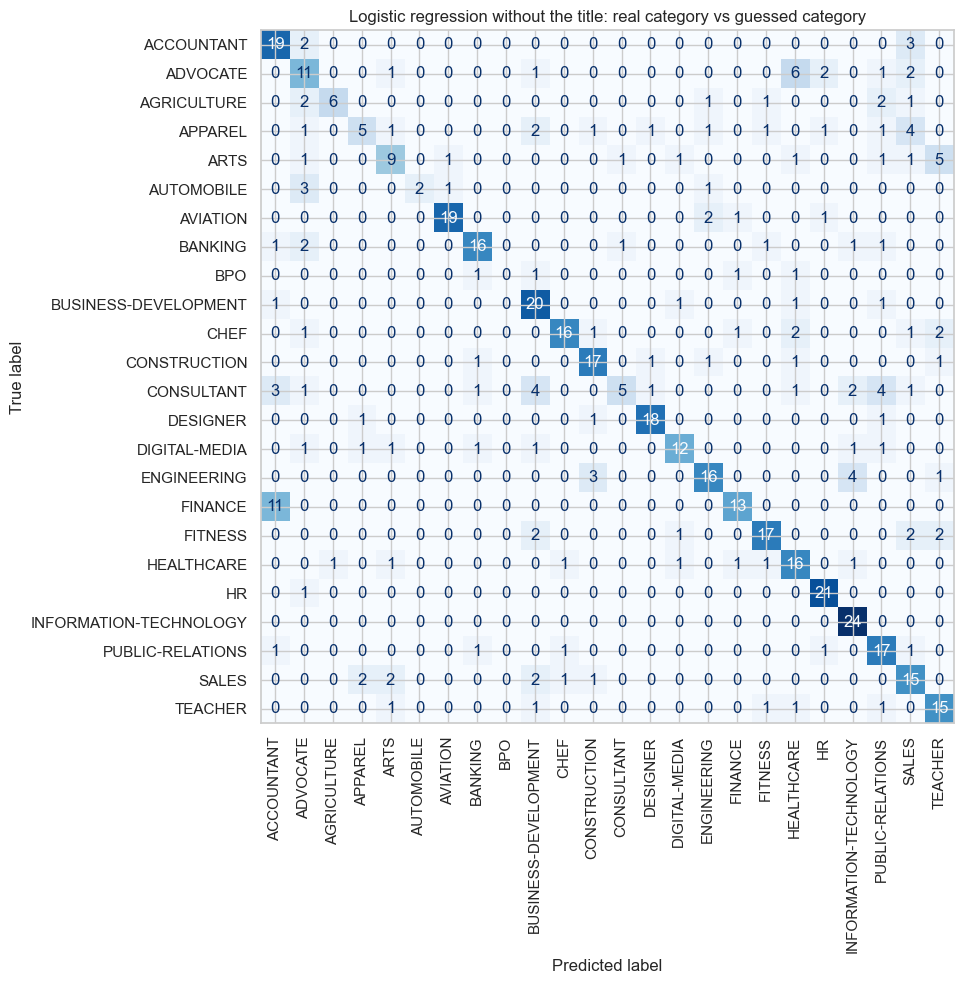

,Real category,Guessed as,Resumes
0,FINANCE,ACCOUNTANT,11
1,ADVOCATE,HEALTHCARE,6
2,ARTS,TEACHER,5
3,APPAREL,SALES,4
4,CONSULTANT,BUSINESS-DEVELOPMENT,4
5,ENGINEERING,INFORMATION-TECHNOLOGY,4
6,CONSULTANT,PUBLIC-RELATIONS,4
7,ACCOUNTANT,SALES,3


In [67]:
pipeline = fitted[('Logistic regression', 'Without title')]
predicted = pipeline.predict(df_model.loc[test_idx, 'Resume_notitle'])

matrix = confusion_matrix(y_test, predicted, labels=categories)
fig, ax = plt.subplots(figsize=(11, 10))
ConfusionMatrixDisplay(matrix, display_labels=categories).plot(
    ax=ax, xticks_rotation=90, colorbar=False, cmap='Blues')
ax.set_title('Logistic regression without the title: real category vs guessed category')
plt.tight_layout()
plt.show()

# the biggest mix-ups: real category -> guessed category
off_diagonal = matrix.copy()
np.fill_diagonal(off_diagonal, 0)
real_i, guessed_i = np.nonzero(off_diagonal)
mixups = pd.DataFrame({'Real category': np.array(categories)[real_i],
                       'Guessed as': np.array(categories)[guessed_i],
                       'Resumes': off_diagonal[real_i, guessed_i]})
display(mixups.sort_values('Resumes', ascending=False).head(8).reset_index(drop=True))

### Score for each category

This shows how well each category does on the test resumes (a score from 0 to 1) and how many test resumes it has. Small categories have only a few, so their scores can jump around. The lowest scores are BPO (0.00, only 4 test resumes), Consultant (0.33) and Apparel (0.36). The best are HR (0.88), Aviation (0.86) and Designer (0.86).

,score,test resumes
BPO,0.00,4.0
CONSULTANT,0.33,23.0
APPAREL,0.36,19.0
ADVOCATE,0.44,24.0
AUTOMOBILE,0.44,7.0
ARTS,0.49,21.0
SALES,0.56,23.0
AGRICULTURE,0.60,13.0
HEALTHCARE,0.60,23.0
FINANCE,0.63,24.0


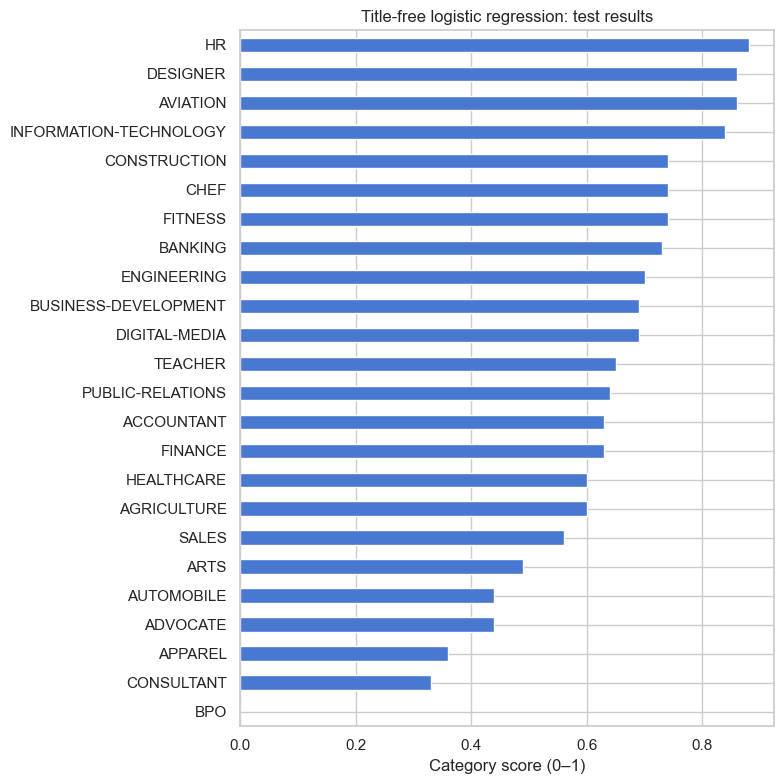

In [11]:
report = pd.DataFrame(classification_report(y_test, predicted, output_dict=True, zero_division=0)).T
table = report.loc[categories, ['f1-score', 'support']].round(2)
table.columns = ['score', 'test resumes']
display(table.sort_values('score'))

table['score'].sort_values().plot.barh(figsize=(8, 8)); plt.xlabel('Category score (0–1)'); plt.title('Title-free logistic regression: test results'); plt.tight_layout(); plt.show()

### Are the test resumes copies of training resumes?

If a test resume is almost the same as a training resume, the model has effectively seen it and the score looks better than it is. For each test resume we find the most similar training resume. 3 of 497 test resumes have a training resume more than 90% alike. On the test resumes with no close copy, logistic regression without the title is right 66% of the time (0.659), the same as on all test resumes (0.662), so copies do not inflate the score.

The histogram flags high similarity for review. Similar text does not by itself prove an exact duplicate.

Test resumes more than 90% like a training resume: 3 of 497
Test resumes more than 80% like a training resume: 4
Accuracy without close copies: 0.659


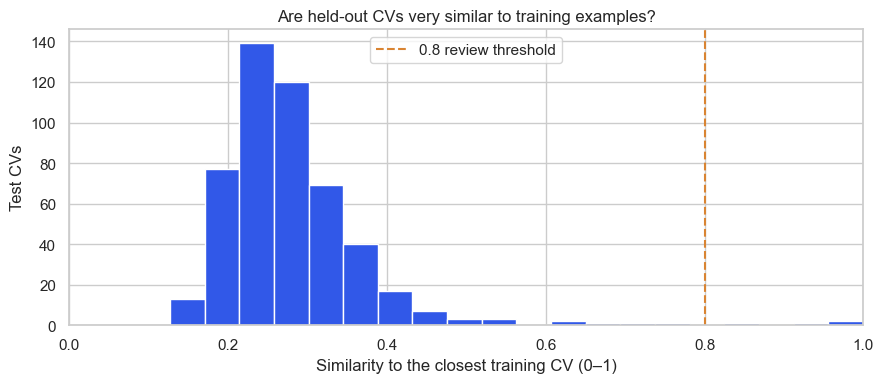

In [21]:
# words learned from the training resumes only
tfidf = TfidfVectorizer(stop_words='english', min_df=5, sublinear_tf=True)
x_train_tfidf = tfidf.fit_transform(df_model.loc[train_idx, 'Resume_clean'])
x_test_tfidf = tfidf.transform(df_model.loc[test_idx, 'Resume_clean'])

# for each test resume, how alike is the closest training resume?
closest = cosine_similarity(x_test_tfidf, x_train_tfidf).max(axis=1)
print('Test resumes more than 90% like a training resume:', (closest > 0.9).sum(), 'of', len(closest))
print('Test resumes more than 80% like a training resume:', (closest > 0.8).sum())

# accuracy on the test resumes with no close copy
no_copy = closest < 0.8
print('Accuracy without close copies:', round(accuracy_score(y_test[no_copy], predicted[no_copy]), 3))

plt.figure(figsize=(9,4))
plt.hist(closest,bins=20,color='#3158E8',edgecolor='white')
plt.axvline(.8,color='#D98432',linestyle='--',label='0.8 review threshold')
plt.xlim(0,1); plt.xlabel('Similarity to the closest training CV (0–1)'); plt.ylabel('Test CVs')
plt.title('Are held-out CVs very similar to training examples?'); plt.legend()
plt.tight_layout(); plt.show()

### How we checked the results

Keep the final test portion separate from choosing C. Compare title effects, per-category results and near copies. These checks use one fixed split; they do not establish performance on new Kenyan student CVs. Section 4 adds the semantic comparison.

### What we noticed (modelling)

Read the current tables and charts. Accuracy is the share of correct categories; macro-F1 balances missed and incorrect category predictions and gives each category equal weight. Compare title-free results and inspect near copies before drawing conclusions.

## 3.2 Matching resumes to jobs

We compare shared words and broader word patterns. LSA groups related word patterns learned from the data; Section 4 adds a pretrained meaning-based model. Job titles provide rough field labels for checking results, not verified judgements of job suitability.

### Test 1: which way of turning text into numbers finds the right category?

For each test resume we find the 5 most similar training resumes and count how many have the same category (precision@5: 1 means all 5 are right, 0 means none). We compare three ways of turning a resume into numbers: word counts, word scores (TF-IDF), and word scores followed by LSA, which keeps only the 200 main patterns in the words. We run each with and without the title. The chance level is what a random guess would score.

,With title,Without title
Word counts,0.438,0.417
TF-IDF,0.439,0.429
TF-IDF + LSA,0.452,0.442


Chance level: 0.044


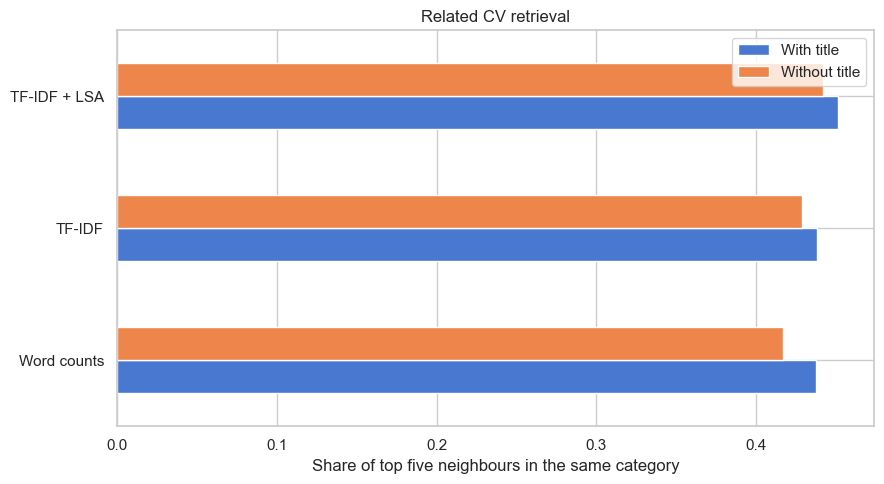

In [13]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer

# three ways to turn a resume into numbers
representations = {
    'Word counts': CountVectorizer(stop_words='english', min_df=5, max_df=0.8, max_features=20000),
    'TF-IDF': TfidfVectorizer(stop_words='english', min_df=5, max_df=0.8, sublinear_tf=True, max_features=20000),
    'TF-IDF + LSA': Pipeline([
        ('tfidf', TfidfVectorizer(stop_words='english', min_df=5, max_df=0.8, sublinear_tf=True, max_features=20000)),
        ('lsa', TruncatedSVD(n_components=200, random_state=42)),
        ('scale', Normalizer())]),
}

# share of the 5 closest training resumes that have the same category as the test resume
def resume_precision_at_5(representation, column):
    representation = clone(representation)
    train_vectors = representation.fit_transform(df_model.loc[train_idx, column])
    test_vectors = representation.transform(df_model.loc[test_idx, column])
    closest = np.argsort(-cosine_similarity(test_vectors, train_vectors), axis=1)[:, :5]
    return (y_train.to_numpy()[closest] == y_test.to_numpy()[:, None]).mean()

resume_scores = pd.DataFrame({
    name: {'With title': resume_precision_at_5(rep, 'Resume_clean'),
           'Without title': resume_precision_at_5(rep, 'Resume_notitle')}
    for name, rep in representations.items()}).T
display(resume_scores.round(3))

# chance: how often a random training resume has the same category as a test resume
chance_resumes = (y_train.value_counts(normalize=True) * y_test.value_counts(normalize=True)).sum()
print('Chance level:', round(chance_resumes, 3))

resume_scores.plot.barh(figsize=(9, 5)); plt.xlabel('Share of top five neighbours in the same category'); plt.title('Related CV retrieval'); plt.tight_layout(); plt.show()

### Test 2: does the match find jobs in the right field?

Give job postings rough career-field labels using title keywords, then rank their title-free text for held-out CVs. The top-five score is the share of retrieved jobs in the same field. These approximate labels do not measure true suitability or hiring success.

title_category
SALES                     300
ENGINEERING               300
HR                        300
TEACHER                   300
ACCOUNTANT                300
INFORMATION-TECHNOLOGY    300
HEALTHCARE                300
BANKING                   300
FINANCE                   300
CONSTRUCTION              300
CHEF                      300
FITNESS                    83
Name: count, dtype: int64

Precision@5: 0.596 | chance level: 0.083
                        mean  count
Category                           
ACCOUNTANT              0.87     24
BANKING                 0.43     23
CHEF                    0.79     24
CONSTRUCTION            0.64     22
ENGINEERING             0.51     24
FINANCE                 0.26     24
FITNESS                 0.42     24
HEALTHCARE              0.44     23
HR                      1.00     22
INFORMATION-TECHNOLOGY  0.54     24
SALES                   0.52     23
TEACHER                 0.78     20


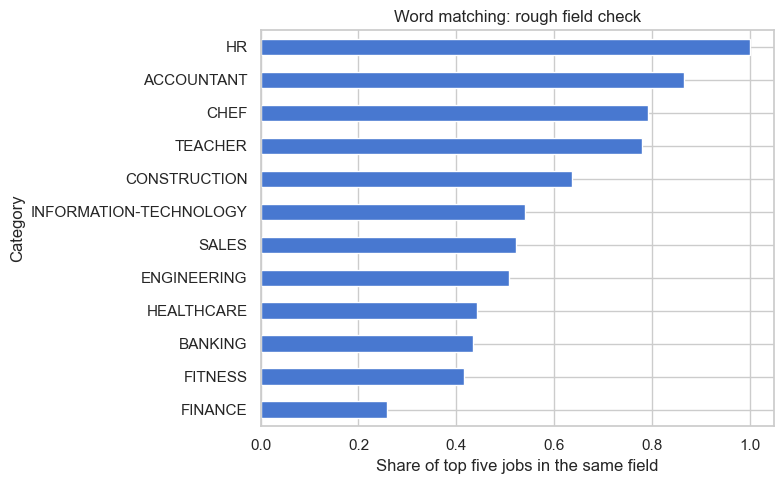

In [14]:
# words in a job title that point to one resume category (the first match wins)
TITLE_PATTERNS = {
    'INFORMATION-TECHNOLOGY': r'software|developer|network|help desk|it support|system administrator',
    'ACCOUNTANT': r'accountant|accounting|bookkeeper',
    'BANKING': r'\bbank|teller',
    'CHEF': r'\bchef|\bcook\b|kitchen',
    'CONSTRUCTION': r'construction|carpenter|electrician|plumber',
    'ENGINEERING': r'engineer',
    'FINANCE': r'financ',
    'FITNESS': r'fitness|personal trainer',
    'HEALTHCARE': r'\bnurse|medical|patient care|clinical|pharmac',
    'HR': r'\bhr\b|human resources|recruiter',
    'SALES': r'\bsales',
    'TEACHER': r'teacher|tutor|instructor',
}

def title_category(title):
    for category, pattern in TITLE_PATTERNS.items():
        if re.search(pattern, title):
            return category
    return None

df_jobs['title_clean'] = df_jobs['title_clean'].fillna('')
df_jobs['title_category'] = df_jobs['title_clean'].apply(title_category)

# posting text without the title, so the label cannot leak into the match
df_jobs['job_body'] = [text[len(title):].strip() for text, title in zip(df_jobs['job_text'], df_jobs['title_clean'])]

# up to 300 postings for each category
labelled_jobs = (df_jobs[df_jobs['title_category'].notna()]
                 .sample(frac=1, random_state=42)
                 .groupby('title_category').head(300)
                 .reset_index(drop=True))
display(labelled_jobs['title_category'].value_counts())

# test resumes from the categories that have labelled postings
in_scope = test_idx[df_model.loc[test_idx, 'Category'].isin(labelled_jobs['title_category'].unique())]
resume_labels = df_model.loc[in_scope, 'Category'].to_numpy()

# words learned from the training resumes and the labelled postings
job_tfidf = TfidfVectorizer(stop_words='english', min_df=5, max_df=0.8, sublinear_tf=True, max_features=20000)
job_tfidf.fit(pd.concat([df_model.loc[train_idx, 'Resume_notitle'], labelled_jobs['job_body']]))
text_similarity = cosine_similarity(job_tfidf.transform(df_model.loc[in_scope, 'Resume_notitle']),
                                    job_tfidf.transform(labelled_jobs['job_body']))

# for each resume, is each of the 5 closest postings in the resume's category?
def top5_hits(similarity):
    closest = np.argsort(-similarity, axis=1)[:, :5]
    return labelled_jobs['title_category'].to_numpy()[closest] == resume_labels[:, None]

share = labelled_jobs['title_category'].value_counts(normalize=True)
chance_jobs = pd.Series(resume_labels).map(share).mean()
print('Precision@5:', round(top5_hits(text_similarity).mean(), 3), '| chance level:', round(chance_jobs, 3))

per_category = (pd.DataFrame({'Category': resume_labels, 'precision@5': top5_hits(text_similarity).mean(axis=1)})
                .groupby('Category')['precision@5'].agg(['mean', 'count']))
print(per_category.round(2).to_string())

per_category['mean'].sort_values().plot.barh(figsize=(8, 5)); plt.xlabel('Share of top five jobs in the same field'); plt.title('Word matching: rough field check'); plt.tight_layout(); plt.show()

### Match a resume to jobs

This is our original word-based baseline. It searches postings marked internship or entry level. These historical research postings are not a list of currently available or Kenya-eligible vacancies.

In [15]:
# internship and entry-level postings only
early_jobs = df_jobs[df_jobs['is_internship'] | (df_jobs['experience_level'] == 'Entry level')]
early_jobs = early_jobs.drop_duplicates(subset=['title', 'company_name']).reset_index(drop=True)

# words learned from the training resumes and these postings
match_tfidf = TfidfVectorizer(stop_words='english', min_df=5, max_df=0.8, sublinear_tf=True, max_features=20000)
match_tfidf.fit(pd.concat([df_model.loc[train_idx, 'Resume_notitle'], early_jobs['job_text']]))
early_vectors = match_tfidf.transform(early_jobs['job_text'])

# the closest postings to a resume
def match(resume_text, top_k=5):
    similarity = cosine_similarity(match_tfidf.transform([resume_text]), early_vectors).ravel()
    best = similarity.argsort()[::-1][:top_k]
    result = early_jobs.loc[best, ['title', 'company_name']].copy()
    result['similarity'] = similarity[best].round(2)
    return result

# one test resume from three categories
test_resumes = df_model.loc[test_idx]
for category in ['HR', 'CHEF', 'INFORMATION-TECHNOLOGY']:
    resume = test_resumes[test_resumes['Category'] == category].iloc[0]
    print('\nResume category:', category)
    print(match(resume['Resume_notitle']).to_string(index=False))


Resume category: HR


                           title     company_name  similarity
                  HR Coordinator             Vaco        0.23
       Human Resources Assistant        CoreCivic        0.21
      Human Resources Generalist      Robert Half        0.20
                  HR Coordinator      Group Lotus        0.19
Assistant Account Manager Retail Allied Universal        0.19

Resume category: CHEF


                                                             title                                                             company_name  similarity
  Food Service Worker - Clinical Food Services (0.5 FTE, Rotating) Stanford Children's Health | Lucile Packard Children's Hospital Stanford        0.19
                              Hospitality Associate, Food Services                                                           Tufts Medicine        0.17
Food Service Assistant I -Patient Food Services (Per Diem Evening)                                                          Endeavor Health        0.16
        Special Education Teacher : Uplift Triumph Primary (24-25)                                                         Uplift Education        0.16
                         Cafeteria Helper PT - Distribution Center                                     Price Chopper Supermarkets-Market 32        0.15

Resume category: INFORMATION-TECHNOLOGY


                                                           title      company_name  similarity
                                            Contracts Specialist      Tandym Group        0.19
              PEGA Application Support Engineer - (PCSA / PCSSA)              Dice        0.18
Pega Support Engineer || Merrifield, VA (Hybrid - 2 days a week)              Dice        0.16
                        Sourcing Outsourcing & Offshoring Expert Chain IQ Group AG        0.15
                                               IT Vendor Analyst        TEKsystems        0.15


### What we noticed (matching)

Read the current matching scores. Same-field results are a rough check based on category names; independent relevance ratings are still needed to assess recommendation quality.

## 3.3 Skills

We look for skill names in the text using the ESCO lookup. A skill not mentioned in a CV may still be known by the student. Mentioned job skills are not automatically mandatory requirements.

### Do the skills found make sense? (hand check)

The table shows one skill found in each of 30 random test resumes, with the words around it. Read each row and write y if the skill really is in the text, or n if not. Then we count the share of y. This only measures how many of the skills found are right. We did not count the skills we missed.

In [16]:
# every ESCO skill found in a text, with the words around it
def skill_hits(text, window=4):
    words = text.split()
    hits = []
    for n in (1, 2, 3, 4):
        for i in range(len(words) - n + 1):
            spelling = ' '.join(words[i:i + n])
            if spelling in lookup_dict:
                hits.append((spelling, lookup_dict[spelling], ' '.join(words[max(0, i - window):i + n + window])))
    return hits

# one random skill hit from each of 30 random test resumes
rng = np.random.default_rng(42)
check = []
for text in df_model.loc[rng.choice(test_idx, 30, replace=False), 'Resume_notitle']:
    hits = skill_hits(text)
    if hits:
        spelling, skill, context = hits[rng.integers(len(hits))]
        check.append({'found as': spelling, 'skill': skill, 'context': context})
check = pd.DataFrame(check)
pd.set_option('display.max_colwidth', 100)
display(check)

,found as,skill,context
0,vocabulary,terminology,defense medal. skills advanced vocabulary and reading comprehension skills.
1,attention to detail,attend to detail,energy work requiring close attention to detail being able to lift
2,customer service,customer service,2009 to april 2010 customer service specialist call center gather
3,customer service,customer service,2014 to 08 2014 customer service associate - providing quality
4,office management,office administration,millennium month end closing office management oracle payables personnel policies
5,consulting,advise others,project and construction management consulting services. design and engineering.
6,schedule,manage time,responsible or website updates. schedule team meetings through zoom
7,patient safety,patient safety theories,care coordinating patient care patient safety physiology policies presentations protocols
8,statistics,statistics,management and communications managerial statistics and management communication coursework
9,communication,communication,results-oriented quick learner superior communication skills cheerful and energetic


In [17]:
# Fill these only after checking the CURRENT displayed rows: y = supported, n = incorrect.
marks = []
if marks and len(marks) == len(check) and set(marks) <= {'y', 'n'}:
    print('Supported skill mentions:', marks.count('y'), 'of', len(marks))
else:
    print('Human skill review pending. No verified precision is reported.')

Human skill review pending. No verified precision is reported.


### Do the closest postings share more skills with the resume?

If the skill finding is useful, the postings that match a resume should ask for skills the resume already shows more often than random postings do. For 100 test resumes we compare their 5 closest postings with 5 random ones.

Share of the posting skills the resume shows, closest postings: 0.342
Share of the posting skills the resume shows, random postings:  0.179


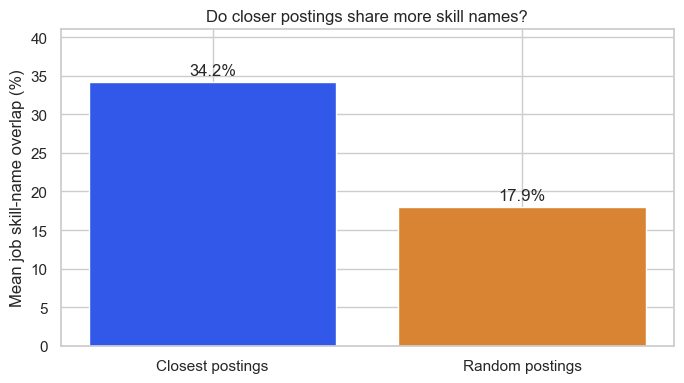

In [8]:
# share of a posting's skills that the resume also shows
def skill_overlap(resume_skills, job_skills):
    return len(resume_skills & job_skills) / len(job_skills) if job_skills else 0

# 100 test resumes: their 5 closest postings against 5 random postings
rng = np.random.default_rng(42)
matched_overlap, random_overlap = [], []
for text in df_model.loc[rng.choice(test_idx, 100, replace=False), 'Resume_notitle']:
    resume_skills = find_skills(text)
    matched_jobs = early_jobs.loc[match(text).index, 'job_text']
    random_jobs = early_jobs['job_text'].iloc[rng.choice(len(early_jobs), 5, replace=False)]
    matched_overlap += [skill_overlap(resume_skills, find_skills(t)) for t in matched_jobs]
    random_overlap += [skill_overlap(resume_skills, find_skills(t)) for t in random_jobs]

print('Share of the posting skills the resume shows, closest postings:', round(np.mean(matched_overlap), 3))
print('Share of the posting skills the resume shows, random postings: ', round(np.mean(random_overlap), 3))

fig, ax = plt.subplots(figsize=(7,4))
bars = ax.bar(['Closest postings','Random postings'],[np.mean(matched_overlap)*100,np.mean(random_overlap)*100],color=['#3158E8','#D98432'])
ax.bar_label(bars,fmt='%.1f%%',padding=3)
ax.set_ylabel('Mean job skill-name overlap (%)')
ax.set_title('Do closer postings share more skill names?'); ax.margins(y=.2)
plt.tight_layout(); plt.show()

### What the skill check tells us

The lookup can confuse ordinary phrases with skills. The displayed examples need human review before we report extraction accuracy. Shared skill names are a useful diagnostic, not proof of job suitability.

### What we noticed (all together)

Compare the measured text, skills and combined results below. The 50/50 combination is a fixed experiment, not a weight tuned on the final test set.

### Combine text and skills

We use the same test as in matching (test 2). The text score is the TF-IDF similarity. The skills score is the share of a posting's skills that the resume shows. We scale each so the best posting for a resume gets 1, then take the average. We do not tune the mix, so the result is not tuned to the test.

,precision@5
Text only,0.596
Skills only,0.148
Text and skills,0.487


Chance level: 0.083


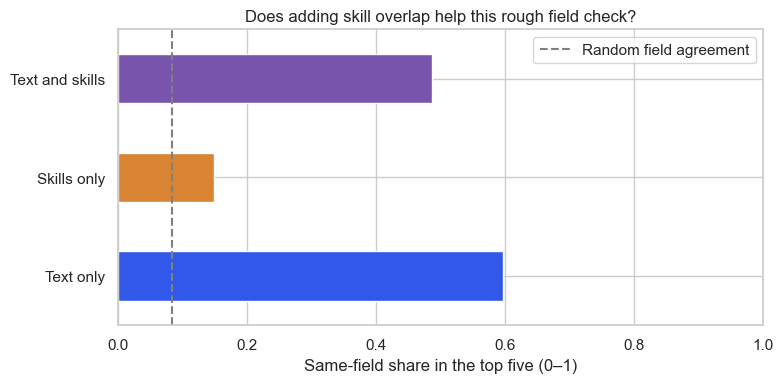

In [11]:
# skills of each labelled posting and of each test resume
job_skill_sets = [find_skills(text) for text in labelled_jobs['job_body']]
resume_skill_sets = [find_skills(text) for text in df_model.loc[in_scope, 'Resume_notitle']]
skill_similarity = np.array([[skill_overlap(r, j) for j in job_skill_sets] for r in resume_skill_sets])

# scale each score so the best posting for a resume gets 1, then average the two
def scale(scores):
    return scores / np.maximum(scores.max(axis=1, keepdims=True), 1e-9)

combined = (scale(text_similarity) + scale(skill_similarity)) / 2

comparison = pd.DataFrame({'precision@5': {
    'Text only': top5_hits(text_similarity).mean(),
    'Skills only': top5_hits(skill_similarity).mean(),
    'Text and skills': top5_hits(combined).mean()}})
display(comparison.round(3))
print('Chance level:', round(chance_jobs, 3))

comparison['precision@5'].plot.barh(figsize=(8,4),color=['#3158E8','#D98432','#7854AD'])
baseline_line = plt.axvline(chance_jobs,color='gray',linestyle='--',label='Random field agreement')
plt.xlim(0,1); plt.xlabel('Same-field share in the top five (0–1)')
plt.title('Does adding skill overlap help this rough field check?'); plt.legend(handles=[baseline_line])
plt.tight_layout(); plt.show()

### Run the original word-based recommendation pipeline

The function shows related postings and skill names mentioned by each posting but not by the profile. These are items to check, not confirmed skill deficiencies. Section 4 adds the semantic version.

In [20]:
# the closest postings for a resume, and the skills each one asks for that the resume does not show
def recommend(resume_text, top_k=3):
    resume_skills = find_skills(resume_text)
    for job_index, row in match(resume_text, top_k).iterrows():
        job_skills = find_skills(early_jobs.loc[job_index, 'job_text'])
        print(f"{row['title']} ({row['company_name']}), similarity {row['similarity']}")
        print('   Job skills not mentioned in the profile:', sorted(job_skills - resume_skills)[:8])

for category in ['HR', 'INFORMATION-TECHNOLOGY']:
    resume_text = test_resumes[test_resumes['Category'] == category].iloc[1]['Resume_notitle']
    print('\nResume category:', category)
    recommend(resume_text)


Resume category: HR


HR Coordinator (Vaco), similarity 0.32
   Job skills not mentioned in the profile: ['accounting', 'company policies', 'comply with regulations', 'employment law', 'statistics', 'work independently']
Talent Acquisition Coordinator (DPR Construction), similarity 0.28
   Job skills not mentioned in the profile: ['adjust to physical demands']
Human Resources Administrator (McGriff Tire & Service), similarity 0.26
   Job skills not mentioned in the profile: ['act reliably', 'comply with regulations', 'demonstrate trustworthiness', 'recruit employees', 'support managers']

Resume category: INFORMATION-TECHNOLOGY


SQL Support Engineer (TEKsystems), similarity 0.16
   Job skills not mentioned in the profile: ['SQL Server', 'database', 'detect bottlenecks', 'install software', 'report facts', 'show initiative', 'statistics', 'test hardware']
Digital Content Coordinator (APX Construction Group), similarity 0.16
   Job skills not mentioned in the profile: ['WordPress', 'adobe creative suite', 'assume responsibility', 'attend to detail', 'design management', 'maintain concentration for long periods', 'motion graphics', 'report facts']
Marketing Content Coordinator (AVIRE), similarity 0.16
   Job skills not mentioned in the profile: ['English', 'WordPress', 'adjust to physical demands', 'adobe creative suite', 'assume responsibility', 'channel marketing', 'customer relationship management', 'customer service']


# 4. Semantic matching

## 4.1 Compare meaning with word matching

Our main app approach compares what a profile and job description mean. A pretrained sentence encoder converts text into numbers; closer numbers mean more related text. Its technical model ID is recorded below for reproducibility.

We compare all methods using the **same** small, fixed set of jobs and held-out CVs. LSA learns word patterns from training CVs. The sentence encoder was trained previously by its publisher and stays unchanged here. Neither uses the test category labels for fitting.

The chart checks whether the top five jobs share a CV's field. The field labels come from title keywords, so this is a rough check, not verified relevance or hiring probability. We do not choose settings from this test.

In [21]:
# Fixed sample keeps the comparison practical on a CPU.
benchmark_jobs = labelled_jobs.groupby('title_category', group_keys=False).head(20).copy()
benchmark_cvs = (df_model.loc[in_scope].groupby('Category', group_keys=False)
                 .sample(n=3, random_state=42).copy())
job_labels = benchmark_jobs['title_category'].to_numpy()
cv_labels = benchmark_cvs['Category'].to_numpy()
job_texts = benchmark_jobs['job_body'].fillna('').tolist()
cv_texts = benchmark_cvs['Resume_notitle'].fillna('').tolist()

def field_agreement(scores):
    order = np.argsort(-scores, axis=1, kind='stable')[:, :5]
    return (job_labels[order] == cv_labels[:, None]).mean()

comparison, benchmark_scores = [], {}
for name, method in representations.items():
    model = clone(method).fit(df_model.loc[train_idx, 'Resume_notitle'])
    scores = cosine_similarity(model.transform(cv_texts), model.transform(job_texts))
    benchmark_scores[name] = scores
    comparison.append({'Method': name, 'Same-field share in top five': field_agreement(scores)})
print(f'Comparison uses {len(cv_texts)} held-out CVs and {len(job_texts)} jobs.')

Comparison uses 36 held-out CVs and 240 jobs.


## 4.2 Load the semantic model

We use the same encoder and text-length settings as the app. Long documents are split into overlapping pieces; at most four pieces are sampled and their vectors averaged. This limits processing time, but some details can be missed. The first run downloads the public model; later runs can use a saved copy.

C:\Users\HAFSA\OneDrive - Strathmore University\Documents\ChatGPT\uplift\.venv-ai\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Batches:   0%|          | 0/26 [00:00<?, ?it/s]

Batches:   4%|▍         | 1/26 [00:03<01:17,  3.10s/it]

Batches:   8%|▊         | 2/26 [00:05<01:03,  2.66s/it]

Batches:  12%|█▏        | 3/26 [00:07<00:55,  2.39s/it]

Batches:  15%|█▌        | 4/26 [00:09<00:49,  2.25s/it]

... (25 outputs left out)

Batches:  60%|██████    | 3/5 [00:06<00:04,  2.20s/it]

Batches:  80%|████████  | 4/5 [00:08<00:02,  2.02s/it]

Batches: 100%|██████████| 5/5 [00:08<00:00,  1.68s/it]

,Same-field share in top five
Method,
Word counts,0.522
TF-IDF,0.544
TF-IDF + LSA,0.633
Semantic matching,0.622


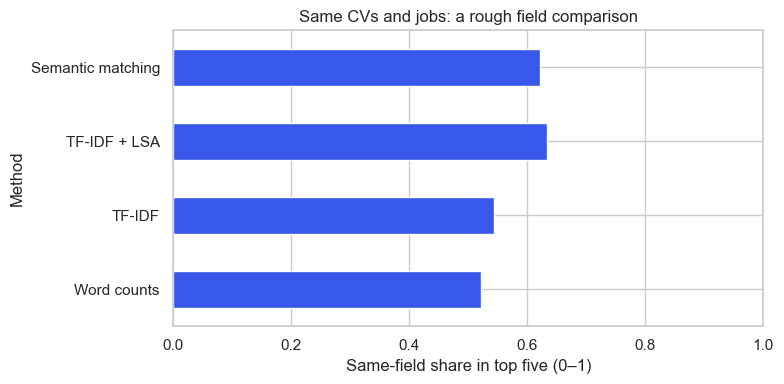

In [22]:
import torch
from sentence_transformers import SentenceTransformer

MODEL_ID = 'sentence-transformers/all-MiniLM-L6-v2'
MODEL_REVISION = '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'
torch.set_num_threads(2)
saved_encoder = os.environ.get('UPSHIFT_ENCODER_PATH')
encoder = (SentenceTransformer(saved_encoder, device='cpu', local_files_only=True)
           if saved_encoder else SentenceTransformer(MODEL_ID, revision=MODEL_REVISION, device='cpu'))
encoder.max_seq_length = 256

def chunks(text):
    words = str(text).split()
    starts = list(range(0, len(words), 120)) or [0]
    if len(starts) > 4:
        starts = [starts[i] for i in np.linspace(0, len(starts) - 1, 4, dtype=int)]
    return [' '.join(words[i:i + 160]) for i in starts]

def encode_texts(texts):
    groups = [chunks(text) for text in texts]
    vectors = encoder.encode([part for group in groups for part in group],
                             batch_size=32, normalize_embeddings=True, show_progress_bar=True)
    rows, offset = [], 0
    for group in groups:
        row = vectors[offset:offset + len(group)].mean(axis=0)
        rows.append(row / max(np.linalg.norm(row), 1e-12))
        offset += len(group)
    return np.asarray(rows)

semantic_jobs = encode_texts(job_texts)
semantic_cvs = encode_texts(cv_texts)
semantic_scores = semantic_cvs @ semantic_jobs.T
benchmark_scores['Semantic matching'] = semantic_scores
comparison.append({'Method': 'Semantic matching',
                   'Same-field share in top five': field_agreement(semantic_scores)})
comparison = pd.DataFrame(comparison).set_index('Method')
display(comparison.round(3))
comparison.plot.barh(legend=False, figsize=(8, 4), color='#3858E9')
plt.xlim(0, 1)
plt.xlabel('Same-field share in top five (0–1)')
plt.title('Same CVs and jobs: a rough field comparison')
plt.tight_layout(); plt.show()

## 4.3 Try different profiles

These fictional examples check that rankings respond to different inputs. Empty or unusable text is rejected. An unfamiliar but readable profile may still produce weak suggestions: a positive similarity alone does not prove suitability. Scores below show text similarity, not a chance of being hired.

The demonstration uses postings marked internship or entry level. This is a basic research filter; the live backend checks approved vacancies and other eligibility rules separately. The small comparison above does not establish one best method for every student.


Computing graduate


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 22.05it/s]

,title,company_name,Text similarity,Job skill mentions to check
69,Software Engineer,Vernovis,0.462,"ASP.NET, C#, Java (computer programming), SQL ..."
125,Finance Associate- Entry Level,Curative,0.330,"accounting, attend to detail, business knowled..."
115,Fund Accountant,Arrow Search Partners,0.306,"accounting, assume responsibility, financial s..."



Accounting graduate


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 51.24it/s]

,title,company_name,Text similarity,Job skill mentions to check
125,Finance Associate- Entry Level,Curative,0.651,"attend to detail, business knowledge, communic..."
145,Accountant,Vaco,0.644,"attend to detail, communication, economics, ma..."
122,"Project Manager, Finance Transformation",Priceline,0.534,"ICT project management methodologies, SAP Data..."



Invalid input
Please describe your education, skills or experience in a short sentence.


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 32.59it/s]

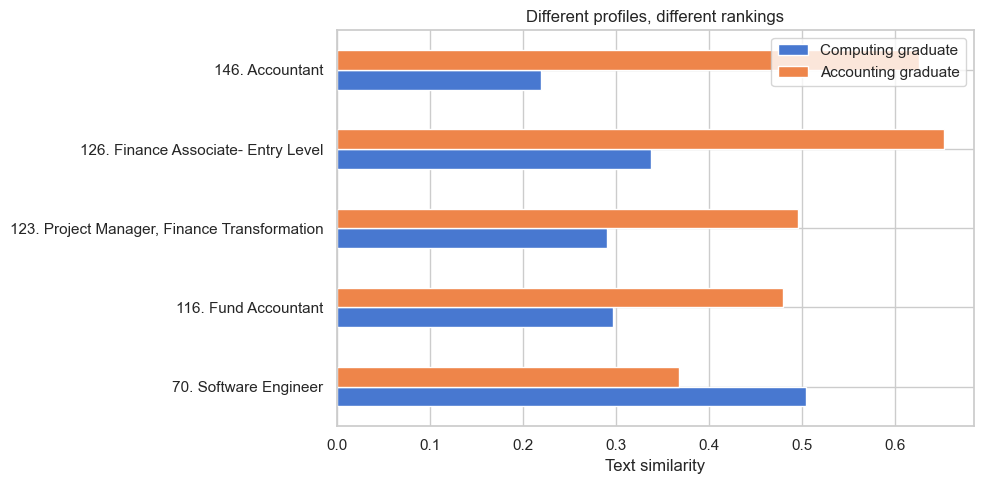

In [8]:
# Restrict the demonstration by the posting's stated experience level.
allowed = np.flatnonzero((benchmark_jobs['is_internship'] |
                          benchmark_jobs['experience_level'].eq('Entry level')).to_numpy())

def semantic_recommend(profile, top_k=3):
    if not isinstance(profile, str) or len(re.findall(r'[a-zA-Z]{2,}', profile)) < 3:
        raise ValueError('Please describe your education, skills or experience in a short sentence.')
    scores = encode_texts([clean_text(profile)])[0] @ semantic_jobs.T
    if not len(allowed): raise ValueError('No internship or entry-level postings in this sample.')
    order = allowed[np.argsort(-scores[allowed], kind='stable')[:top_k]]
    answer = benchmark_jobs.iloc[order][['title', 'company_name']].copy()
    answer['Text similarity'] = scores[order].round(3)
    profile_skills = find_skills(clean_text(profile))
    answer['Job skill mentions to check'] = [
        ', '.join(sorted(find_skills(job_texts[i]) - profile_skills)[:6]) for i in order]
    return answer

examples = {
    'Computing graduate': 'Computing graduate with Python, JavaScript, SQL and Git. Built web applications and tested REST APIs.',
    'Accounting graduate': 'Accounting graduate with bookkeeping, Excel, financial reporting and reconciliation experience.',
    'Invalid input': ''
}
for name, profile in examples.items():
    print('\n' + name)
    try:
        display(semantic_recommend(profile))
    except ValueError as error:
        print(error)

# Show how the two valid profiles rank the same research catalogue.
example_vectors = encode_texts(list(examples.values())[:2])
example_scores = example_vectors @ semantic_jobs.T
selected = np.unique(allowed[np.argsort(-example_scores[:, allowed], axis=1)[:, :3]])
labels = [f'{i + 1}. {benchmark_jobs.iloc[i]["title"][:48]}' for i in selected]
pd.DataFrame(example_scores[:, selected].T, index=labels,
             columns=list(examples)[:2]).plot.barh(figsize=(10, 5))
plt.xlabel('Text similarity'); plt.title('Different profiles, different rankings')
plt.tight_layout(); plt.show()

## 4.4 Save the research models and conclusions

We save the trained title-free logistic regression classifier, semantic encoder and comparison results. The classifier predicts career categories; the encoder supports meaning-based ranking. These files preserve the research experiments. Section 5 then produces the complete backend bundle using the app functions included in this notebook.

The checks show category classification, rough field agreement and response to sample inputs. They do not establish hiring success, Kenyan eligibility or verified recommendation accuracy. Human relevance ratings and the skill review remain pending. No new deployment is made by running this notebook.

In [24]:
import joblib

research_dir = Path(OUT_DIR).parent / 'research_models'
research_dir.mkdir(parents=True, exist_ok=True)
classifier = fitted[('Logistic regression', 'Without title')]
joblib.dump(classifier, research_dir / 'LogisticRegression_CV_Category.joblib')
encoder.save(str(research_dir / 'semantic_encoder'))
comparison.to_csv(research_dir / 'matching_comparison.csv')
benchmark_jobs[['job_id', 'title', 'company_name', 'job_body', 'title_category']].to_csv(
    research_dir / 'research_jobs.csv', index=False)
np.save(research_dir / 'semantic_job_vectors.npy', semantic_jobs)
restored_classifier = joblib.load(research_dir / 'LogisticRegression_CV_Category.joblib')
assert np.array_equal(classifier.predict(cv_texts), restored_classifier.predict(cv_texts))
print('Saved research models and checked classifier reload:', research_dir)

Saved research models and checked classifier reload: C:\Users\HAFSA\OneDrive - Strathmore University\Documents\ChatGPT\uplift\output\restored_notebook_validation\UpShift_Final_Output\research_models


# 5. The same model used by the app

Keep Sections 1–4 as our original work and comparison. Here we build the actual backend files: the same text preparation, skill rules, job ranking and feedback classifier. All project functions needed for this are included below, with every cell visible. The original base notebook remains unchanged in the repository.

The backend separately handles accounts, approved vacancies, expiry and location/experience checks. Those are application rules, not trained models. Saving feedback and the guided chatbot are also app features.

In [3]:
import sys, json, shutil, hashlib, importlib, os
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

APP_WORK = Path(OUT_DIR).parent / 'live_app'
APP_WORK.mkdir(parents=True, exist_ok=True)
(APP_WORK / 'upshift_ai').mkdir(exist_ok=True)
os.chdir(APP_WORK)
sys.path.insert(0, str(APP_WORK))
DATA, RESULTS, ARTIFACTS = [APP_WORK / name for name in ['data', 'results', 'artifacts']]
for folder in [DATA, RESULTS, ARTIFACTS]: folder.mkdir(exist_ok=True)
print('App-model files will be saved separately from the original research outputs.')

App-model files will be saved separately from the original research outputs.


## 5.1 Shared app functions — code review

These are the actual app functions, divided into small groups for code review. They are written into a local Python package so the saved model loads in the backend. Continue to 5.2 for the short walkthrough.

`writefile` saves the following code. `-a` adds the next part to the same file; this keeps the model-loading code together.

### Package information

This records the version of our shared app functions.

In [4]:
%%writefile upshift_ai/__init__.py
"""UpShift NLP: job retrieval, skill evidence and a separate sentiment benchmark."""

__version__ = "1.0.0"

Writing upshift_ai/__init__.py


### Text preparation

Remove web formatting, links and obvious opening career titles, while keeping technical names such as C++.

In [5]:
%%writefile upshift_ai/preprocessing.py
"""Shared preprocessing for training and serving."""

import html
import re
import unicodedata

TOKEN_PATTERN = r"(?u)(?:\.net\b|\b\w+(?:[.+#-]\w+)*(?:\+\+|#)?)"
SECTION_WORDS = {
    "summary",
    "skills",
    "experience",
    "education",
    "objective",
    "profile",
    "highlights",
    "qualifications",
    "career",
    "professional",
}

Writing upshift_ai/preprocessing.py


In [6]:
%%writefile -a upshift_ai/preprocessing.py
def plain_text(value):
    if not isinstance(value, str):
        return ""
    value = html.unescape(unicodedata.normalize("NFKC", value))
    value = re.sub(r"<[^>]+>", " ", value)
    return value.replace("\r\n", "\n").replace("\r", "\n").strip()

Appending to upshift_ai/preprocessing.py


In [7]:
%%writefile -a upshift_ai/preprocessing.py
def clean_text(value):
    value = plain_text(value).lower()
    value = re.sub(r"https?://\S+|www\.\S+|\S+@\S+", " ", value)
    return re.sub(r"\s+", " ", re.sub(r"[^\w+#.\s-]", " ", value)).strip()

Appending to upshift_ai/preprocessing.py


In [8]:
%%writefile -a upshift_ai/preprocessing.py
def prepare_resume(value):
    value = plain_text(value)
    for _ in range(2):
        pieces = re.split(r"\s{2,}|\n", value, maxsplit=1)
        chunk = pieces[0]
        letters = [c for c in chunk if c.isalpha()]
        first = (re.findall(r"[a-z]+", chunk.lower()) or [""])[0]
        if (
            len(pieces) == 2
            and 0 < len(chunk) <= 80
            and letters
            and sum(c.isupper() for c in letters) / len(letters) > 0.8
            and first not in SECTION_WORDS
        ):
            value = pieces[1].lstrip()
        else:
            break
    value = re.sub(r"\bcompany name\b|\bcity\s*,?\s*state\b", " ", value, flags=re.I)
    return clean_text(value)

Appending to upshift_ai/preprocessing.py


In [9]:
%%writefile -a upshift_ai/preprocessing.py
def segments(value):
    value = plain_text(value)
    return [
        part.strip(" -\t")
        for part in re.split(
            r"\n+|[;•]|(?<=[.!?])\s+(?=[A-Z0-9])|\bbut\b|\bhowever\b", value, flags=re.I
        )
        if part.strip()
    ]

Appending to upshift_ai/preprocessing.py


### Skill names, required skills and optional skills

Join alternative skill spellings to one name. Use ESCO plus explicitly marked project additions. Check sentence context so optional or negated mentions are not automatically treated as requirements.

In [10]:
%%writefile upshift_ai/skills.py
"""Conservative ESCO extraction with stable concept IDs and contextual evidence."""

from dataclasses import dataclass
from collections import defaultdict
import re
from .preprocessing import clean_text, plain_text, segments, TOKEN_PATTERN

MANUAL = {
    "Python": (
        [
            "python",
            "python programming",
            "python language",
            "python (computer programming)",
        ],
        ["Python (computer programming)"],
    ),
    "Java": (
        ["java", "java programming", "java (computer programming)"],
        ["Java (computer programming)"],
    ),
    "JavaScript": (["javascript", "js"], ["JavaScript"]),
    "TypeScript": (["typescript"], ["TypeScript"]),
    "SQL": (["sql", "structured query language"], ["SQL"]),
    "HTML": (["html", "html5"], ["HTML"]),
    "CSS": (["css", "css3"], ["CSS"]),
    "C++": (["c++"], ["C++"]),
    "C#": (["c#", "c sharp"], ["C#"]),
    ".NET": ([".net", "dotnet", "dot net"], [".NET"]),
    "Node.js": (["node.js", "nodejs", "node js"], ["Node.js"]),
    "React": (["react", "react.js", "reactjs"], []),
    "React Native": (["react native"], []),
    "Kotlin": (["kotlin"], ["Kotlin"]),
    "Android": (["android", "android sdk"], []),
    "Firebase": (["firebase"], []),
    "Git": (["git", "git version control"], ["Git"]),
    "Docker": (["docker", "docker containers"], []),
    "Excel": (["excel", "ms excel", "microsoft excel"], ["Microsoft Excel"]),
    "Figma": (["figma"], []),
    "Canva": (["canva"], []),
    "Teamwork": (["teamwork", "team work"], []),
    "Communication": (
        ["communication skills", "written communication", "verbal communication"],
        [],
    ),
    "MySQL": (["mysql"], ["MySQL"]),
    "PostgreSQL": (["postgresql", "postgres"], ["PostgreSQL"]),
    "Linux": (["linux"], ["Linux"]),
    "REST APIs": (["rest api", "rest apis", "restful api", "restful apis"], []),
    "Testing": (["unit testing", "software testing", "automated testing"], []),
    "Research": (["user research", "usability research"], []),
    "Accessibility": (["web accessibility", "digital accessibility", "wcag"], []),
}
AMBIGUOUS = {
    "plan",
    "stand",
    "commitment",
    "less",
    "react",
    "integrity",
    "reliability",
    "history",
    "pregnancy",
    "morality",
    "banking",
    "call",
    "support",
    "english",
    "assume responsibility",
    "approach challenges positively",
}
TECH_SINGLE = {
    clean_text(a)
    for name, (aliases, _) in MANUAL.items()
    for a in aliases
    if " " not in a
}

Writing upshift_ai/skills.py


In [11]:
%%writefile -a upshift_ai/skills.py
@dataclass
class SkillLexicon:
    aliases: dict
    concepts: dict
    audit: dict

Appending to upshift_ai/skills.py


In [12]:
%%writefile -a upshift_ai/skills.py
    def __post_init__(self):
        self.trie = {}
        for alias, sid in self.aliases.items():
            tokens = re.findall(TOKEN_PATTERN, alias)
            if not tokens:
                continue
            node = self.trie
            for token in tokens:
                node = node.setdefault(token, {})
            node["_id"] = sid

Appending to upshift_ai/skills.py


In [13]:
%%writefile -a upshift_ai/skills.py
    def find(self, text):
        cleaned = clean_text(text)
        tokens = re.findall(TOKEN_PATTERN, cleaned)
        hits = []
        i = 0
        while i < len(tokens):
            node = self.trie
            j = i
            best = None
            while j < len(tokens) and tokens[j] in node:
                node = node[tokens[j]]
                j += 1
                if "_id" in node:
                    best = (j, node["_id"])
            if best:
                end, sid = best
                alias = " ".join(tokens[i:end])
                before = " ".join(tokens[max(0, i - 6) : i])
                after = " ".join(tokens[end : end + 5])
                neg = bool(
                    re.search(r"\b(?:no|not|without|lack|lacking|never)\b", before)
                    or re.search(
                        r"^(?:is |are )?(?:not required|not necessary|not needed|isn t required)",
                        after,
                    )
                )
                if "not only" in before:
                    neg = False
                if alias == "react" and not (
                    re.search(
                        r"\b(?:javascript|frontend|front-end|framework|jsx|web|skills)\b",
                        cleaned,
                    )
                    or re.search(r"\bReact\b", text)
                ):
                    i = end
                    continue
                hits.append(
                    {
                        "id": sid,
                        "label": self.concepts[sid]["label"],
                        "alias": alias,
                        "negated": neg,
                        "evidence": text[:400],
                    }
                )
                i = end
            else:
                i += 1
        return hits

Appending to upshift_ai/skills.py


In [14]:
%%writefile -a upshift_ai/skills.py
    def profile_skills(self, text):
        return {
            h["id"]
            for part in segments(text)
            for h in self.find(part)
            if not h["negated"]
        }

Appending to upshift_ai/skills.py


In [15]:
%%writefile -a upshift_ai/skills.py
    def job_skills(self, text):
        found = {
            "required": set(),
            "preferred": set(),
            "mentioned": set(),
            "excluded": set(),
        }
        evidence = []
        mode = "mentioned"
        for part in segments(text):
            lower = part.lower()
            if re.search(
                r"^(?:responsibilities|what you.ll do|about us|about the company|benefits|we offer|our team)\b",
                lower,
            ):
                mode = "mentioned"
            if re.search(
                r"^(?:requirements|qualifications|essential|what you bring|what you.ll need|skills required|technical skills|minimum qualifications)\b",
                lower,
            ):
                mode = "required"
            if re.search(r"^(?:preferred|nice to have|desirable|bonus)\b", lower):
                mode = "preferred"
            current = mode
            if re.search(
                r"\b(?:preferred|nice to have|optional|a plus|desirable|bonus)\b", lower
            ):
                current = "preferred"
            elif re.search(
                r"\b(?:must|required|essential|proficien\w*|knowledge of|experience (?:with|in)|ability to|familiarity with)\b",
                lower,
            ):
                current = "required"
            sentence_negated = (
                bool(re.search(r"not required|not necessary|not needed", lower))
                and not re.search(r"\b(?:is|are) required\b", lower)
                and current != "preferred"
            )
            for hit in self.find(part):
                sid = hit["id"]
                if hit["negated"] or sentence_negated:
                    # "preferred but not required" is handled as a preference, never a requirement.
                    if (
                        current == "preferred"
                        and re.search(r"not required|not necessary", lower)
                        and not re.search(
                            r"\bno (?:experience|knowledge)|\bwithout\b", lower
                        )
                    ):
                        found["preferred"].add(sid)
                    else:
                        found["excluded"].add(sid)
                else:
                    found[current].add(sid)
                evidence.append({**hit, "kind": current})
        found["preferred"] -= found["required"]
        found["mentioned"] -= found["required"] | found["preferred"]
        return {**{k: sorted(v) for k, v in found.items()}, "evidence": evidence}

Appending to upshift_ai/skills.py


In [16]:
%%writefile -a upshift_ai/skills.py
def build_lexicon(frame):
    frame = frame.fillna("").drop_duplicates("conceptUri")
    concepts = {}
    candidates = defaultdict(set)
    preferred = {}
    for row in frame.to_dict("records"):
        sid = row["conceptUri"]
        label = row["preferredLabel"].strip()
        if not sid or not label:
            continue
        concepts[sid] = {
            "label": label,
            "source": "ESCO",
            "type": row.get("skillType", ""),
        }
        preferred[clean_text(label)] = sid
        for alias in (
            [label]
            + str(row.get("altLabels", "")).split("\n")
            + str(row.get("hiddenLabels", "")).split("\n")
        ):
            alias = clean_text(alias)
            if (
                not alias
                or alias in AMBIGUOUS
                or (len(alias) < 3 and alias not in {"c#", "c++"})
            ):
                continue
            if " " not in alias and alias not in TECH_SINGLE:
                continue
            candidates[alias].add(sid)
    clashes = {a: sorted(ids) for a, ids in candidates.items() if len(ids) > 1}
    aliases = {a: next(iter(ids)) for a, ids in candidates.items() if len(ids) == 1}
    for name, (spellings, targets) in MANUAL.items():
        sid = next(
            (preferred[clean_text(t)] for t in targets if clean_text(t) in preferred),
            None,
        )
        if sid is None:
            sid = "urn:upshift:skill:" + re.sub(r"[^a-z0-9]+", "-", name.lower()).strip(
                "-"
            )
        concepts[sid] = {
            "label": name,
            "source": "ESCO" if sid.startswith("http") else "UpShift extension",
            "type": "knowledge",
        }
        # Keep all existing synonyms for the selected concept, and assign new synonyms to that same ID.
        for alias in spellings:
            aliases[clean_text(alias)] = sid
    return SkillLexicon(
        aliases,
        concepts,
        {
            "ambiguous_aliases_excluded": clashes,
            "alias_count": len(aliases),
            "concept_count": len(concepts),
        },
    )

Appending to upshift_ai/skills.py

### Meaning-based text comparison

Turn text into number lists that can be compared. Long documents use at most four sampled pieces; the pretrained model stays unchanged.

In [17]:
%%writefile upshift_ai/semantic.py
"""Chunked local embeddings; no document text is sent to hosted inference."""

import hashlib, json
from pathlib import Path
import numpy as np

MODEL_ID = "sentence-transformers/all-MiniLM-L6-v2"
MODEL_REVISION = "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"

Writing upshift_ai/semantic.py


In [18]:
%%writefile -a upshift_ai/semantic.py
def text_chunks(text, words=160, stride=120, max_chunks=4):
    tokens = str(text).split()
    if not tokens:
        return [""]
    starts = list(range(0, len(tokens), stride))
    if len(starts) > max_chunks:
        starts = [
            starts[i] for i in np.linspace(0, len(starts) - 1, max_chunks, dtype=int)
        ]
    return [" ".join(tokens[i : i + words]) for i in starts]

Appending to upshift_ai/semantic.py


In [19]:
%%writefile -a upshift_ai/semantic.py
def load_encoder(path=None):
    import torch
    from sentence_transformers import SentenceTransformer

    torch.set_num_threads(2)
    if path is not None:
        path = Path(path).resolve(strict=True)
        model = SentenceTransformer(str(path), device="cpu", local_files_only=True)
    else:
        model = SentenceTransformer(MODEL_ID, revision=MODEL_REVISION, device="cpu")
    model.max_seq_length = 256
    return model

Appending to upshift_ai/semantic.py


In [20]:
%%writefile -a upshift_ai/semantic.py
def encode_documents(model, texts, cache_path=None):
    digest = hashlib.sha256(
        json.dumps(list(texts), ensure_ascii=False).encode()
    ).hexdigest()
    settings = {
        "model": MODEL_ID,
        "revision": MODEL_REVISION,
        "max_chunks": 4,
        "words_per_chunk": 160,
        "stride": 120,
        "max_seq_length": 256,
    }
    if cache_path:
        cache_path = Path(cache_path)
        meta = cache_path.with_suffix(".json")
        if cache_path.exists() and meta.exists():
            saved = json.loads(meta.read_text())
            if saved.get("sha256") == digest and all(
                saved.get(k) == v for k, v in settings.items()
            ):
                return np.load(cache_path)
    groups = [text_chunks(t) for t in texts]
    flat = [c for group in groups for c in group]
    print(f"Embedding {len(texts)} documents in {len(flat)} sampled chunks", flush=True)
    embeddings = model.encode(
        flat,
        batch_size=32,
        normalize_embeddings=True,
        show_progress_bar=True,
        convert_to_numpy=True,
    )
    rows = []
    pos = 0
    for group in groups:
        vector = embeddings[pos : pos + len(group)].mean(axis=0)
        pos += len(group)
        rows.append(vector / max(np.linalg.norm(vector), 1e-12))
    vectors = np.asarray(rows, dtype=np.float32)
    if cache_path:
        np.save(cache_path, vectors)
        meta.write_text(json.dumps({"sha256": digest, **settings}))
    return vectors

Appending to upshift_ai/semantic.py


### Search the research catalogue

Rank the saved research postings and return skill evidence. Historical records are kept separate from live vacancies.

In [21]:
%%writefile upshift_ai/matching.py
"""Shared recommendation contract for the notebook and Python service."""

import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from .preprocessing import prepare_resume

Writing upshift_ai/matching.py

In [22]:
%%writefile -a upshift_ai/matching.py
def recommend(
    bundle,
    resume_text,
    top_k=5,
    method="lexical",
    min_similarity=0.0,
    encoder=None,
    live_only=False,
):
    if not isinstance(resume_text, str) or not resume_text.strip():
        raise ValueError("Provide non-empty profile or CV text.")
    if len(resume_text) > 50000:
        raise ValueError("CV text exceeds 50,000 characters.")
    if isinstance(top_k, bool) or not isinstance(top_k, int) or not 1 <= top_k <= 20:
        raise ValueError("top_k must be an integer between 1 and 20.")
    if method not in {"lexical", "semantic"}:
        raise ValueError("method must be lexical or semantic.")
    if not isinstance(min_similarity, (float, int)) or not 0 <= min_similarity <= 1:
        raise ValueError("min_similarity must be in [0,1].")
    vector = bundle["retriever"].transform([prepare_resume(resume_text)])
    if vector.nnz == 0:
        return {
            "status": "no_match",
            "method": method,
            "matches": [],
            "catalogue_status": "historical_research_not_live",
        }
    if method == "semantic":
        if encoder is None:
            raise ValueError("Semantic encoder must be loaded for semantic requests.")
        from .semantic import encode_documents

        scores = (
            encode_documents(encoder, [prepare_resume(resume_text)])
            @ bundle["semantic_vectors"].T
        ).ravel()
    else:
        scores = cosine_similarity(vector, bundle["job_vectors"]).ravel()
    profile_skills = bundle["lexicon"].profile_skills(resume_text)
    order = np.argsort(-scores, kind="stable")
    matches = []
    for pos in order:
        if len(matches) >= top_k:
            break
        score = float(scores[pos])
        if score <= min_similarity:
            continue
        row = bundle["jobs"].iloc[int(pos)]
        if live_only and (
            bool(row["is_expired"]) or row["eligibility_status"] != "verified"
        ):
            continue
        skillsets = bundle["job_skills"][int(pos)]
        required = set(skillsets["required"])
        preferred = set(skillsets["preferred"])

        def present(ids):
            return [
                {"id": sid, "label": bundle["lexicon"].concepts[sid]["label"]}
                for sid in sorted(
                    ids, key=lambda x: bundle["lexicon"].concepts[x]["label"]
                )
            ]

        matched = required & profile_skills
        unmentioned = required - profile_skills
        coverage = len(matched) / len(required) if required else None
        matches.append(
            {
                "job_id": str(row.job_id),
                "title": str(row.title),
                "company_name": str(row.company_name),
                "description": str(row.description),
                "location": str(row.location),
                "work_type": str(row.formatted_work_type),
                "experience_level": str(row.formatted_experience_level),
                "similarity": round(score, 6),
                "ranking_method": method,
                "skill_coverage": coverage,
                "skills_match_percentage": round(coverage * 100)
                if coverage is not None
                else None,
                "matched_skills": present(matched),
                "required_skills_not_mentioned": present(unmentioned),
                "preferred_skills_not_mentioned": present(preferred - profile_skills),
                "mentioned_other_skills": present(set(skillsets["mentioned"])),
                "is_expired": bool(row.is_expired),
                "eligibility_status": str(row.eligibility_status),
                "listed_date": row.listed_time_utc,
                "expiry_date": row.expiry_utc,
                "application_url": str(row.application_url),
                "job_posting_url": str(row.job_posting_url),
            }
        )
    return {
        "status": "matches_found" if matches else "no_match",
        "method": method,
        "catalogue_status": "historical_research_not_live",
        "matches": matches,
    }

Appending to upshift_ai/matching.py


### Train and compare feedback labels

Keep training, validation and testing separate. Compare learned word patterns with VADER’s word rules.

In [23]:
%%writefile upshift_ai/sentiment.py
"""VADER and trained logistic regression compared on the same TweetEval splits."""

from pathlib import Path
import json, urllib.request, time
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk

LABELS = ["negative", "neutral", "positive"]

Writing upshift_ai/sentiment.py


In [24]:
%%writefile -a upshift_ai/sentiment.py
def download_tweeteval(root):
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    manifest = root / "source.json"
    if manifest.exists():
        revision = json.loads(manifest.read_text())["revision"]
    else:
        request = urllib.request.Request(
            "https://api.github.com/repos/cardiffnlp/tweeteval/commits/main",
            headers={"User-Agent": "Upshift academic benchmark"},
        )
        with urllib.request.urlopen(request, timeout=60) as response:
            revision = json.load(response)["sha"]
        manifest.write_text(
            json.dumps(
                {
                    "dataset": "TweetEval sentiment / SemEval-2017 Task 4",
                    "repository": "https://github.com/cardiffnlp/tweeteval",
                    "revision": revision,
                    "use": "external English sentiment benchmark, not evidence of performance on Kenyan app feedback",
                }
            )
        )
    for split in ["train", "val", "test"]:
        for kind in ["text", "labels"]:
            path = root / f"{split}_{kind}.txt"
            if not path.exists():
                url = f"https://raw.githubusercontent.com/cardiffnlp/tweeteval/{revision}/datasets/sentiment/{split}_{kind}.txt"
                with urllib.request.urlopen(url, timeout=90) as response:
                    path.write_bytes(response.read())
    frames = {}
    seen = set()
    audit = {}
    for split in ["train", "val", "test"]:
        texts = (root / f"{split}_text.txt").read_text(encoding="utf-8").splitlines()
        labels = (root / f"{split}_labels.txt").read_text().splitlines()
        if len(texts) != len(labels):
            raise ValueError("Sentiment texts and labels have different lengths.")
        df = pd.DataFrame({"text": texts, "label": [LABELS[int(n)] for n in labels]})
        df["key"] = df.text.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
        before = len(df)
        conflict = df.groupby("key").label.nunique()
        ambiguous = set(conflict[conflict > 1].index)
        df = (
            df[df.key.ne("") & ~df.key.isin(ambiguous) & ~df.key.isin(seen)]
            .drop_duplicates("key")
            .copy()
        )
        seen.update(df.key)
        frames[split] = df.reset_index(drop=True)
        audit[split] = {
            "original": before,
            "used": len(df),
            "removed_blank_duplicate_or_conflict": before - len(df),
            "classes": df.label.value_counts().to_dict(),
        }
    return frames, audit

Appending to upshift_ai/sentiment.py


In [25]:
%%writefile -a upshift_ai/sentiment.py
def vader_labels(vader, texts, threshold=0.05):
    values = np.array([vader.polarity_scores(str(text))["compound"] for text in texts])
    return np.where(
        values >= threshold,
        "positive",
        np.where(values <= -threshold, "negative", "neutral"),
    )

Appending to upshift_ai/sentiment.py


In [26]:
%%writefile -a upshift_ai/sentiment.py
def metric_row(name, true, pred, seconds=None):
    return {
        "method": name,
        "accuracy": accuracy_score(true, pred),
        "macro_f1": f1_score(true, pred, average="macro", zero_division=0),
        "prediction_seconds": seconds,
    }

Appending to upshift_ai/sentiment.py


In [27]:
%%writefile -a upshift_ai/sentiment.py
def sentiment_benchmark(data_root, results_root):
    results_root = Path(results_root)
    frames, audit = download_tweeteval(Path(data_root) / "sentiment")
    nltk_root = Path(data_root) / "nltk"
    nltk_root.mkdir(exist_ok=True)
    nltk.data.path.insert(0, str(nltk_root))
    nltk.download(
        "vader_lexicon", download_dir=str(nltk_root), quiet=True, raise_on_error=True
    )
    vader = SentimentIntensityAnalyzer()
    train, val, test = [frames[k] for k in ["train", "val", "test"]]
    candidates = []
    models = {}
    for c in [0.5, 2.0]:
        for weight in [None, "balanced"]:
            name = f"Logistic regression C={c}, weight={weight}"
            model = Pipeline(
                [
                    (
                        "tfidf",
                        TfidfVectorizer(
                            ngram_range=(1, 2),
                            min_df=2,
                            max_features=80000,
                            sublinear_tf=True,
                            strip_accents="unicode",
                        ),
                    ),
                    (
                        "classifier",
                        LogisticRegression(
                            C=c,
                            class_weight=weight,
                            max_iter=1000,
                            solver="lbfgs",
                            random_state=42,
                        ),
                    ),
                ]
            )
            print("Training sentiment:", name, flush=True)
            model.fit(train.text, train.label)
            candidates.append(metric_row(name, val.label, model.predict(val.text)))
            models[name] = model
    dev = pd.DataFrame(candidates).sort_values("macro_f1", ascending=False)
    best = dev.iloc[0]["method"]
    model = models[best]
    # Freeze selection on validation data; final test is evaluated only after selection.
    thresholds = [0.05, 0.1, 0.2, 0.3]
    threshold = max(
        thresholds,
        key=lambda t: f1_score(
            val.label,
            vader_labels(vader, val.text, t),
            average="macro",
            zero_division=0,
        ),
    )
    validation_vader = f1_score(
        val.label,
        vader_labels(vader, val.text, threshold),
        average="macro",
        zero_division=0,
    )
    selected = (
        "logistic" if float(dev.iloc[0].macro_f1) >= validation_vader else "vader"
    )
    predictors = {
        "Majority baseline": lambda: np.repeat(train.label.mode().iloc[0], len(test)),
        "VADER default": lambda: vader_labels(vader, test.text, 0.05),
        "VADER validation-tuned": lambda: vader_labels(vader, test.text, threshold),
        "TF-IDF + logistic regression": lambda: model.predict(test.text),
    }
    rows = []
    reports = {}
    predictions = test[["text", "label"]].copy()
    for name, predict in predictors.items():
        start = time.perf_counter()
        pred = predict()
        rows.append(metric_row(name, test.label, pred, time.perf_counter() - start))
        predictions[name] = pred
        reports[name] = {
            "classification_report": classification_report(
                test.label, pred, labels=LABELS, output_dict=True, zero_division=0
            ),
            "confusion_matrix": confusion_matrix(
                test.label, pred, labels=LABELS
            ).tolist(),
        }
    metrics = pd.DataFrame(rows)
    metrics.to_csv(results_root / "sentiment_metrics.csv", index=False)
    dev.to_csv(results_root / "sentiment_validation.csv", index=False)
    (results_root / "sentiment_reports.json").write_text(json.dumps(reports, indent=2))
    (results_root / "sentiment_data_audit.json").write_text(json.dumps(audit, indent=2))
    predictions.to_csv(results_root / "sentiment_predictions.csv", index=False)
    print(metrics.to_string(index=False), flush=True)
    return {
        "model": model,
        "vader": vader,
        "vader_threshold": float(threshold),
        "selected": selected,
        "selected_logistic_parameters": best,
        "labels": LABELS,
        "source": json.loads((Path(data_root) / "sentiment/source.json").read_text()),
    }, metrics

Appending to upshift_ai/sentiment.py


In [28]:
%%writefile -a upshift_ai/sentiment.py
def analyse_sentiment(bundle, text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Provide non-empty feedback text.")
    if len(text) > 10000:
        raise ValueError("Feedback exceeds 10,000 characters.")
    model = bundle["sentiment"]
    pipe = model["model"]
    probabilities = pipe.predict_proba([text])[0]
    label = str(pipe.classes_[int(np.argmax(probabilities))])
    vader_score = model["vader"].polarity_scores(text)["compound"]
    vader_label = (
        "positive"
        if vader_score >= model["vader_threshold"]
        else "negative"
        if vader_score <= -model["vader_threshold"]
        else "neutral"
    )
    return {
        "label": label if model["selected"] == "logistic" else vader_label,
        "method": "TF-IDF + logistic regression"
        if model["selected"] == "logistic"
        else "VADER validation-tuned",
        "logistic_label": label,
        "logistic_probabilities": dict(
            zip(pipe.classes_.tolist(), [float(x) for x in probabilities])
        ),
        "vader_label": vader_label,
        "vader_compound": float(vader_score),
        "scope": "external English benchmark; not validated on Kenyan app feedback",
    }

Appending to upshift_ai/sentiment.py


### Predictions used by the backend

Load the saved files, reject invalid requests and return ranked jobs or feedback labels. This is the same entry point called by the app backend.

In [29]:
%%writefile upshift_ai/handoff.py
"""Schema-2 inference entry point shared by Member 2 and the delivery API."""

from pathlib import Path
import json
import threading
import joblib
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from .matching import recommend
from .sentiment import analyse_sentiment
from .preprocessing import prepare_resume, clean_text
from .semantic import load_encoder, encode_documents

Writing upshift_ai/handoff.py


In [30]:
%%writefile -a upshift_ai/handoff.py
class ModelService:

Appending to upshift_ai/handoff.py


In [31]:
%%writefile -a upshift_ai/handoff.py
    def __init__(self, artifact_dir, *, bundle_path=None):
        self.root = Path(artifact_dir)
        self.bundle = joblib.load(
            bundle_path
            if bundle_path is not None
            else self.root / "upshift_bundle.joblib"
        )
        if self.bundle.get("schema_version") != 2:
            raise ValueError(
                "Use the delivered schema-2 bundle, not the clear notebook toy export."
            )
        config = json.loads((self.root / "deployment_config.json").read_text())
        self.method = config["selected_method"]
        if self.method not in ("lexical", "semantic"):
            raise ValueError("Unknown selected method")
        self.encoder = None
        self.lock = threading.Lock()

Appending to upshift_ai/handoff.py


In [32]:
%%writefile -a upshift_ai/handoff.py
    def prepare(self):
        """Validate the inference bundle and load the selected encoder before serving."""
        required = {"retriever", "jobs", "lexicon", "job_skills"}
        required.add("semantic_vectors" if self.method == "semantic" else "job_vectors")
        if not required <= self.bundle.keys():
            raise ValueError("The UpShift model bundle is missing required data.")
        if self.method == "semantic":
            self._encoder()

Appending to upshift_ai/handoff.py


In [33]:
%%writefile -a upshift_ai/handoff.py
    def _encoder(self):
        with self.lock:
            if self.encoder is None:
                self.encoder = load_encoder(self.root / "semantic_encoder")
        return self.encoder

Appending to upshift_ai/handoff.py


In [34]:
%%writefile -a upshift_ai/handoff.py
    def recommendations(self, text, top_k=5, live_only=False):
        result = recommend(
            self.bundle,
            text,
            top_k,
            self.method,
            encoder=self._encoder() if self.method == "semantic" else None,
            live_only=live_only,
        )
        return self._metadata(result)

Appending to upshift_ai/handoff.py


In [35]:
%%writefile -a upshift_ai/handoff.py
    def _metadata(self, result):
        for match in result["matches"]:
            # Backwards-compatible names used by the older backend contract.
            match["skills_mentioned"] = [s["label"] for s in match["matched_skills"]]
            match["skills_not_mentioned"] = [
                s["label"] for s in match["required_skills_not_mentioned"]
            ]
        return {
            **result,
            "model_version": "schema-2-ai-assisted-2026-11-22",
            "score_definition": "Cosine text similarity, not a hiring probability. Skill coverage is a separate extracted-skill measure.",
            "validation_status": "single_ai_assisted_review_not_human_validated",
        }

Appending to upshift_ai/handoff.py


In [36]:
%%writefile -a upshift_ai/handoff.py
    def sentiment(self, text):
        return analyse_sentiment(self.bundle, text)

Appending to upshift_ai/handoff.py


In [37]:
%%writefile -a upshift_ai/handoff.py
    def rank_vacancies(self, text, vacancies, top_k=5):
        """Rank backend-supplied vacancies; caller must approve/filter access and expiry.

        Each item needs job_id, title and description. This function never treats
        the historical research catalogue as a live vacancy database.
        """
        if not isinstance(text, str) or not text.strip() or len(text) > 50000:
            raise ValueError("Provide 1 to 50,000 characters of CV text.")
        if (
            isinstance(top_k, bool)
            or not isinstance(top_k, int)
            or not 1 <= top_k <= 20
        ):
            raise ValueError("top_k must be 1 to 20.")
        if not vacancies:
            return self._metadata(
                {
                    "status": "no_match",
                    "method": self.method,
                    "matches": [],
                    "catalogue_status": "backend_supplied_vacancies",
                }
            )
        ids = [str(v["job_id"]) for v in vacancies]
        if len(set(ids)) != len(ids):
            raise ValueError("Vacancy IDs must be unique.")
        docs = []
        skill_descriptions = []
        for v in vacancies:
            if (
                not isinstance(v.get("title"), str)
                or not isinstance(v.get("description"), str)
                or not v["description"].strip()
            ):
                raise ValueError("Each vacancy needs title and nonblank description.")
            description = v["description"]
            requirements = v.get("requirements", [])
            if requirements:
                description += "\nRequirements:\n" + "\n".join(requirements)
            docs.append(clean_text(v["title"] + " " + description))
            skill_descriptions.append(description)
        query = prepare_resume(text)
        if self.method == "semantic":
            vectors = encode_documents(self._encoder(), [query] + docs)
            scores = (vectors[1:] @ vectors[0]).ravel()
        else:
            matrix = self.bundle["retriever"].transform([query] + docs)
            scores = cosine_similarity(matrix[0], matrix[1:]).ravel()
        have = self.bundle["lexicon"].profile_skills(text)

        def present(values):
            return [
                {"id": sid, "label": self.bundle["lexicon"].concepts[sid]["label"]}
                for sid in sorted(values)
            ]

        matches = []
        for pos in np.argsort(-scores, kind="stable"):
            if len(matches) >= top_k:
                break
            if float(scores[pos]) <= 0:
                continue
            v = vacancies[int(pos)]
            skills = self.bundle["lexicon"].job_skills(skill_descriptions[int(pos)])
            required = set(skills["required"])
            coverage = len(required & have) / len(required) if required else None
            matches.append(
                {
                    "job_id": str(v["job_id"]),
                    "title": v["title"],
                    "company_name": str(v.get("company_name", "")),
                    "description": v["description"],
                    "similarity": round(float(scores[pos]), 6),
                    "ranking_method": self.method,
                    "skill_coverage": coverage,
                    "skills_match_percentage": round(coverage * 100)
                    if coverage is not None
                    else None,
                    "matched_skills": present(required & have),
                    "required_skills_not_mentioned": present(required - have),
                    "preferred_skills_not_mentioned": present(
                        set(skills["preferred"]) - have
                    ),
                    "eligibility_status": "unverified",
                    "application_url": str(v.get("application_url", "")),
                }
            )
        return self._metadata(
            {
                "status": "matches_found" if matches else "no_match",
                "method": self.method,
                "matches": matches,
                "catalogue_status": "backend_supplied_vacancies",
            }
        )

Appending to upshift_ai/handoff.py


### Prepare the deployment catalogue

Clean the source data and take the same repeatable research sample used in the existing app model.

In [38]:
%%writefile upshift_ai/data.py
"""Load original CSVs; preserve metadata and use a fixed research catalogue."""
from pathlib import Path
import hashlib,json
import numpy as np
import pandas as pd
from .preprocessing import plain_text,prepare_resume,clean_text

SEED=42
TITLE_RULES={
 'INFORMATION-TECHNOLOGY':r'\b(?:software|developer|network|help desk|it support|system administrator|data scientist|data analyst)\b',
 'ACCOUNTANT':r'\b(?:accountant|accounting|bookkeeper)\b',
 'BANKING':r'\b(?:bank|banking|teller)\b','CHEF':r'\b(?:chef|cook|kitchen)\b',
 'CONSTRUCTION':r'\b(?:construction|carpenter|electrician|plumber)\b','ENGINEERING':r'\bengineer\b',
 'FINANCE':r'\b(?:finance|financial)\b','FITNESS':r'\b(?:fitness|personal trainer)\b',
 'HEALTHCARE':r'\b(?:nurse|medical|patient care|clinical|pharmacist)\b',
 'HR':r'\b(?:hr|human resources|recruiter|recruitment)\b','SALES':r'\bsales\b',
 'TEACHER':r'\b(?:teacher|tutor|instructor)\b','DESIGNER':r'\b(?:designer|design intern)\b',
 'DIGITAL-MEDIA':r'\b(?:digital marketing|social media|content creator)\b'}

Writing upshift_ai/data.py


In [39]:
%%writefile -a upshift_ai/data.py
def title_category(title):
 import re
 hits=[label for label,pattern in TITLE_RULES.items() if re.search(pattern,clean_text(title))]
 return hits[0] if len(hits)==1 else None

Appending to upshift_ai/data.py


In [40]:
%%writefile -a upshift_ai/data.py
def fingerprint(path):
 h=hashlib.sha256()
 with Path(path).open('rb')as f:
  for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
 return h.hexdigest()

Appending to upshift_ai/data.py


In [41]:
%%writefile -a upshift_ai/data.py
def load_resumes(path):
 df=pd.read_csv(path,usecols=['ID','Resume_str','Category'],dtype=str).fillna('')
 original=len(df);df['text']=df.Resume_str.map(prepare_resume)
 df=df[df.text.str.len()>0]
 conflicts=df.groupby('text').Category.nunique();ambiguous=set(conflicts[conflicts>1].index)
 df=df[~df.text.isin(ambiguous)].drop_duplicates('text').reset_index(drop=True)
 return df,{'raw':original,'clean':len(df),'conflicting_texts_removed':len(ambiguous)}

Appending to upshift_ai/data.py


In [42]:
%%writefile -a upshift_ai/data.py
def load_jobs(path,max_jobs=6000):
 cols=['job_id','title','description','company_name','location','remote_allowed','formatted_work_type','formatted_experience_level','listed_time','expiry','closed_time','application_url','job_posting_url','skills_desc']
 df=pd.read_csv(path,usecols=lambda c:c in cols,dtype={'job_id':str},low_memory=False).fillna('')
 raw=len(df)
 df=df[(df.description.str.strip().str.len()>0)&(df.title.str.strip().str.len()>0)]
 df=df.drop_duplicates('job_id').copy()
 df['is_internship']=df.formatted_work_type.astype(str).str.upper().eq('INTERNSHIP')|df.formatted_experience_level.astype(str).str.lower().eq('internship')
 df['entry']=df.formatted_experience_level.astype(str).str.lower().eq('entry level')
 df=df[df.is_internship|df.entry].copy()
 df['description']=df.description.map(plain_text)
 df['text']=(df.title+'\n'+df.description+'\n'+df.skills_desc.astype(str)).map(clean_text)
 df=df[df.text.str.len()>0].drop_duplicates(['title','company_name','text']).copy()
 df['proxy_category']=df.title.map(title_category)
 eligible=len(df)
 if max_jobs and len(df)>max_jobs:
  # Preserve rare proxy categories; the remaining positions are sampled from the full catalogue.
  rng=np.random.default_rng(SEED)
  reserved=df[df.proxy_category.notna()].sample(frac=1,random_state=SEED).groupby('proxy_category').head(100)
  remainder=df.drop(index=reserved.index)
  needed=max_jobs-len(reserved)
  if needed<0:reserved=reserved.sample(max_jobs,random_state=SEED);needed=0
  df=pd.concat([reserved,remainder.loc[rng.choice(remainder.index,needed,replace=False)]])
 df=df.sort_values('job_id',kind='stable').reset_index(drop=True)
 now=pd.Timestamp.now(tz='UTC')
 for col in ['listed_time','expiry','closed_time']:
  df[col+'_utc']=pd.to_datetime(pd.to_numeric(df[col],errors='coerce'),unit='ms',utc=True,errors='coerce').astype(str).replace('NaT','')
 expiry=pd.to_datetime(df.expiry_utc,utc=True,errors='coerce')
 df['is_expired']=expiry.notna() & (expiry<now)
 df['eligibility_status']='unverified'
 return df,{'raw':raw,'early_career_unique':eligible,'indexed':len(df),'sampling_seed':SEED,'expired_indexed':int(df.is_expired.sum()),'catalogue_status':'historical_research_not_live'}

Appending to upshift_ai/data.py


## 5.2 Prepare the app's job index and skill rules

Use the same cleaning and fixed 6,000-job research sample as the existing backend bundle. This research catalogue is historical; live vacancies come from the backend. Skill rules distinguish required, preferred and other mentions, and check phrases such as “not required”. Missing profile evidence does not prove a student lacks a skill.

In [43]:
importlib.invalidate_caches()
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from upshift_ai.data import load_resumes, load_jobs, fingerprint
from upshift_ai.preprocessing import TOKEN_PATTERN
from upshift_ai.skills import build_lexicon
from upshift_ai.semantic import load_encoder, encode_documents, MODEL_ID, MODEL_REVISION
from upshift_ai.sentiment import sentiment_benchmark
from upshift_ai.handoff import ModelService

app_resumes, cv_audit = load_resumes(RESUME_PATH)
app_jobs, job_audit = load_jobs(JOBS_PATH, max_jobs=6000)
app_skills = pd.read_csv(SKILLS_PATH, dtype=str).fillna('')
app_skills = app_skills.drop_duplicates('conceptUri')
app_skills = app_skills[app_skills.conceptUri.ne('') & app_skills.preferredLabel.str.strip().ne('')]
app_lexicon = build_lexicon(app_skills)
app_train, app_test = train_test_split(app_resumes.index, test_size=.2,
                                     stratify=app_resumes.Category, random_state=42)
app_retriever = TfidfVectorizer(token_pattern=TOKEN_PATTERN, ngram_range=(1, 2),
    min_df=2, max_df=.95, max_features=40000, sublinear_tf=True)
app_retriever.fit(pd.concat([app_resumes.loc[app_train, 'text'], app_jobs.text], ignore_index=True))
app_word_vectors = app_retriever.transform(app_jobs.text)
app_job_skills = []
for row in app_jobs.itertuples():
    found = app_lexicon.job_skills(row.title + '\n' + row.description + '\n' + str(row.skills_desc))
    app_job_skills.append({key: found[key] for key in ['required','preferred','mentioned','excluded']})

app_encoder = load_encoder(os.environ.get('UPSHIFT_ENCODER_PATH'))
app_vectors = encode_documents(app_encoder, app_jobs.text.tolist(), DATA / 'semantic_job_vectors.npy')
display(pd.DataFrame({'Source':['CVs','Research jobs','Skill names'],
                      'Used':[len(app_resumes),len(app_jobs),len(app_skills)]}))
print('Meaning-based ranking is the existing app setting; this test does not claim it wins every comparison.')

C:\Users\HAFSA\OneDrive - Strathmore University\Documents\ChatGPT\uplift\.venv-ai\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Source,Used
0,CVs,2481
1,Research jobs,6000
2,Skill names,13939


Meaning-based ranking is the existing app setting; this test does not claim it wins every comparison.


In [44]:
# Demonstrate the live skill rules using fictional text.
skill_examples = [
    ('Required', 'Requirements: Python and Git are required.'),
    ('Optional', 'Docker is preferred but not required.'),
    ('Not required', 'Kotlin is not required.')]
rows = []
for name, text in skill_examples:
    found = app_lexicon.job_skills(text)
    rows.append({'Example':name, **{key:', '.join(app_lexicon.concepts[s]['label'] for s in found[key])
                                  for key in ['required','preferred','excluded']}})
display(pd.DataFrame(rows))

,Example,required,preferred,excluded
0,Required,"Python, Git",,
1,Optional,,Docker,
2,Not required,,,Kotlin


## 5.3 Train the separate feedback model

The original three CSVs contain no feedback labels. Use the labelled TweetEval English dataset for this separate task. Compare logistic regression with VADER's word rules: training learns patterns, validation chooses settings, and testing measures the held-out result. Feedback tone never changes job ranking. English tweets do not establish accuracy on Kenyan student feedback.

Training sentiment: Logistic regression C=0.5, weight=None


Training sentiment: Logistic regression C=0.5, weight=balanced


Training sentiment: Logistic regression C=2.0, weight=None


Training sentiment: Logistic regression C=2.0, weight=balanced


                      method  accuracy  macro_f1  prediction_seconds
           Majority baseline  0.483343  0.217231            0.017605
               VADER default  0.529690  0.526246            1.989538
      VADER validation-tuned  0.554940  0.538190            1.841901
TF-IDF + logistic regression  0.593549  0.590534            0.411006


,original,used
train,45615,45582
val,2000,2000
test,12284,12277


,method,accuracy,macro_f1
0,Majority baseline,0.483,0.217
1,VADER default,0.530,0.526
2,VADER validation-tuned,0.555,0.538
3,TF-IDF + logistic regression,0.594,0.591


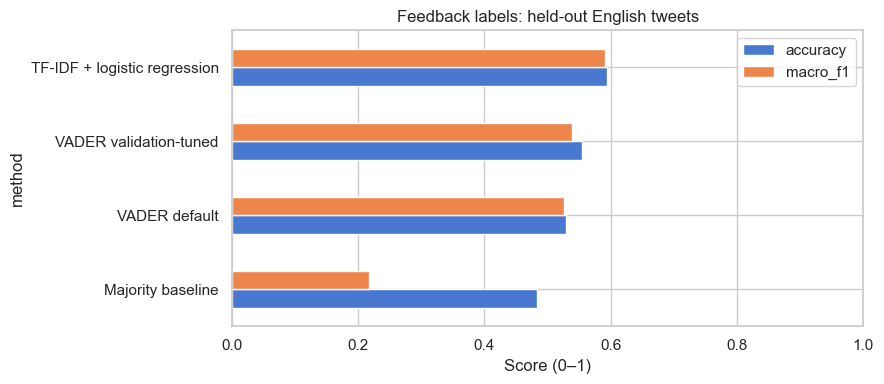

Accuracy = correct labels. Macro-F1 balances missed and wrong labels across all three groups.


In [45]:
# Pin the dataset version so reruns use the same source.
TWEET_SOURCE = {'dataset': 'TweetEval sentiment / SemEval-2017 Task 4', 'repository': 'https://github.com/cardiffnlp/tweeteval', 'revision': '4fbd22cd78421f05b1ecdb4fc5725bc7a7bd8f66', 'use': 'external English sentiment benchmark, not evidence of performance on Kenyan app feedback'}
tweet_folder = DATA / 'sentiment'
tweet_folder.mkdir(exist_ok=True)
(tweet_folder / 'source.json').write_text(json.dumps(TWEET_SOURCE), encoding='utf-8')
app_sentiment, tone_metrics = sentiment_benchmark(DATA, RESULTS)
display(pd.read_json(RESULTS / 'sentiment_data_audit.json').T[['original','used']])
display(tone_metrics[['method','accuracy','macro_f1']].round(3))
tone_metrics.set_index('method')[['accuracy','macro_f1']].plot.barh(figsize=(9,4))
plt.xlim(0,1); plt.xlabel('Score (0–1)'); plt.title('Feedback labels: held-out English tweets')
plt.tight_layout(); plt.show()
print('Accuracy = correct labels. Macro-F1 balances missed and wrong labels across all three groups.')

## 5.4 Save the complete backend files

Save the word index, semantic vectors, skill rules and trained feedback classifier together. Save the pretrained encoder alongside them. The backend loads this exact format; it does not retrain on the phone. Our earlier CV classifier is retained as a separate research model because it does not control live job ranking.

In [46]:
app_bundle = {'schema_version':2, 'retriever':app_retriever,
    'job_vectors':app_word_vectors, 'semantic_vectors':app_vectors,
    'jobs':app_jobs, 'job_skills':app_job_skills, 'lexicon':app_lexicon,
    'sentiment':app_sentiment}
joblib.dump(app_bundle, ARTIFACTS / 'upshift_bundle.joblib', compress=3)
app_encoder.save(str(ARTIFACTS / 'semantic_encoder'))
deployment = {'schema_version':2, 'selected_method':'semantic',
              'independent_human_review':False, 'sentiment_optional':True,
              'catalogue_status':'historical_research_not_live'}
(ARTIFACTS / 'deployment_config.json').write_text(json.dumps(deployment, indent=2))
shutil.copytree(APP_WORK / 'upshift_ai', ARTIFACTS / 'upshift_ai', dirs_exist_ok=True,
                ignore=shutil.ignore_patterns('__pycache__'))
app_service = ModelService(ARTIFACTS)
app_service.prepare()
print('Complete backend model saved and loaded successfully.')

Complete backend model saved and loaded successfully.


## 5.5 Try the actual app prediction function

These jobs and profiles are fictional. Compare a Python profile with an Android profile, then add evidence of Git and Docker. The same function supplies the backend's ranked jobs and skill explanations. Similarity describes related text, not the chance of being hired.

Embedding 3 documents in 3 sampled chunks


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00,  5.54it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00,  5.51it/s]

Embedding 3 documents in 3 sampled chunks


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 28.37it/s]

,Profile,Job,Similarity,Skills found,Skills to check
0,Python student,Python Software Intern,0.743211,"SQL, Python","Docker, Git"
1,Python student,Android Developer Intern,0.262382,,"Android, Firebase, Git, Kotlin"
2,Android student,Android Developer Intern,0.696548,"Android, Firebase, Git, Kotlin",
3,Android student,Python Software Intern,0.280267,Git,"SQL, Python, Docker"


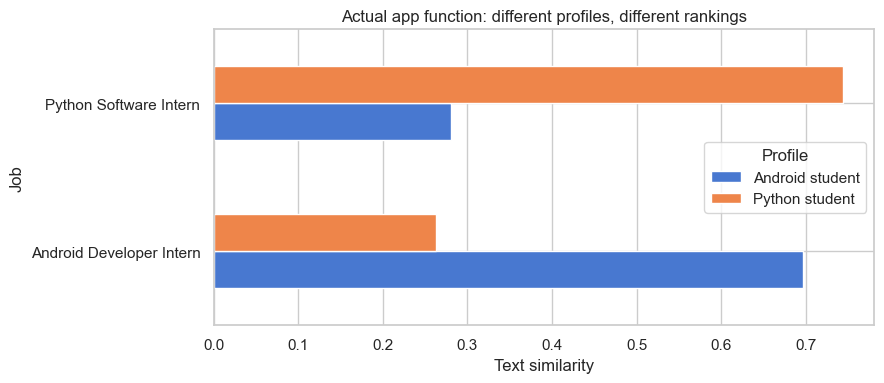

Embedding 3 documents in 3 sampled chunks


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 23.65it/s]

After adding demonstrated Git and Docker skills, the listed Python-role gaps are cleared.


In [47]:
demo_jobs = [
 {'job_id':'demo-python', 'title':'Python Software Intern', 'company_name':'Demo Employer',
  'description':'Build Python APIs, write SQL queries and test backend applications.',
  'requirements':['Python, SQL, Git and Docker are required.']},
 {'job_id':'demo-android', 'title':'Android Developer Intern', 'company_name':'Demo Employer',
  'description':'Build Android mobile applications using Kotlin and Firebase.',
  'requirements':['Kotlin, Android, Firebase and Git are required.']}]
demo_profiles = {
 'Python student':'Year 3 computing student seeking a backend internship. Python and SQL. Built and tested a Flask API with SQL queries.',
 'Android student':'Year 3 computing student seeking a mobile internship. Kotlin, Android, Firebase and Git. Built an Android expense tracker with authentication.'}
demo_results, rows = {}, []
for name, text in demo_profiles.items():
    result = app_service.rank_vacancies(text, demo_jobs, 2)
    demo_results[name] = result
    for match in result['matches']:
        rows.append({'Profile':name, 'Job':match['title'], 'Similarity':match['similarity'],
          'Skills found':', '.join(s['label'] for s in match['matched_skills']),
          'Skills to check':', '.join(s['label'] for s in match['required_skills_not_mentioned'])})
demo_table = pd.DataFrame(rows)
display(demo_table)
demo_table.pivot(index='Job', columns='Profile', values='Similarity').plot.barh(figsize=(9,4))
plt.xlabel('Text similarity'); plt.title('Actual app function: different profiles, different rankings')
plt.tight_layout(); plt.show()
assert demo_results['Python student']['matches'][0]['job_id'] == 'demo-python'
assert demo_results['Android student']['matches'][0]['job_id'] == 'demo-android'
updated_profile = demo_profiles['Python student'] + ' Used Git and Docker in this project.'
updated_result = app_service.rank_vacancies(updated_profile, demo_jobs, 2)
python_job = next(m for m in updated_result['matches'] if m['job_id']=='demo-python')
assert not python_job['required_skills_not_mentioned']
print('After adding demonstrated Git and Docker skills, the listed Python-role gaps are cleared.')

In [48]:
checks = []
for name, text, limit in [('Blank profile',' ',2), ('Too long','x'*50001,2),
                          ('Invalid limit',demo_profiles['Python student'],0),
                          ('Boolean limit',demo_profiles['Python student'],True)]:
    try: app_service.rank_vacancies(text, demo_jobs, limit)
    except ValueError as error: checks.append({'Input':name,'Outcome':str(error)})
    else: raise AssertionError(name + ' should be rejected')
empty_result = app_service.rank_vacancies(demo_profiles['Python student'], [], 2)
assert empty_result['matches']==[] and empty_result['status']=='no_match'
checks.append({'Input':'No approved vacancies','Outcome':'No matches; no research fallback'})
display(pd.DataFrame(checks))
feedback_texts = ['I love the clear explanations and useful learning resources.',
                  'All these vacancies expired last year. This is frustrating.',
                  'The screen displays five recommendations.',
                  'The layout is nice, but all the jobs are expired and unusable.']
feedback_results = [app_service.sentiment(text) for text in feedback_texts]
display(pd.DataFrame({'Feedback':feedback_texts,'Predicted tone':[r['label'] for r in feedback_results]}))
try: app_service.sentiment(' ')
except ValueError: print('Empty feedback rejected.')
else: raise AssertionError('Empty feedback should be rejected')
print('These authored messages demonstrate behaviour; they are not an independent evaluation set.')

,Input,Outcome
0,Blank profile,"Provide 1 to 50,000 characters of CV text."
1,Too long,"Provide 1 to 50,000 characters of CV text."
2,Invalid limit,top_k must be 1 to 20.
3,Boolean limit,top_k must be 1 to 20.
4,No approved vacancies,No matches; no research fallback


,Feedback,Predicted tone
0,I love the clear explanations and useful learn...,positive
1,All these vacancies expired last year. This is...,negative
2,The screen displays five recommendations.,neutral
3,"The layout is nice, but all the jobs are expir...",positive


Empty feedback rejected.
These authored messages demonstrate behaviour; they are not an independent evaluation set.


## 5.6 Check the saved files and hand over

Reloading must preserve rankings, skill explanations and feedback predictions. The complete package includes the code needed to read the model; no project Python file has to be downloaded separately to run this notebook. Only load trusted model files.

Independent human relevance and skill reviews remain pending. Neither the rough field check nor the feedback benchmark proves better employment outcomes.

In [49]:
reloaded_app = ModelService(ARTIFACTS)
reloaded_app.prepare()
for text in list(demo_profiles.values()) + [updated_profile]:
    assert reloaded_app.rank_vacancies(text, demo_jobs, 2) == app_service.rank_vacancies(text, demo_jobs, 2)
for text in feedback_texts:
    assert reloaded_app.sentiment(text) == app_service.sentiment(text)

app_examples = {'profiles':demo_profiles, 'jobs':demo_jobs,
    'updated_profile':updated_profile, 'results':demo_results, 'updated_result':updated_result,
    'feedback_texts':feedback_texts, 'feedback_results':feedback_results}
(RESULTS / 'app_examples.json').write_text(json.dumps(app_examples, indent=2))
manifest = {'schema_version':2, 'method':'semantic', 'seed':42,
            'pretrained_encoder':MODEL_ID, 'encoder_revision':MODEL_REVISION,
            'encoder_fine_tuned':False,
            'raw_data_sha256':{Path(p).name:fingerprint(p) for p in [RESUME_PATH,JOBS_PATH,SKILLS_PATH]},
            'independent_human_review':False}
(ARTIFACTS / 'metadata.json').write_text(json.dumps(manifest, indent=2))
shutil.make_archive(str(APP_WORK / 'UpShift_Complete_Model'), 'zip', ARTIFACTS)
print('PASS: saved and reloaded app predictions agree.')
print('Handoff: upshift_bundle.joblib, deployment_config.json, semantic_encoder/ and upshift_ai/.')
print('ZIP:', APP_WORK / 'UpShift_Complete_Model.zip')

Embedding 3 documents in 3 sampled chunks


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 21.11it/s]

Embedding 3 documents in 3 sampled chunks


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 29.98it/s]

... (9 outputs left out)

Embedding 3 documents in 3 sampled chunks


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 21.15it/s]

PASS: saved and reloaded app predictions agree.
Handoff: upshift_bundle.joblib, deployment_config.json, semantic_encoder/ and upshift_ai/.
ZIP: C:\Users\HAFSA\OneDrive - Strathmore University\Documents\ChatGPT\uplift\output\complete_live_notebook_validation\UpShift_Final_Output\live_app\UpShift_Complete_Model.zip


## 5.7 Compare with the existing app

The reference results below were recorded through the existing backend using the same fictional inputs. Check job order, scores, skills and feedback predictions against them. Small numerical differences up to 0.000001 are allowed.

The separate backend check also passed 20 cases covering research and live ranking, invalid requests, empty results, skill rules and feedback. This verifies compatibility with the current app model; it is not a claim of recommendation accuracy.

In [2]:
# Recorded outputs from the existing backend, not invented expected scores.
expected_matches = pd.DataFrame([{'Profile': 'Python student',
  'Job': 'Python Software Intern',
  'Similarity': 0.743211,
  'Skills found': 'SQL, Python',
  'Skills to check': 'Docker, Git'},
 {'Profile': 'Python student',
  'Job': 'Android Developer Intern',
  'Similarity': 0.262382,
  'Skills found': '',
  'Skills to check': 'Android, Firebase, Git, Kotlin'},
 {'Profile': 'Android student',
  'Job': 'Android Developer Intern',
  'Similarity': 0.696548,
  'Skills found': 'Android, Firebase, Git, Kotlin',
  'Skills to check': ''},
 {'Profile': 'Android student',
  'Job': 'Python Software Intern',
  'Similarity': 0.280267,
  'Skills found': 'Git',
  'Skills to check': 'SQL, Python, Docker'}])
pd.testing.assert_frame_equal(demo_table.reset_index(drop=True), expected_matches,
                              check_dtype=False, rtol=0, atol=1e-6)
expected_feedback = [{'label': 'positive',
  'classes': ['negative', 'neutral', 'positive'],
  'probabilities': [0.023164382105880753, 0.06914988442580586, 0.9076857334683135],
  'vader_label': 'positive',
  'vader_compound': 0.8658},
 {'label': 'negative',
  'classes': ['negative', 'neutral', 'positive'],
  'probabilities': [0.5024613590069169, 0.28162216989399574, 0.21591647109908726],
  'vader_label': 'negative',
  'vader_compound': -0.4404},
 {'label': 'neutral',
  'classes': ['negative', 'neutral', 'positive'],
  'probabilities': [0.34517894408331457, 0.5310537637268692, 0.12376729218981629],
  'vader_label': 'neutral',
  'vader_compound': 0.0},
 {'label': 'positive',
  'classes': ['negative', 'neutral', 'positive'],
  'probabilities': [0.19124186155907977, 0.0322946390395163, 0.7764634994014039],
  'vader_label': 'neutral',
  'vader_compound': 0.2263}]
for actual, expected in zip(feedback_results, expected_feedback):
    assert actual['label'] == expected['label']
    assert actual['vader_label'] == expected['vader_label']
    np.testing.assert_allclose([actual['logistic_probabilities'][c] for c in expected['classes']],
                               expected['probabilities'], rtol=0, atol=1e-6)
    assert abs(actual['vader_compound'] - expected['vader_compound']) <= 1e-6
display(pd.DataFrame({'Check':['Job order and scores','Skill explanations','Feedback predictions'],
                      'Result':['Matches existing app']*3}))
print('PASS: this notebook reproduces the recorded app results.')

,Check,Result
0,Job order and scores,Matches existing app
1,Skill explanations,Matches existing app
2,Feedback predictions,Matches existing app


PASS: this notebook reproduces the recorded app results.


# 6. Chatbot and other guidance in the Android app

The notebook above includes the trained models and the complete Python prediction code. The app also has guided features written in Kotlin. They use rules and saved information; they are not additional trained models.

| Feature | How it works | Code in this notebook |
|---|---|---|
| Job ranking in For you | A pretrained text model compares meanings. | Sections 4–5 |
| CV category classification | Classifiers learn career categories from labelled CVs. | Section 3 |
| Feedback tone | Logistic regression learns labels; VADER provides a rule-based comparison. | Section 5.3 |
| Required and optional skill explanations | Rules check names, context and negation. | Section 5.1 |
| Browse percentage | Count listed job skills present in the profile. | Kotlin below |
| Growth path and courses | Prioritise missing skills and look up a course in a fixed list. | Kotlin below |
| Guided chatbot | Recognise question keywords and personalise a prepared reply using the profile and selected role. | Kotlin below |

The CV builder fills a document template from form entries; it is not a text-generation model.

## Guided chatbot

The coach checks the selected role, finds its missing skills and passes that context to the reply function. It answers supported career topics. It does not call a conversational language model and may not understand complex or unrelated questions.

**Actual Kotlin code:** this runs in Android. The code blocks here are for review and do not execute in a Python cell.

```kotlin
interface CoachRepository { fun reply(question: String, role: Role?, state: AppState): String }
class LocalCoachRepository : CoachRepository {
    override fun reply(question: String, role: Role?, state: AppState): String {
        val target = role ?: state.rankedRoles().firstOrNull()
        val namedRole = state.rankedRoles().firstOrNull { question.contains(it.title, true) || question.contains(it.company, true) }
        val selected = namedRole ?: target
        return careerReply(question, selected, selected?.let { state.gaps(it) }.orEmpty(), selected?.let { state.score(it) }, state.profile)
    }
}
```

```kotlin
package ke.upshift.app

/** Local guidance: no conversational model or hiring predictions. */
internal fun careerReply(question: String, role: Role?, gaps: List<String>, score: Int?, profile: StudentProfile): String {
    val q = question.lowercase().replace(Regex("[^a-z0-9 ]"), " ")
    fun has(vararg words: String) = words.any { Regex("\\b${Regex.escape(it)}\\b").containsMatchIn(q) }
    val title = role?.title ?: "your target role"
    val skill = LearningLibrary.firstOrNull { q.contains(it.skill.lowercase()) }
    return when {
        has("hello", "hi", "hey") -> "Hi ${profile.name.substringBefore(' ').ifBlank { "there" }}! Ask about a role, a missing skill, courses, your CV or applying. I use your saved profile and role requirements."
        has("thank", "thanks") -> "You're welcome. Choose one small next step and save your progress in Growth."
        has("eligible", "eligibility", "qualify", "qualified", "requirements") -> role?.let { "For ${it.title}: ${it.eligibility.joinToString("; ")}. Check the full requirements and deadline on the role page; the employer decides eligibility." } ?: "Open a role first so I can show its eligibility requirements."
        has("cv", "resume", "experience") -> "For $title, include education, demonstrable skills and projects. ${if(profile.projects.isBlank()) "Add a coursework or personal project: describe your contribution and result." else "Use a project from your profile and describe what you built, your contribution and how you checked it."} You → Build your CV lets you preview and save a PDF. Never invent experience."
        has("cost", "free", "afford", "expensive", "certificate", "certification", "coursera", "udemy") -> "Growth links to recognised course providers. Check the provider's current price, certificate fee and financial-aid options before enrolling. Free study access does not always include a free certificate."
        has("apply", "application", "deadline") -> role?.let { "Open ${it.title}, check requirements and availability, then use its application link. Tailor your CV to skills you can demonstrate. ${if(it.deadline.isNotBlank()) "Listed deadline: ${it.deadline}." else "Confirm the closing date on the employer's site."} Upshift does not submit applications for you." } ?: "Open a role to review its requirements and application link."
        has("learn", "learning", "next", "week", "gap", "gaps", "improve", "study") || skill != null -> {
            val step = skill ?: LearningLibrary.firstOrNull { it.skill in gaps }
            if(step != null) "For ${step.skill}: ${step.brief} Find its course in Growth, then save a reflection or project as evidence. ${if(step.skill in gaps) "This is a gap listed for $title." else "Check whether this skill supports your chosen role."}"
            else if(gaps.isNotEmpty()) "For $title, start with ${gaps.first()}. Review the requirement, find introductory learning and practise it in a small project."
            else "No listed skill gaps for $title are available here. Choose a role, check eligibility and strengthen a project example; matching skills does not guarantee a job."
        }
        has("score", "percentage", "percent", "match", "matches", "why", "fit") -> if(role == null || score == null) "Add your skills in You, then open a role to compare its listed skills with your profile." else "$title: $score% listed-skills coverage. ${if(gaps.isEmpty()) "Your profile includes all its listed skills." else "Skills not listed in your profile: ${gaps.joinToString()}."} This circle is skills coverage, not hiring probability. For you uses a separate text-similarity model."
        has("job", "jobs", "internship", "internships", "recommendations") -> "Browse shows role requirements and skills coverage. For you compares your profile with active vacancies; complete your skills, education and projects first. Check employer eligibility before applying."
        else -> "I couldn't identify a career question in that message. I'm a guided helper, not an open-ended AI chat. Try ‘How do I learn SQL?’, ‘Am I eligible?’, ‘Help with my CV’ or ‘Explain my match’."
    }
}
```

## Skills percentage and learning progress

The Browse circle is **listed-skills coverage**, not a hiring probability or the meaning-based score. Adding a confirmed, self-reported skill updates the profile and this calculation. Saving progress only leaves the skills unchanged. The app clears old recommendation results so the next request uses the updated profile. Completing a course does not verify a certificate.

```kotlin
data class StudentProfile(val name: String = "", val email: String = "", val phone: String = "", val education: String = "", val skills: String = "", val summary: String = "", val projects: String = "", val experience: String = "", val location: String = "", val goal: String = "Internship") {
    private val normalisedSkills by lazy { skills.split(",").map { it.trim().lowercase() }.filter { it.isNotEmpty() }.toSet() }
    fun skillSet() = normalisedSkills
    fun withSkill(skill: String): StudentProfile {
        val added = skill.trim()
        if (added.isEmpty() || added.lowercase() in skillSet()) return this
        return copy(skills = listOf(skills.trim().trimEnd(','), added).filter { it.isNotBlank() }.joinToString(", "))
    }
}
interface MatchScorer { fun percentage(role: Role, profile: StudentProfile): Int? }
class SkillCoverageScorer : MatchScorer {
    override fun percentage(role: Role, profile: StudentProfile): Int? {
        if (profile.skillSet().isEmpty() || role.skills.isEmpty()) return null
        return (100.0 * role.skills.count { it.lowercase() in profile.skillSet() } / role.skills.size).roundToInt()
    }
}
```

The app uses the following functions to find gaps, prioritise learning and record the student's confirmation:

```kotlin
fun score(role: Role) = scorer.percentage(role, profile)
    fun rankedRoles() = roles.sortedWith(compareByDescending<Role> { score(it) ?: -1 }.thenBy { it.title })
    fun gaps(role: Role) = role.skills.filter { it.lowercase() !in profile.skillSet() }
    fun growthSteps(): List<LearningStep> {
        val targets = targetId?.let { id -> roles.filter { it.id == id } }?.takeIf { it.isNotEmpty() } ?: roles
        val needed = targets.flatMap { gaps(it) }.toSet()
        return LearningLibrary.filter { it.skill in needed || it.skill in completed }.sortedWith(compareByDescending<LearningStep> { step -> targets.count { step.skill in gaps(it) } }.thenBy { it.skill })
    }

fun recordStep(skill: String, notes: String, addToProfile: Boolean = false): Boolean {
        if (notes.trim().length !in 20..2000) { syncMessage = "Use a reflection of 20 to 2000 characters."; return false }
        if (userId != null && !cloudReady) return false
        evidence = JSONObject(evidence).apply { put(skill, notes.trim()) }.toString()
        completed = completed + skill
        val day = LocalDate.now(ZoneId.of("Africa/Nairobi")).toString()
        activityDays = activityDays + day
        prefs.edit().putString("evidence", evidence).putStringSet("completed", completed).putStringSet("activityDays", activityDays).apply()
        userId?.let { uid ->
            val item=PendingLearning(notes.trim(),true,day); pendingLearning[skill]=item; persistQueues(); sendLearning(uid,skill,item)
        }
        if (addToProfile) {
            val updated = profile.withSkill(skill)
            if (updated != profile) {
                update(updated)
                clearRecommendations()
                flushProfile()
            }
        }
        return true
    }
```

## Learning tasks and course lookup

These tasks and provider links are curated app content. They are looked up by skill; the model does not invent courses or check enrolment, completion or certificate validity.

```kotlin
data class LearningStep(val skill: String, val title: String, val brief: String, val minutes: Int = 30)
val LearningLibrary = listOf(
    LearningStep("HTML", "Build a page with a clear structure", "Create a page with a heading, navigation, main content and a labelled contact form. Explain why each element belongs there."),
    LearningStep("CSS", "Make a layout work on a small screen", "Build a card layout that adapts from a narrow phone to a desktop. Check readable text and comfortable spacing."),
    LearningStep("JavaScript", "Make a form respond to input", "Validate a small form and show useful messages. Check empty, valid and invalid inputs."),
    LearningStep("Git", "Practise a small reviewable change", "Create a branch, make one focused change and write a clear commit message. Explain how you would undo it safely."),
    LearningStep("SQL", "Find answers with joins and groups", "Create two related tables. Write a join and an aggregate query, then explain what each result means."),
    LearningStep("Python", "Clean and summarise a small dataset", "Read a CSV, handle missing values and calculate a useful summary. Record your assumptions."),
    LearningStep("Excel", "Turn a spreadsheet into a useful summary", "Clean a small table, use a formula and create a summary chart. Check the result by hand."),
    LearningStep("Statistics", "Explain an average and its limits", "Compare mean and median on a small dataset. Identify an outlier and explain its effect."),
    LearningStep("Kotlin", "Model and validate a student profile", "Write a data class and a validation function. Try empty, valid and incomplete profiles."),
    LearningStep("Android", "Build a screen that survives rotation", "Create an Android screen with editable state. Rotate the device and check that progress is preserved."),
    LearningStep("Testing", "Test a meaningful edge case", "Pick a function from a project. Test its normal behaviour, an empty input and an important boundary."),
    LearningStep("REST APIs", "Handle a request and its failure", "Sketch loading, success, empty and error states for a list fetched from an API. Explain a safe retry action."),
    LearningStep("Writing", "Write a clear opportunity summary", "Describe a project in three short paragraphs: problem, your contribution and result. Ask someone to check clarity."),
    LearningStep("Canva", "Design a readable campaign card", "Create a visual with one clear message. Check contrast, text size and a single call to action."),
    LearningStep("Figma", "Prototype one complete task", "Create a short clickable journey with an entry point, completion state and a way back."),
    LearningStep("Accessibility", "Review a screen for access barriers", "Check contrast, labels, touch targets, text resizing and screen-reader order. Record three improvements."),
    LearningStep("Research", "Run a short usability session", "Ask someone to complete one task without hints. Record where they hesitate and propose one improvement."),
    LearningStep("Networking", "Explain a connection from device to server", "Draw the path of a web request. Explain DNS, IP addresses and HTTP in your own words."),
    LearningStep("Communication", "Write a useful support response", "Respond to a sample support request with a clear question, next step and expected outcome.")
)
```

```kotlin
package ke.upshift.app

data class LearningCourse(val title:String,val provider:String,val url:String,val skills:Set<String>)
val CertificateCourses=listOf(
    LearningCourse("Google Data Analytics","Google · Coursera","https://www.coursera.org/professional-certificates/google-data-analytics",setOf("Excel","SQL","Python","Statistics")),
    LearningCourse("Meta Front-End Developer","Meta · Coursera","https://www.coursera.org/professional-certificates/meta-front-end-developer",setOf("HTML","CSS","JavaScript","Git")),
    LearningCourse("Meta Android Developer","Meta · Coursera","https://www.coursera.org/professional-certificates/meta-android-developer",setOf("Kotlin","Android","Testing","REST APIs")),
    LearningCourse("Google UX Design","Google · Coursera","https://www.coursera.org/professional-certificates/google-ux-design",setOf("Figma","Accessibility","Research")),
    LearningCourse("Google Digital Marketing & E-commerce","Google · Coursera","https://www.coursera.org/professional-certificates/google-digital-marketing-ecommerce",setOf("Writing","Canva")),
    LearningCourse("Google IT Support","Google · Coursera","https://www.coursera.org/professional-certificates/google-it-support",setOf("Networking","Communication"))
)
fun courseForSkill(skill:String)=CertificateCourses.first{skill in it.skills}
```

**Code locations:** `app/src/main/java/ke/upshift/app/CareerReply.kt`, `Data.kt` and `Courses.kt` in the mobile repository. This section copies the relevant logic from mobile commit `7d3f969`; it does not change the app.
